In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Corrección de errores de secuenciación con GENERanno

Detección y corrección de sustituciones en secuencias codificantes de *E. coli* (entrenamiento y evaluación) y *H. volcanii* (prueba fuera de dominio), tratando el ADN como un lenguaje.

**Organización del notebook**

| Parte | Secciones |
|---|---|
| Configuración | 0 |
| Carga de datos | 1 (lectura y análisis exploratorio) |
| Preprocesamiento | 1.1 (limpieza), 2 (partición), 3 (simulación de errores) y 4 (Datasets y DataLoaders) |
| Modelado | 5 (líneas base), 6 (modelo GENERanno) y 7 (entrenamiento) |
| Evaluación | 8 |
| Análisis de resultados | 9 |

El notebook está pensado para Google Colab con GPU. Los modelos entrenados, la búsqueda del n-grama y las predicciones de la evaluación se guardan en la carpeta `SAVE_ROOT` del Drive; si ya existen, el notebook los carga en lugar de recalcularlos, así que una corrida completa tarda entre 1 y 2 horas en lugar de las más de 20 horas de GPU que tomó el entrenamiento.


## 0. Configuración

Montaje del Drive, instalación de dependencias, importaciones y carpeta de resultados (`SAVE_ROOT`).

- Se fijan las versiones de `transformers` (4.57.3) y `peft` (0.13.2), y la revisión exacta de GENERanno (sección 4), porque el código del modelo depende de ellas. Torch se deja en la versión de Colab, que está compilada para su GPU.
- MMseqs2 se descarga en su última versión. Como otra versión podría agrupar los genes de forma distinta, la sección 8 verifica, antes de evaluar, que la partición sea exactamente la misma con la que se entrenaron los modelos.
- **Semillas.** Cada proceso aleatorio tiene su propia semilla fija: la partición (`SEED = 42`, sección 2), los errores de validación, prueba y arqueas (un generador de semilla fija por columna, sección 3), el orden de los lotes (`seed=42`, sección 4), el entrenamiento (`set_seed(42)`, que fija `random`, `numpy` y `torch`, sección 7), el corrector por frecuencia (una semilla por columna), el bootstrap (`seed=0`, sección 8) y la nube de palabras (`random_state=42`). Así, volver a correr el notebook produce los mismos datos y resultados.


In [ ]:
# Install dependencies (transformers 4.57.3: runs GENERanno without patches and its tokenizers has wheels for Python 3.13+) and MMseqs2; torch is left out because Colab ships one built for its CUDA (uncomment the next line to install it locally)
# %pip install -q torch
%pip install -q transformers==4.57.3 peft==0.13.2 matplotlib pandas seaborn scikit-learn biopython wordcloud
!wget -q https://mmseqs.com/latest/mmseqs-linux-avx2.tar.gz
!tar xzf mmseqs-linux-avx2.tar.gz

In [ ]:
# Imports (gc is aliased because the name gc is used by the GC-content function)
import re
import os
import json
import math
import time
import copy
import gc as pygc
import warnings
from collections import Counter
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from wordcloud import WordCloud
from Bio.Seq import Seq
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import average_precision_score

import torch
from torch import nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm
from transformers import AutoModelForMaskedLM, AutoTokenizer, get_linear_schedule_with_warmup, set_seed
from peft import LoraConfig, get_peft_model

In [ ]:
# Root folder where trained models and saved results (e.g. the n-gram search table) are stored; on Colab point it to Drive (e.g. "/content/drive/MyDrive/nlp") so they survive the session
SAVE_ROOT = "/content/drive/MyDrive/proyecto-nlp"

## 1. Carga de datos y análisis exploratorio

Se usan las secuencias codificantes (CDS) de RefSeq de *Escherichia coli* K-12 MG1655 (GCF_000005845.2), para entrenar, validar y probar, y de *Haloferax volcanii* DS2 (GCF_000025685.1), como prueba fuera de dominio: según sus autores, GENERanno no se preentrenó con arqueas, así que este genoma permite ver si el modelo aprendió patrones generales del ADN.


### 1.1 Lectura y limpieza

Se descartan las secuencias que no sirven como referencia correcta, porque el modelo aprende que la secuencia limpia es la verdad: pseudogenes, CDS parciales, CDS con excepciones de traducción, caracteres distintos de A, C, G y T, longitud que no es múltiplo de 3, codón de inicio o de parada inválido (tabla 11) y secuencias duplicadas (para que una misma secuencia no quede a la vez en entrenamiento y en prueba). Cada gen se cuenta en el primer filtro que lo descarta. Quedan 4,255 de 4,318 genes de *E. coli* y 3,873 de 4,017 de *H. volcanii*.


In [ ]:
# Valid start codons (translation table 11) and stop codons
CODONES_INICIO = {"ATG", "GTG", "TTG", "CTG", "ATT", "ATC", "ATA"}
CODONES_PARADA = {"TAA", "TAG", "TGA"}

In [ ]:
# Header fields found in the E. coli K-12 MG1655 (GCF_000005845.2) and H. volcanii DS2 (GCF_000025685.1) files: header key -> column name
CAMPOS_ENCABEZADO = {
    "gene": "gen",
    "locus_tag": "locus_tag",
    "db_xref": "db_xref",
    "protein": "proteina",
    "protein_id": "protein_id",
    "location": "ubicacion",
    "gbkey": "gbkey",
    "pseudo": "pseudo",
    "partial": "parcial",
    "exception": "excepcion",
    "transl_except": "transl_except",
}

In [ ]:
def leer_fasta(ruta):
    """
    Reads a FASTA file into (header, sequence) pairs.

    Sequence lines are joined and uppercased; blank lines are ignored.

    Parameters
    ----------
    ruta : str
        Path to the FASTA file.

    Returns
    -------
    registros : list of tuple of (str, str)
        One (header, sequence) pair per record, with the header without the leading ">".
    """
    registros, encabezado, partes = [], None, []
    with open(ruta) as f:
        for linea in f:
            linea = linea.strip()
            if linea.startswith(">"):
                if encabezado is not None:
                    registros.append((encabezado, "".join(partes)))
                encabezado, partes = linea[1:], []
            elif linea:
                partes.append(linea.upper())
    if encabezado is not None:
        registros.append((encabezado, "".join(partes)))
    return registros

In [ ]:
def campo(encabezado, nombre):
    """
    Extracts the value of a [name=value] field from a FASTA header.

    According to the NCBI README, some values (e.g. protein names) may contain unescaped
    brackets, so the value ends only where the next field starts ("] [") or at the end
    of the line.

    Parameters
    ----------
    encabezado : str
        FASTA header line.
    nombre : str
        Field name, e.g. "gene" or "locus_tag".

    Returns
    -------
    valor : str or None
        Field value, or None if the header does not contain the field.
    """
    m = re.search(rf"\[{nombre}=(.*?)\](?= \[|$)", encabezado)
    return m.group(1) if m else None

In [ ]:
def gc(seq):
    """
    Computes the GC content of a sequence.

    Parameters
    ----------
    seq : str
        Nucleotide sequence.

    Returns
    -------
    gc : float
        Fraction of G and C nucleotides; 0.0 for an empty sequence.
    """
    return (seq.count("G") + seq.count("C")) / len(seq) if seq else 0.0

In [ ]:
def construir_tabla(registros):
    """
    Builds a table with one row per coding sequence and its descriptive variables.

    Each row holds the identifier, the replicon, the header fields in CAMPOS_ENCABEZADO
    (None when missing), and derived variables: strand, length, number of codons, overall
    GC content and GC content at each codon position, start and stop codons, and the
    sequence itself. Repeated sequences are flagged, keeping the first occurrence.

    Parameters
    ----------
    registros : list of tuple of (str, str)
        (header, sequence) pairs as returned by leer_fasta.

    Returns
    -------
    df : pandas.DataFrame
        One row per record, plus the boolean column "duplicado".
    """
    filas = []
    for enc, seq in registros:
        identificador = enc.split()[0]
        fila = {
            "id": identificador,
            "replicon": identificador.split("|")[1].split("_cds")[0],
        }
        for clave, columna in CAMPOS_ENCABEZADO.items():
            fila[columna] = campo(enc, clave)
        fila.update({
            "hebra": "-" if (fila["ubicacion"] or "").startswith("complement") else "+",
            "longitud": len(seq),
            "num_codones": len(seq) // 3,
            "gc": gc(seq),
            "gc_pos1": gc(seq[0::3]),
            "gc_pos2": gc(seq[1::3]),
            "gc_pos3": gc(seq[2::3]),
            "codon_inicio": seq[:3],
            "codon_parada": seq[-3:],
            "secuencia": seq,
        })
        filas.append(fila)
    df = pd.DataFrame(filas)
    df["duplicado"] = df.duplicated("secuencia", keep="first")
    return df

In [ ]:
def filtrar(df):
    """
    Removes the sequences that are not suitable for training and reports each filter.

    The filters are applied in order: pseudogenes, partial CDS, translation exceptions,
    non-ACGT characters, length not divisible by 3, invalid start codon, invalid stop
    codon and duplicated sequence. For each filter it prints how many genes it discards
    (counting each gene only in the first filter that removes it) and how many genes meet
    the condition independently of the other filters.

    Parameters
    ----------
    df : pandas.DataFrame
        Table as returned by construir_tabla.

    Returns
    -------
    df_limpio : pandas.DataFrame
        Copy of the rows that pass every filter.
    """
    filtros = {
        "pseudogen": df["pseudo"].isna(),
        "CDS parcial": df["parcial"].isna(),
        "excepción de traducción": df["excepcion"].isna() & df["transl_except"].isna(),
        "caracteres no ACGT": df["secuencia"].str.fullmatch("[ACGT]+"),
        "longitud no múltiplo de 3": df["longitud"] % 3 == 0,
        "codón de inicio inválido": df["codon_inicio"].isin(CODONES_INICIO),
        "codón de parada inválido": df["codon_parada"].isin(CODONES_PARADA),
        "secuencia duplicada": ~df["duplicado"],
    }
    mascara = pd.Series(True, index=df.index)
    print("\nGenes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):")
    for nombre, cond in filtros.items():
        indices = pd.Series(True, index=df.index)
        descartados = (mascara & ~cond).sum()
        total_condicion = (indices & ~cond).sum()
        print(f"  {nombre:<28} {descartados:>5} ---- Total: {total_condicion}")
        mascara &= cond
    return df[mascara].copy()

In [ ]:
def guardar_fasta(df, ruta):
    """
    Writes the sequences of a table to a FASTA file.

    Each header has the form ">id locus_tag=..." and sequences are wrapped at 80
    characters per line.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the columns "id", "locus_tag" and "secuencia".
    ruta : str
        Output path.
    """
    with open(ruta, "w") as f:
        for _, fila in df.iterrows():
            f.write(f">{fila['id']} locus_tag={fila['locus_tag']}\n")
            seq = fila["secuencia"]
            for i in range(0, len(seq), 80):
                f.write(seq[i:i + 80] + "\n")

In [ ]:
# Paths to the RefSeq CDS files, inside SAVE_ROOT
ruta_arqueas = os.path.join(SAVE_ROOT, "arqueas.fna")
ruta_ecoli = os.path.join(SAVE_ROOT, "ecoli.fna")

In [ ]:
# Read both genomes into tables
df_arqueas = construir_tabla(leer_fasta(ruta_arqueas))
df_ecoli = construir_tabla(leer_fasta(ruta_ecoli))
print(f"Genes arqueas leídos: {len(df_arqueas)}")
print(f"Genes E. coli leídos: {len(df_ecoli)}")

Genes arqueas leídos: 4017
Genes E. coli leídos: 4318


In [ ]:
# Inspect the archaea table
df_arqueas.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,longitud,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado
0,lcl|NC_013967.1_cds_WP_004044954.1_1,NC_013967.1,None,HVO_RS04710,GeneID:8926884,Cdc6/Cdc18 family protein,WP_004044954.1,258..1952,CDS,None,...,1695,565,0.648968,0.667257,0.378761,0.900885,ATG,TGA,ATGGACGAGGAAGAGAATCCGCGAGGCGGCGCACGAGGGGAAGCCG...,False
1,lcl|NC_013967.1_cds_WP_004044955.1_2,NC_013967.1,None,HVO_RS04715,GeneID:8926122,S26 family signal peptidase,WP_004044955.1,complement(2000..2797),CDS,None,...,798,266,0.690476,0.684211,0.526316,0.860902,GTG,TGA,GTGCTAACTCGGCTTCGGACGGCAGAGGAGGGGCCGCTTCTGTTCG...,False
2,lcl|NC_013967.1_cds_WP_004044956.1_3,NC_013967.1,None,HVO_RS04720,GeneID:8924320,DNA-directed DNA polymerase II small subunit,WP_004044956.1,2942..4543,CDS,None,...,1602,534,0.667291,0.685393,0.425094,0.891386,GTG,TGA,GTGCCACTGGAGACGCCGGCGCGCATCGTCCGGACGCTCGTCGGTC...,False
3,lcl|NC_013967.1_cds_WP_004044957.1_4,NC_013967.1,None,HVO_RS04725,GeneID:8924855,oxidoreductase,WP_004044957.1,4686..5813,CDS,None,...,1128,376,0.708333,0.723404,0.473404,0.928191,ATG,TGA,ATGACCGACGACGCGCTGTTCGACGCGACGAGCCTGAACGACCTGT...,False
4,lcl|NC_013967.1_cds_WP_013035623.1_5,NC_013967.1,None,HVO_RS04730,GeneID:8926047,ZIP family metal transporter,WP_013035623.1,complement(5936..6745),CDS,None,...,810,270,0.680247,0.670370,0.433333,0.937037,GTG,TAG,GTGACGGCGGTCGAAGAGCTGTTCGTCTCGCTCGCCGGCTCGAACC...,False


In [ ]:
# Columns of the table
df_ecoli.columns

Index(['id', 'replicon', 'gen', 'locus_tag', 'db_xref', 'proteina',
       'protein_id', 'ubicacion', 'gbkey', 'pseudo', 'parcial', 'excepcion',
       'transl_except', 'hebra', 'longitud', 'num_codones', 'gc', 'gc_pos1',
       'gc_pos2', 'gc_pos3', 'codon_inicio', 'codon_parada', 'secuencia',
       'duplicado'],
      dtype='object')

In [ ]:
# Total number of nucleotides in E. coli
sum(df_ecoli["secuencia"].apply(lambda x: len(x)))

4026887

In [ ]:
# Total number of nucleotides in archaea
sum(df_arqueas["secuencia"].apply(lambda x: len(x)))

3465867

In [ ]:
# Apply the filters to both genomes
df_ecoli_limpio = filtrar(df_ecoli)
df_arqueas_limpio = filtrar(df_arqueas)


Genes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):
  pseudogen                       18 ---- Total: 18
  CDS parcial                      0 ---- Total: 0
  excepción de traducción          6 ---- Total: 6
  caracteres no ACGT               0 ---- Total: 0
  longitud no múltiplo de 3        0 ---- Total: 1
  codón de inicio inválido         0 ---- Total: 1
  codón de parada inválido         0 ---- Total: 2
  secuencia duplicada             39 ---- Total: 39

Genes descartados por cada filtro y total de genes con esas condiciones (aplicados en orden):
  pseudogen                      120 ---- Total: 120
  CDS parcial                      0 ---- Total: 65
  excepción de traducción          2 ---- Total: 2
  caracteres no ACGT               0 ---- Total: 0
  longitud no múltiplo de 3        0 ---- Total: 51
  codón de inicio inválido         0 ---- Total: 35
  codón de parada inválido         0 ---- Total: 28
  secuencia duplicada             22 

### 1.2 Análisis exploratorio

#### Frecuencia de nucleótidos

In [ ]:
# Count the nucleotides of each genome
all_nucleotides_ecoli = "".join(df_ecoli_limpio["secuencia"].tolist())
ecoli_nucleotide_counter = Counter(all_nucleotides_ecoli)

all_nucleotides_arqueas = "".join(df_arqueas_limpio["secuencia"].tolist())
arqueas_nucleotide_counter = Counter(all_nucleotides_arqueas)

In [ ]:
def plot_nucleotides(counter, title, ax=None, x_label = "Nucleótido"):
  """
  Plots the percentage of each symbol in a counter as a bar chart.

  Bars are sorted alphabetically and labeled with their percentage.

  Parameters
  ----------
  counter : collections.Counter
      Counts per symbol (nucleotides or codons).
  title : str
      Plot title.
  ax : matplotlib.axes.Axes, optional
      Axes to draw on; a new figure is created if None.
  x_label : str, optional
      Label of the x axis.

  Returns
  -------
  fig : matplotlib.figure.Figure
      Figure that contains the plot.
  ax : matplotlib.axes.Axes
      Axes with the plot.
  """
  nucleotides_series = pd.Series(counter)
  total_nucleotides = nucleotides_series.sum()
  percentages = (nucleotides_series / total_nucleotides) * 100

  if ax is None:
      fig, ax = plt.subplots(figsize=(8, 6))
  else:
      fig = ax.figure

  percentages = percentages.sort_index()

  sns.barplot(x=percentages.index, y=percentages.values, hue=percentages.index, palette='viridis', legend=False, ax=ax)

  ax.set_title(title)
  ax.set_xlabel(x_label)
  ax.set_ylabel('Porcentaje')
  ax.set_ylim(0, max(percentages.values) * 1.1)

  for index, value in enumerate(percentages.values):
      ax.text(index, value + 0.5, f'{value:.2f}%', color='black', ha='center')

  return fig, ax

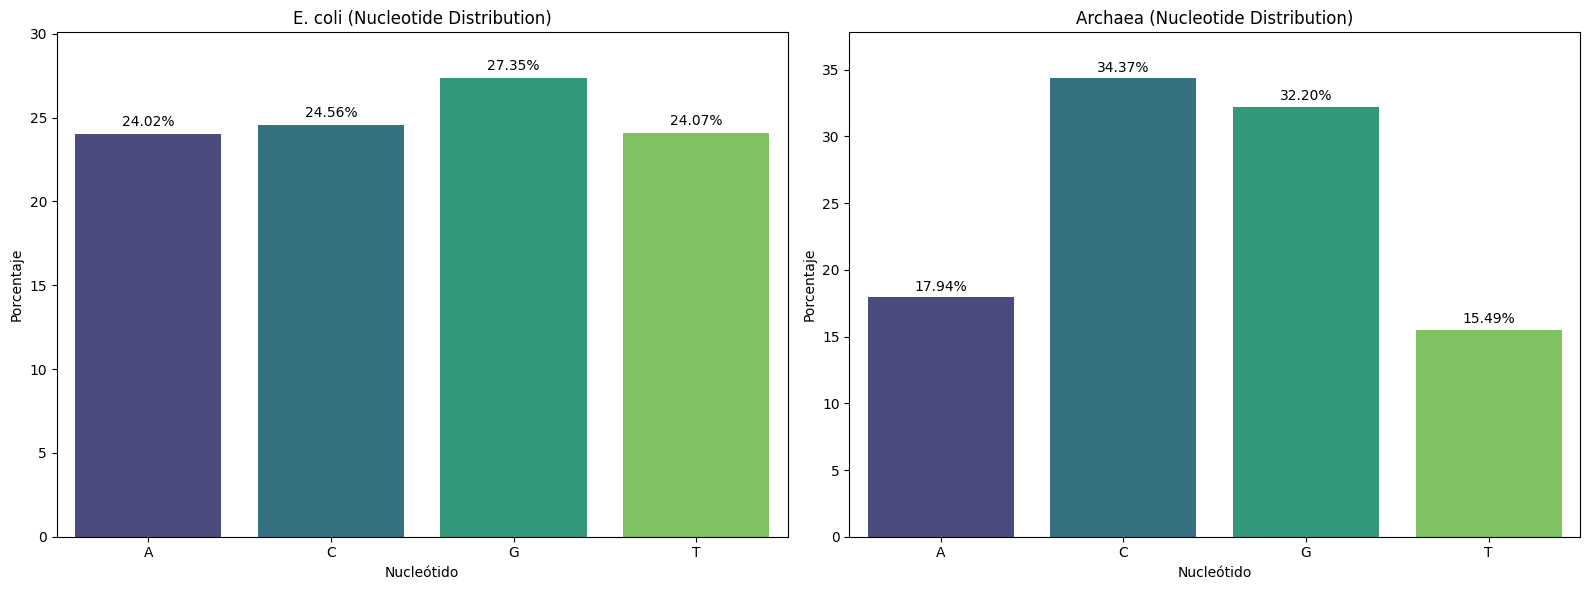

In [ ]:
# Nucleotide distribution of both genomes side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

plot_nucleotides(ecoli_nucleotide_counter, 'E. coli (Nucleotide Distribution)', ax=axes[0])
plot_nucleotides(arqueas_nucleotide_counter, 'Archaea (Nucleotide Distribution)', ax=axes[1])

plt.tight_layout()
plt.show()

#### Frecuencia por posición en el codón

In [ ]:
def calculate_freq_position(all_nucleotides):
  """
  Plots the nucleotide distribution at each of the three codon positions.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences, so that every third nucleotide
      shares the same codon position.
  """

  fig, axes = plt.subplots(1, 3, figsize=(16, 6))

  first_pos_freqs = Counter(all_nucleotides[0::3])
  second_pos_freqs = Counter(all_nucleotides[1::3])
  third_pos_freqs = Counter(all_nucleotides[2::3])

  plot_nucleotides(first_pos_freqs, "Primera posición", axes[0])
  plot_nucleotides(second_pos_freqs, "Segunda posición", axes[1])
  plot_nucleotides(third_pos_freqs, "Tercera posición", axes[2])

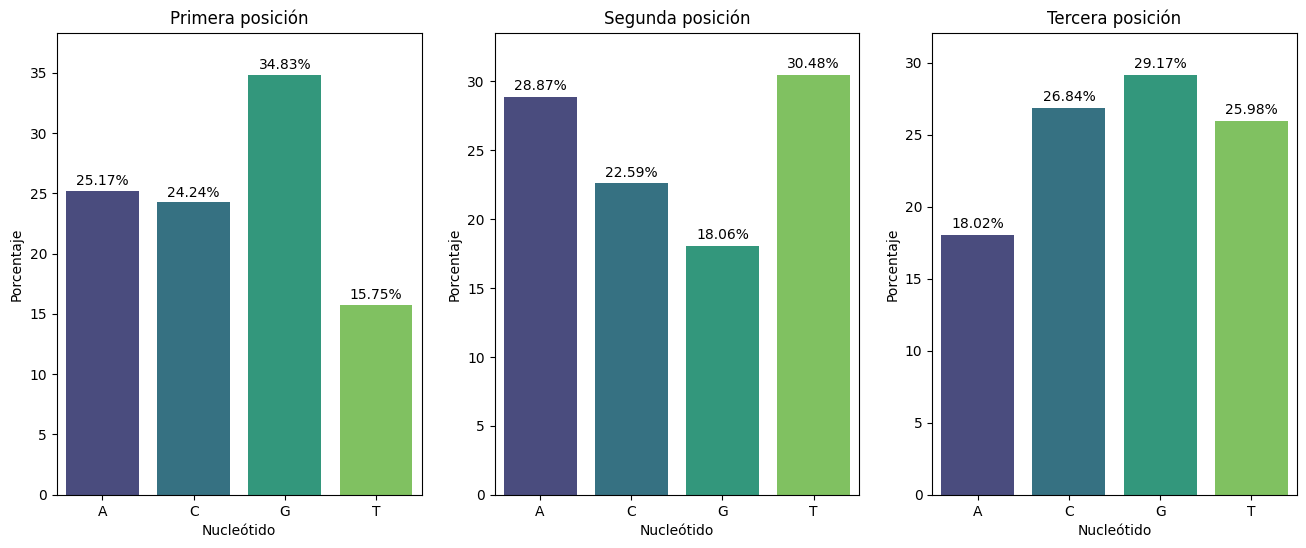

In [ ]:
# Distribution per codon position in E. coli
calculate_freq_position(all_nucleotides_ecoli)

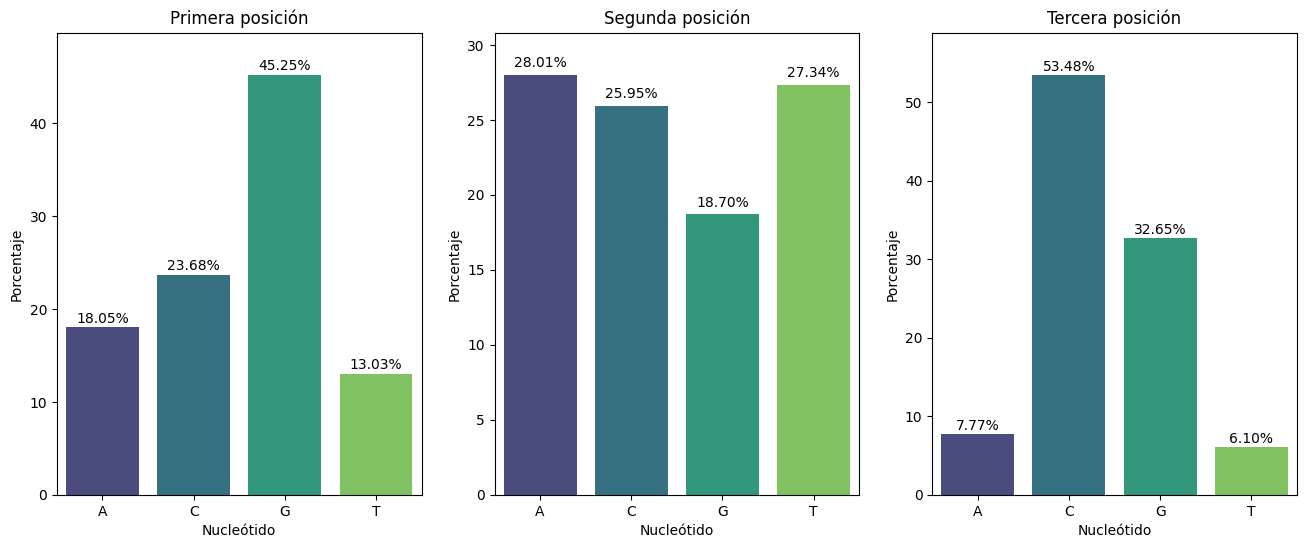

In [ ]:
# Distribution per codon position in archaea
calculate_freq_position(all_nucleotides_arqueas)

#### Frecuencia de codones

In [ ]:
def plot_codon_freq(all_nucleotides, title='Distribución de Codones (10 más frecuentes)'):
  """
  Plots a word cloud with the 10 most frequent codons.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences; codons are read every 3 nucleotides.
  title : str, optional
      Plot title.
  """
  codon_counter = Counter(all_nucleotides[i:i+3] for i in range(0, len(all_nucleotides), 3))

  top_10_codons = dict(codon_counter.most_common(10))

  wordcloud = WordCloud(width=1600, height=800, background_color='white', random_state=42).generate_from_frequencies(top_10_codons)

  plt.figure(figsize=(15, 7))
  plt.imshow(wordcloud, interpolation='bilinear')
  plt.axis('off')
  plt.title(title)
  plt.show()

In [ ]:
def plot_codon_freq_bar_chart(all_nucleotides, title='Distribución de Codones'):
  """
  Plots the percentage of every codon as a bar chart.

  Parameters
  ----------
  all_nucleotides : str
      Concatenation of in-frame coding sequences; codons are read every 3 nucleotides.
  title : str, optional
      Plot title.
  """
  fig, ax = plt.subplots(figsize=(30, 6))
  codon_counter = Counter(all_nucleotides[i:i+3] for i in range(0, len(all_nucleotides), 3))
  plot_nucleotides(codon_counter, title, ax=ax, x_label='Codón')
  plt.tight_layout()
  plt.show()

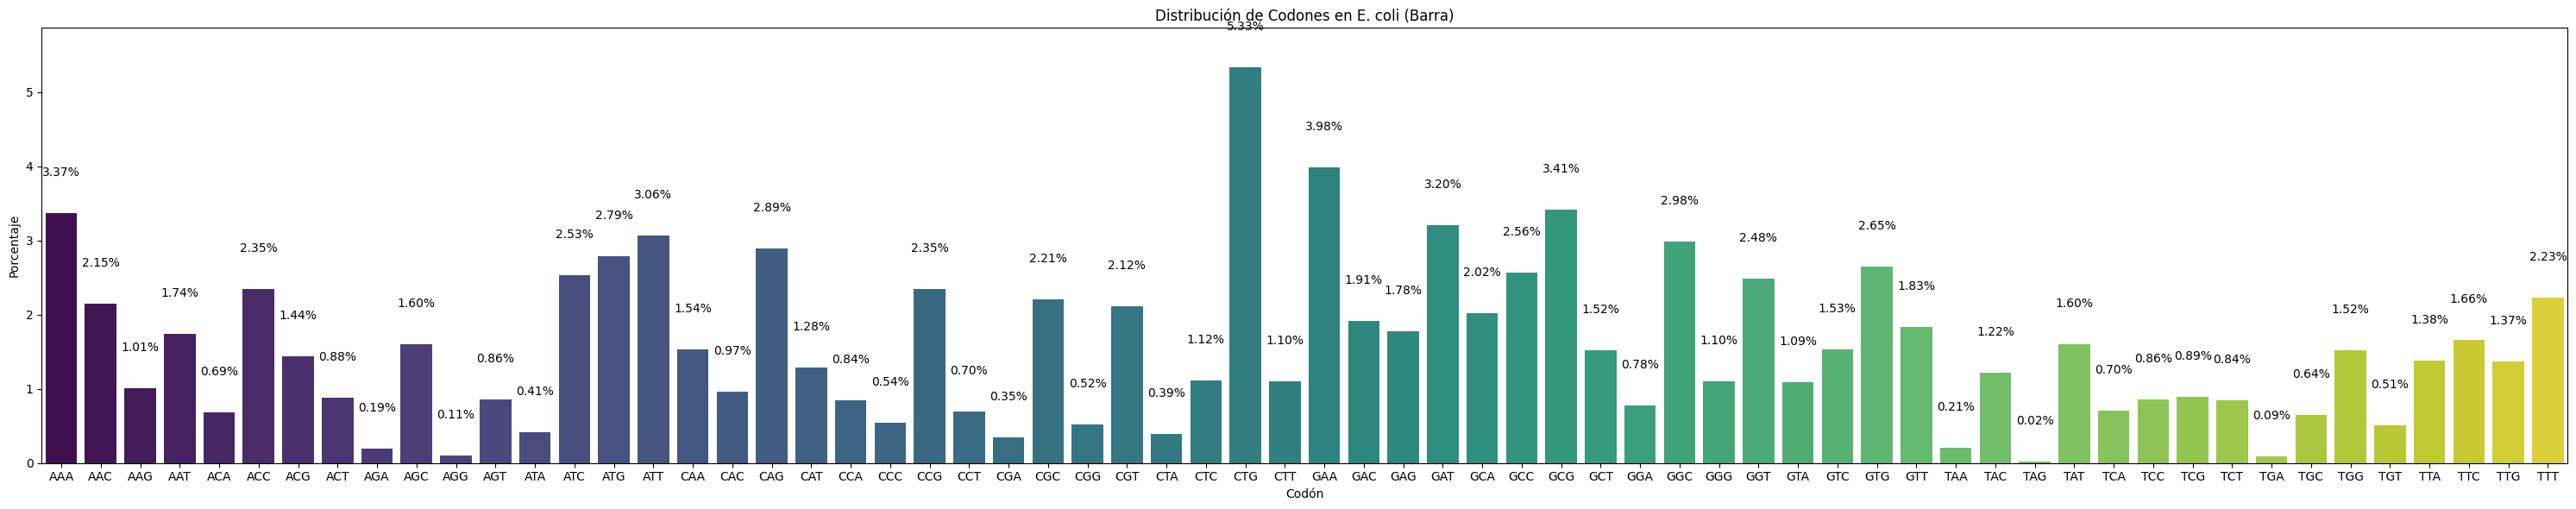

In [ ]:
# Codon frequencies in E. coli
plot_codon_freq_bar_chart(all_nucleotides_ecoli, title='Distribución de Codones en E. coli (Barra)')

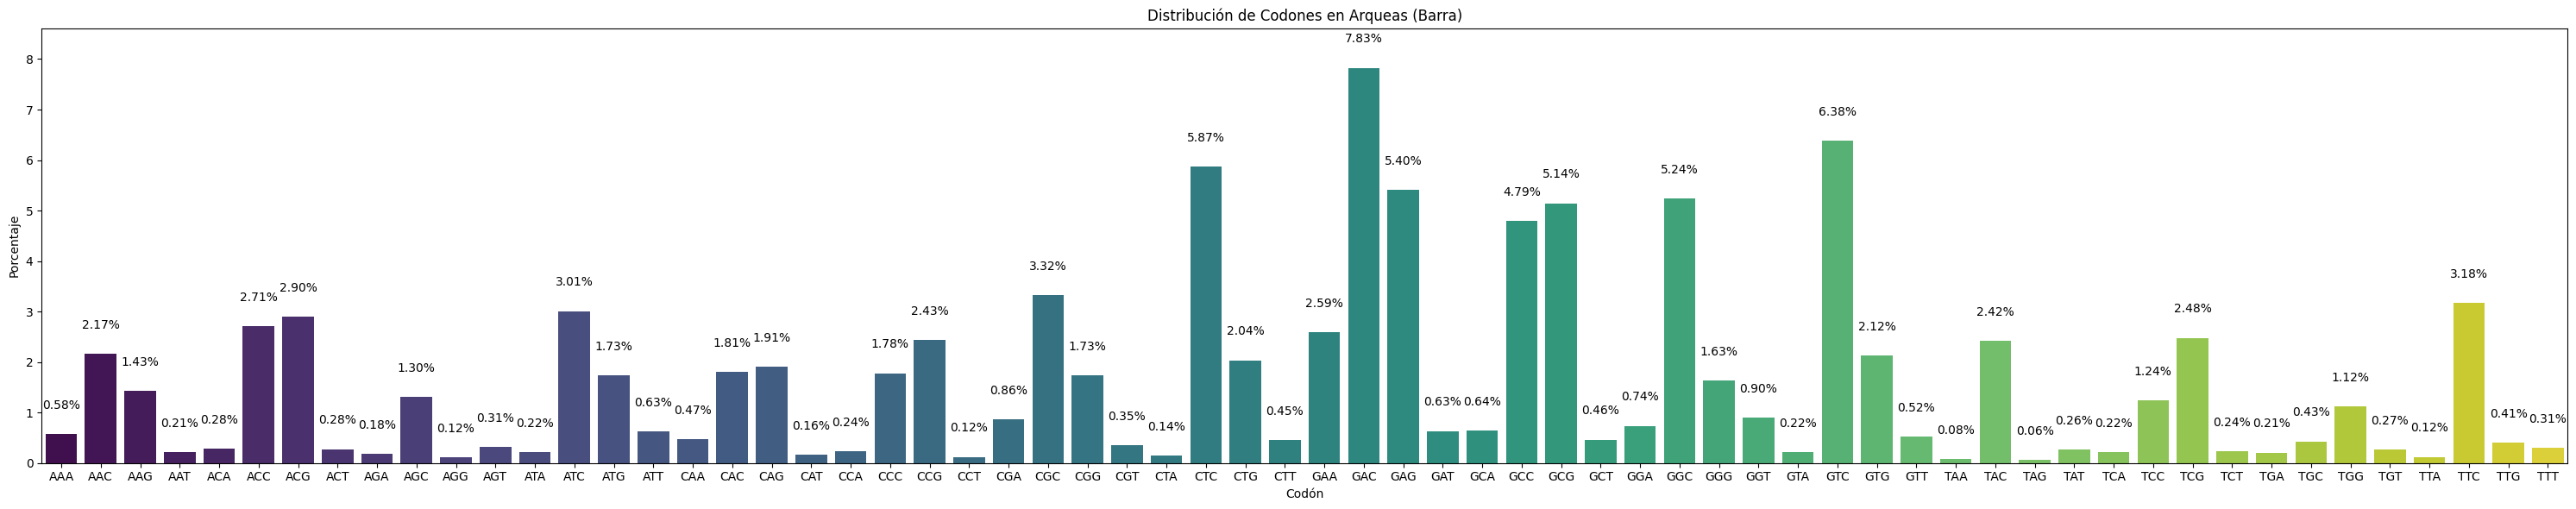

In [ ]:
# Codon frequencies in archaea
plot_codon_freq_bar_chart(all_nucleotides_arqueas, title='Distribución de Codones en Arqueas (Barra)')

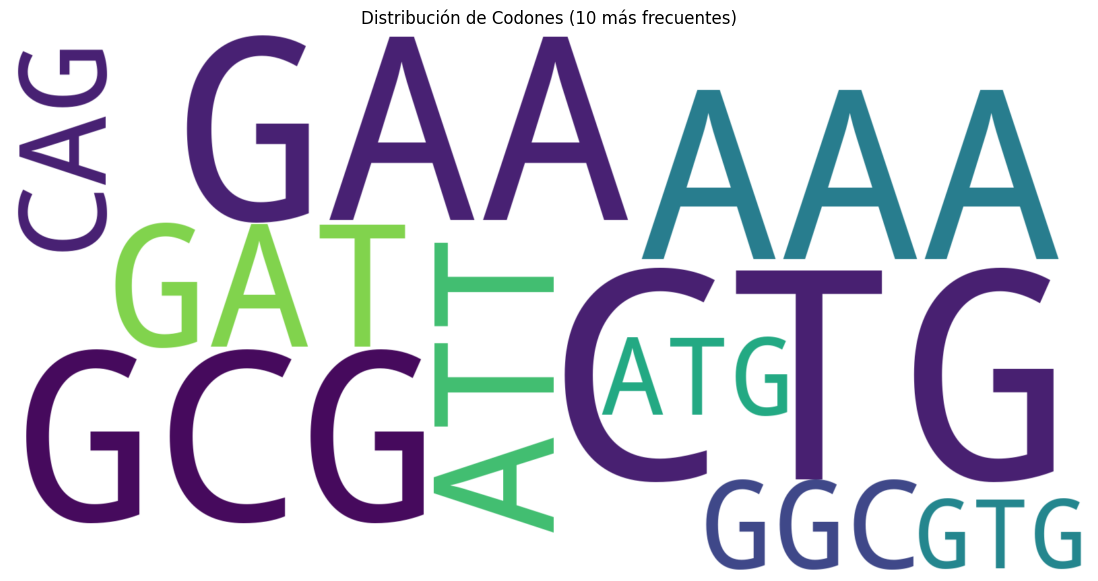

In [ ]:
# Top 10 codons in E. coli
plot_codon_freq(all_nucleotides_ecoli)

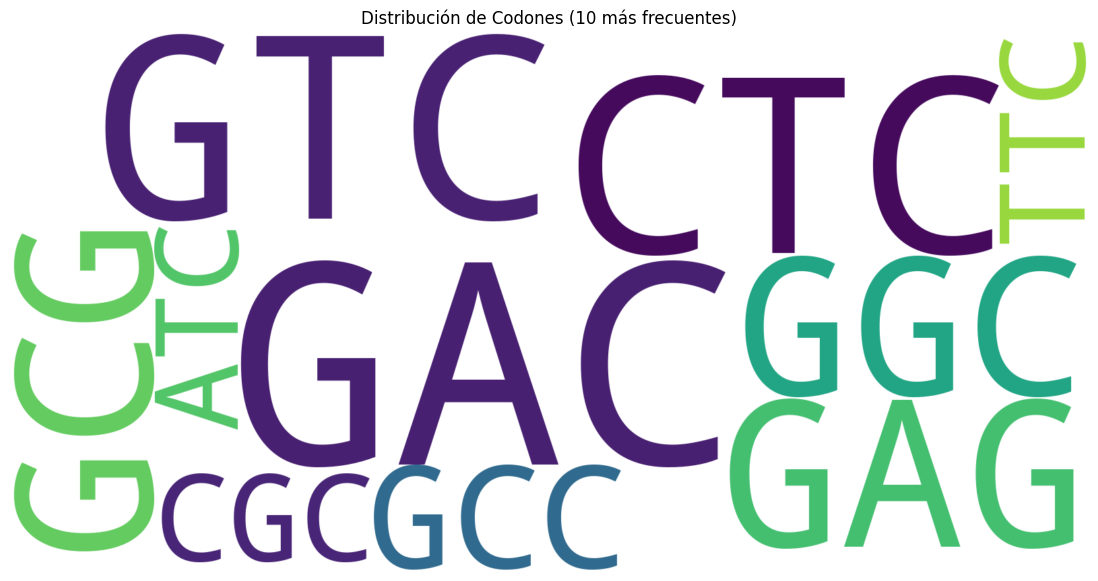

In [ ]:
# Top 10 codons in archaea
plot_codon_freq(all_nucleotides_arqueas)

#### Codones de inicio y de parada

In [ ]:
def plot_start_or_end_codon_freq(df, start, ax):
  """
  Plots the distribution of start or stop codons.

  Parameters
  ----------
  df : pandas.DataFrame
      Table with the column "secuencia".
  start : bool
      True for the first codon of each sequence, False for the last one.
  ax : matplotlib.axes.Axes
      Axes to draw on.
  """
  codon_counter = Counter(df["secuencia"].apply(lambda x: x[:3] if start else x[-3:]))
  plot_nucleotides(codon_counter, f'Distribución de Codones de {"Inicio" if start else "Fin"}', ax, x_label = "Codón")

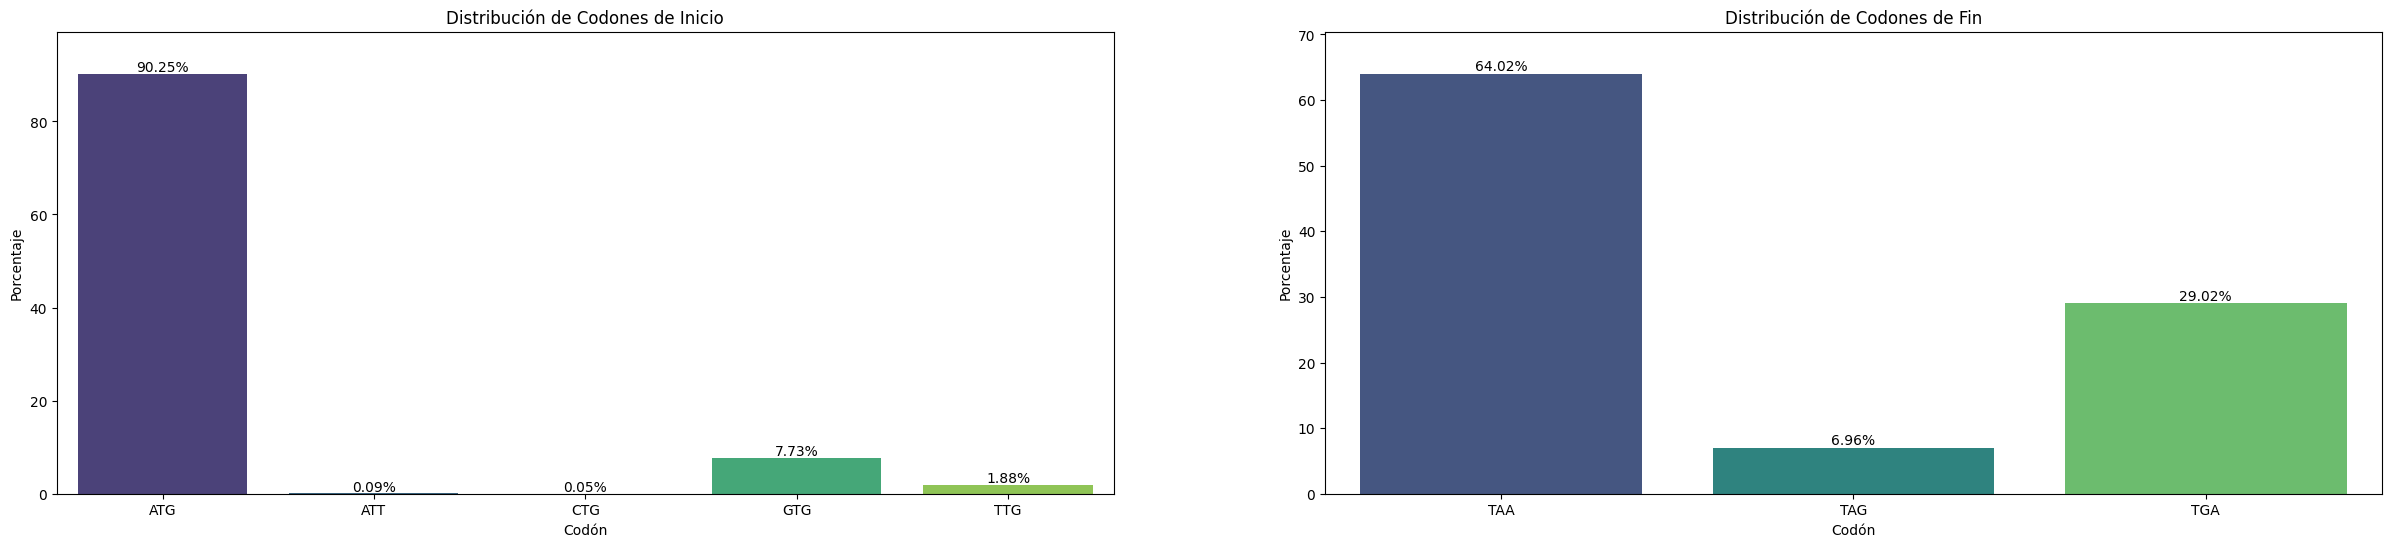

In [ ]:
# Start and stop codons in E. coli
fig, axes = plt.subplots(1, 2, figsize=(30, 6))


plot_start_or_end_codon_freq(df_ecoli_limpio, True, axes[0])
plot_start_or_end_codon_freq(df_ecoli_limpio, False, axes[1])

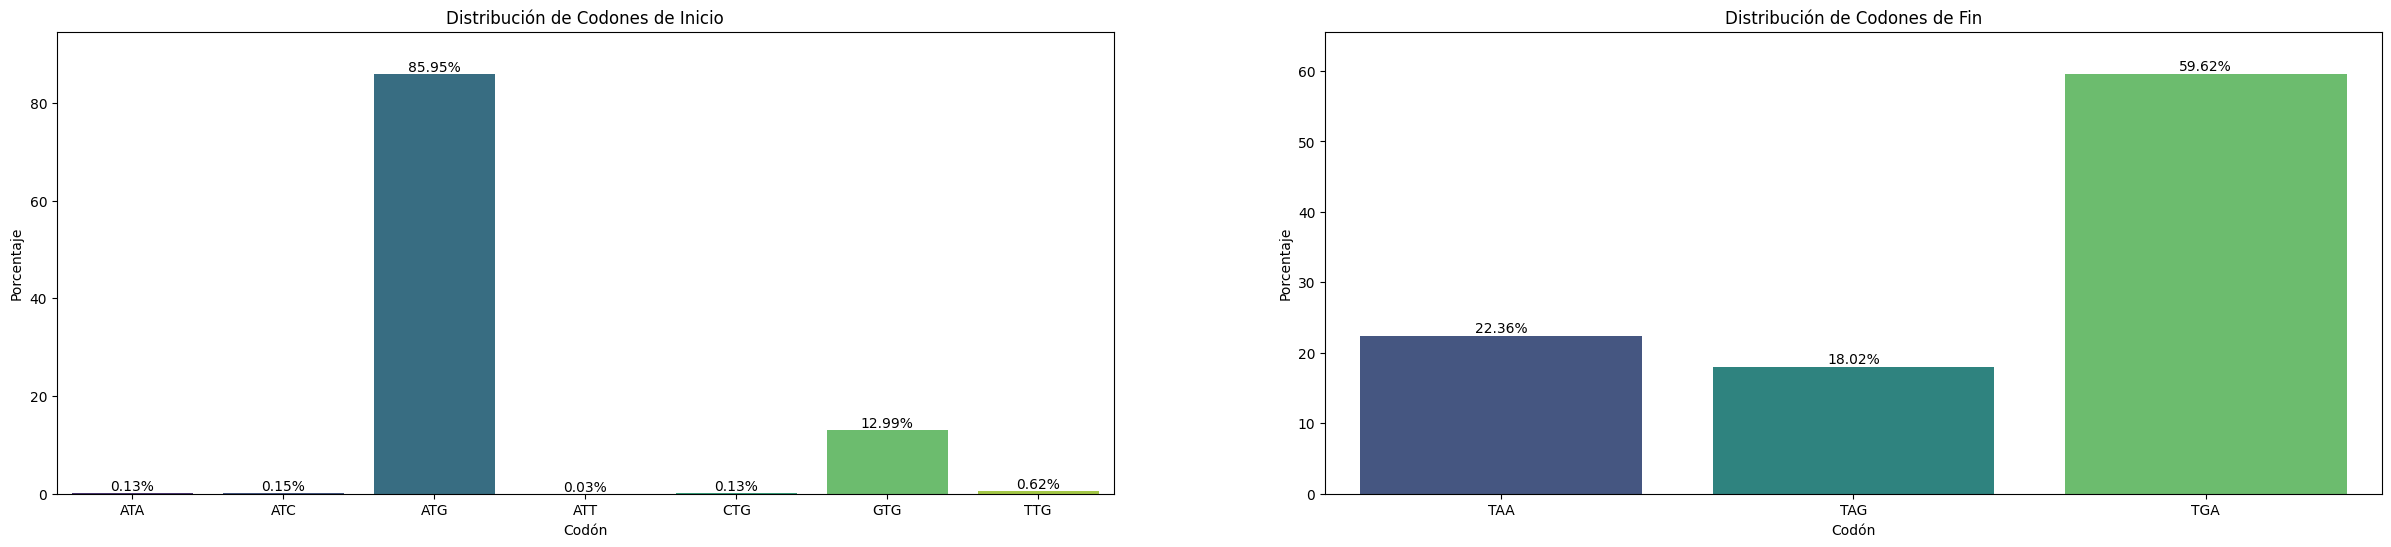

In [ ]:
# Start and stop codons in archaea
fig, axes = plt.subplots(1, 2, figsize=(30, 6))


plot_start_or_end_codon_freq(df_arqueas_limpio, True, axes[0])
plot_start_or_end_codon_freq(df_arqueas_limpio, False, axes[1])

#### Longitud de las secuencias

In [ ]:
def plot_length_histogram(df, title='Distribución de Longitud de Secuencias', x_label='Longitud de Secuencia'):
  """
  Prints the mean sequence length and plots a histogram of lengths with a KDE curve.

  Parameters
  ----------
  df : pandas.DataFrame
      Table with the column "longitud".
  title : str, optional
      Plot title.
  x_label : str, optional
      Label of the x axis.
  """
  print(df['longitud'].mean())
  plt.figure(figsize=(10, 6))
  sns.histplot(df['longitud'], kde=True, bins=30)
  plt.title(title)
  plt.xlabel(x_label)
  plt.ylabel('Frecuencia')
  plt.grid(axis='y', alpha=0.75)
  plt.show()

932.007285546416


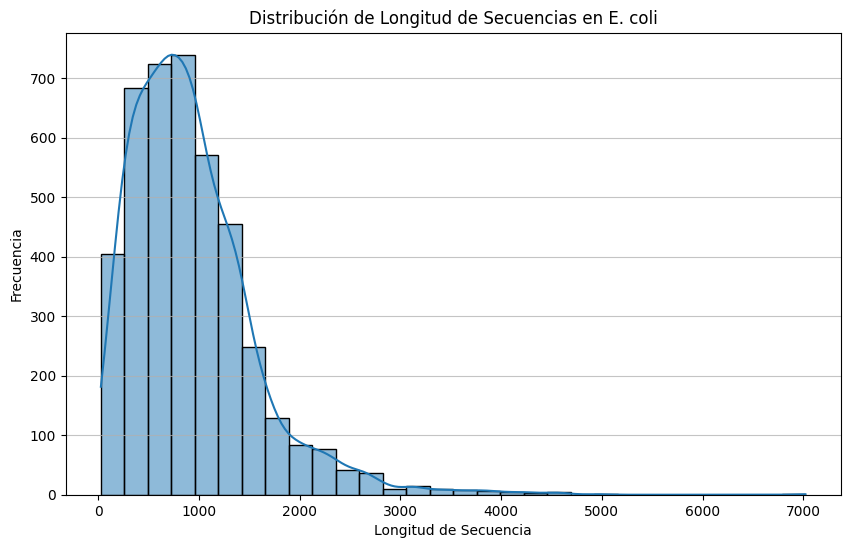

In [ ]:
# Length distribution in E. coli
plot_length_histogram(df_ecoli_limpio, title='Distribución de Longitud de Secuencias en E. coli')

866.8605731990705


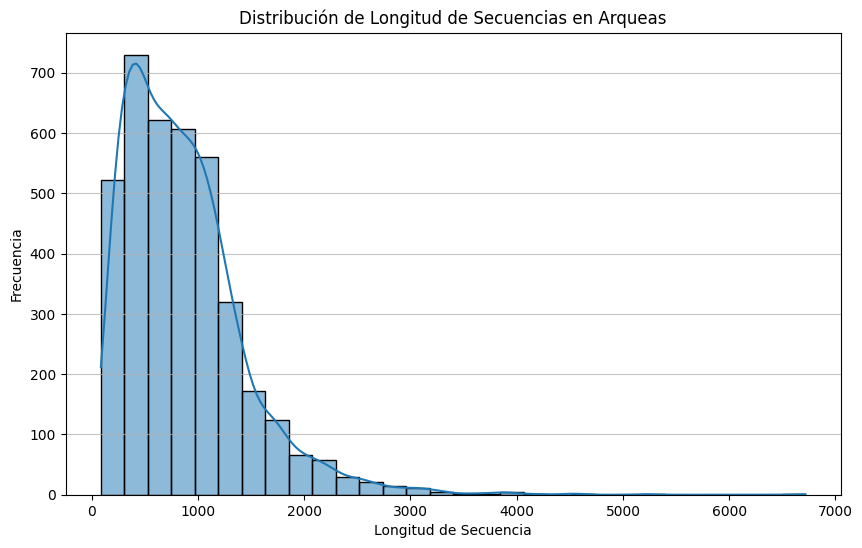

In [ ]:
# Length distribution in archaea
plot_length_histogram(df_arqueas_limpio, title='Distribución de Longitud de Secuencias en Arqueas')

#### Contenido de GC

In [ ]:
# Nucleotide counts per gene
df_ecoli_limpio["nucleotide_freq"] = df_ecoli_limpio["secuencia"].apply(lambda x: Counter(x))
df_arqueas_limpio["nucleotide_freq"] = df_arqueas_limpio["secuencia"].apply(lambda x: Counter(x))

In [ ]:
def plot_nucleotide_dispersion(df, title):
    """
    Plots GC content (%) against sequence length, one point per gene.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the columns "longitud" and "gc".
    title : str
        Plot title.
    """
    df_for_plot = df[['longitud']].copy()
    df_for_plot['GC_Porcentaje'] = df['gc'] * 100

    plt.figure(figsize=(12, 8))
    sns.scatterplot(
        data=df_for_plot,
        x='longitud',
        y='GC_Porcentaje',
        alpha=0.6,
        s=10
    )
    plt.title(title)
    plt.xlabel('Longitud de Secuencia')
    plt.ylabel('Contenido de GC (%)')
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.show()

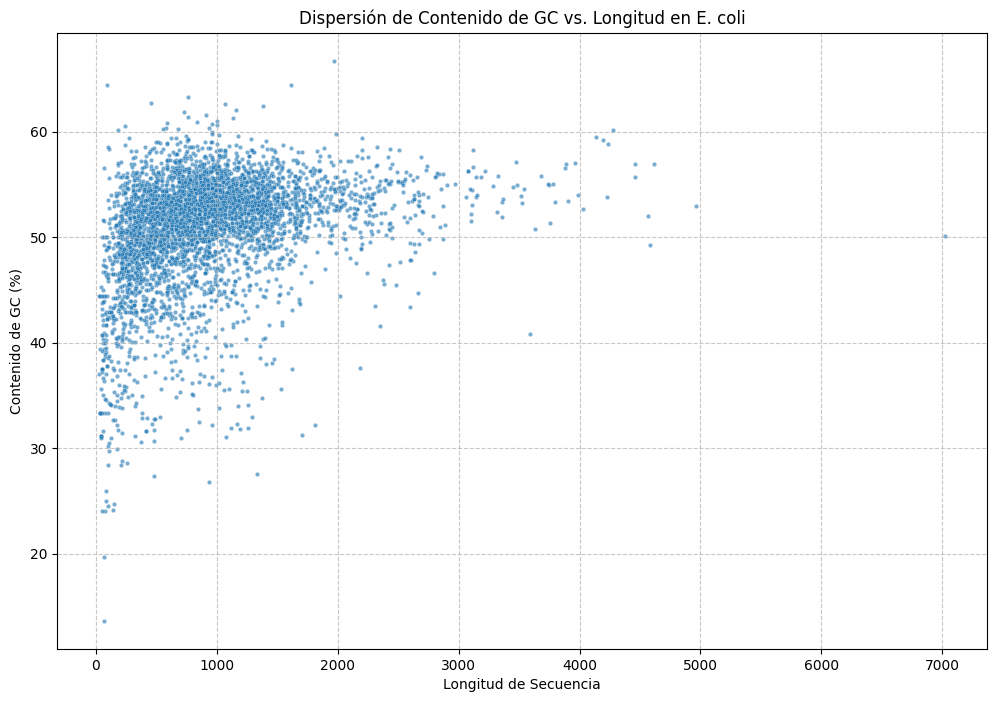

In [ ]:
# GC content vs length in E. coli
plot_nucleotide_dispersion(df_ecoli_limpio, 'Dispersión de Contenido de GC vs. Longitud en E. coli')

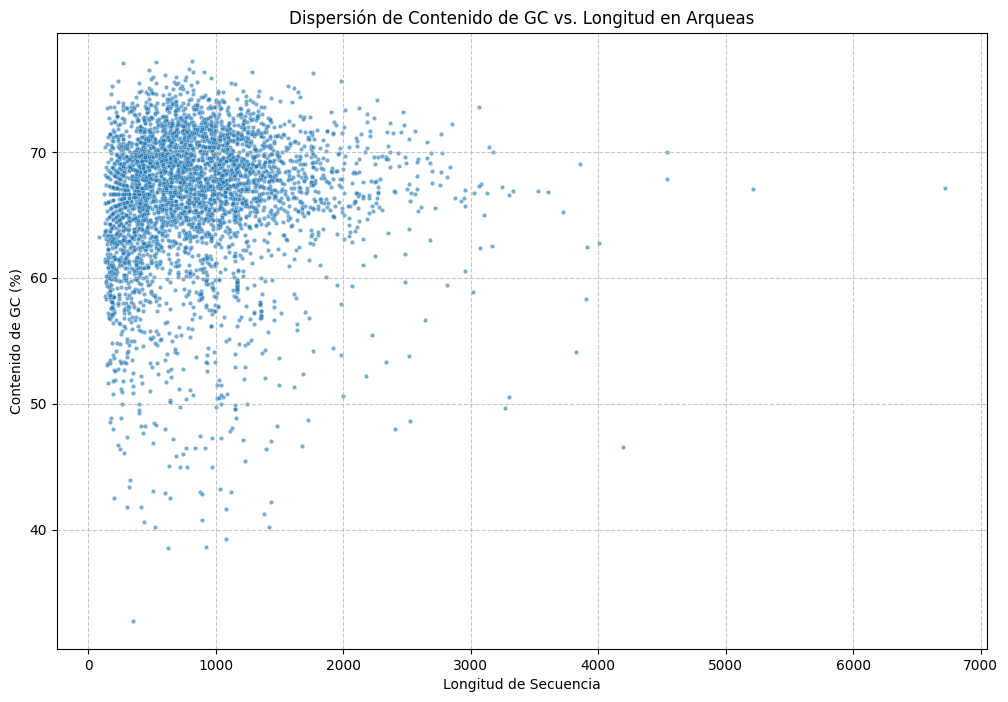

In [ ]:
# GC content vs length in archaea
plot_nucleotide_dispersion(df_arqueas_limpio, 'Dispersión de Contenido de GC vs. Longitud en Arqueas')

#### Conclusiones del análisis exploratorio

- **Composición.** En *E. coli* las cuatro bases aparecen casi por igual (A 24.0 %, C 24.6 %, G 27.4 %, T 24.1 %; GC de 51.9 %), mientras que *H. volcanii* es mucho más rica en GC (66.6 %), sobre todo en la tercera posición del codón (86.1 % frente a 56.0 % en *E. coli*). Por eso las arqueas son una prueba fuera de dominio exigente.
- **Codones.** Los codones más frecuentes son distintos (CTG en *E. coli*, GAC en *H. volcanii*), y también el codón de parada más común (TAA en el 64.0 % de los genes de *E. coli*, TGA en el 59.6 % de los de *H. volcanii*). El codón de inicio es casi siempre ATG en los dos (90.2 % y 86.0 %).
- **Longitud.** Los genes miden en promedio 932 nucleótidos en *E. coli* y 867 en *H. volcanii*; el más largo tiene 7,020, por debajo del contexto de 8,192 tokens de GENERanno, así que cada gen entra completo al modelo.
- **GC por gen.** El 90 % de los genes de *E. coli* tiene entre 40 % y 57 % de GC, y el de *H. volcanii*, entre 56 % y 73 %: los dos organismos casi no se solapan en composición.


In [ ]:
# Inspect the clean archaea table
df_arqueas_limpio.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado,nucleotide_freq
0,lcl|NC_013967.1_cds_WP_004044954.1_1,NC_013967.1,None,HVO_RS04710,GeneID:8926884,Cdc6/Cdc18 family protein,WP_004044954.1,258..1952,CDS,None,...,565,0.648968,0.667257,0.378761,0.900885,ATG,TGA,ATGGACGAGGAAGAGAATCCGCGAGGCGGCGCACGAGGGGAAGCCG...,False,"{'A': 372, 'T': 223, 'G': 511, 'C': 589}"
1,lcl|NC_013967.1_cds_WP_004044955.1_2,NC_013967.1,None,HVO_RS04715,GeneID:8926122,S26 family signal peptidase,WP_004044955.1,complement(2000..2797),CDS,None,...,266,0.690476,0.684211,0.526316,0.860902,GTG,TGA,GTGCTAACTCGGCTTCGGACGGCAGAGGAGGGGCCGCTTCTGTTCG...,False,"{'G': 279, 'T': 109, 'C': 272, 'A': 138}"
2,lcl|NC_013967.1_cds_WP_004044956.1_3,NC_013967.1,None,HVO_RS04720,GeneID:8924320,DNA-directed DNA polymerase II small subunit,WP_004044956.1,2942..4543,CDS,None,...,534,0.667291,0.685393,0.425094,0.891386,GTG,TGA,GTGCCACTGGAGACGCCGGCGCGCATCGTCCGGACGCTCGTCGGTC...,False,"{'G': 472, 'T': 225, 'C': 597, 'A': 308}"
3,lcl|NC_013967.1_cds_WP_004044957.1_4,NC_013967.1,None,HVO_RS04725,GeneID:8924855,oxidoreductase,WP_004044957.1,4686..5813,CDS,None,...,376,0.708333,0.723404,0.473404,0.928191,ATG,TGA,ATGACCGACGACGCGCTGTTCGACGCGACGAGCCTGAACGACCTGT...,False,"{'A': 195, 'T': 134, 'G': 389, 'C': 410}"
4,lcl|NC_013967.1_cds_WP_013035623.1_5,NC_013967.1,None,HVO_RS04730,GeneID:8926047,ZIP family metal transporter,WP_013035623.1,complement(5936..6745),CDS,None,...,270,0.680247,0.670370,0.433333,0.937037,GTG,TAG,GTGACGGCGGTCGAAGAGCTGTTCGTCTCGCTCGCCGGCTCGAACC...,False,"{'G': 252, 'T': 150, 'A': 109, 'C': 299}"


In [ ]:
# Inspect the clean E. coli table
df_ecoli_limpio.head()

,id,replicon,gen,locus_tag,db_xref,proteina,protein_id,ubicacion,gbkey,pseudo,...,num_codones,gc,gc_pos1,gc_pos2,gc_pos3,codon_inicio,codon_parada,secuencia,duplicado,nucleotide_freq
0,lcl|NC_000913.3_cds_NP_414542.1_1,NC_000913.3,thrL,b0001,UniProtKB/Swiss-Prot:P0AD86,thr operon leader peptide,NP_414542.1,190..255,CDS,None,...,22,0.515152,0.227273,0.681818,0.636364,ATG,TGA,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,False,"{'A': 21, 'T': 11, 'G': 12, 'C': 22}"
1,lcl|NC_000913.3_cds_NP_414543.1_2,NC_000913.3,thrA,b0002,UniProtKB/Swiss-Prot:P00561,fused aspartate kinase/homoserine dehydrogenase 1,NP_414543.1,337..2799,CDS,None,...,821,0.530654,0.612667,0.403167,0.576127,ATG,TGA,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,False,"{'A': 553, 'T': 603, 'G': 692, 'C': 615}"
2,lcl|NC_000913.3_cds_NP_414544.1_3,NC_000913.3,thrB,b0003,UniProtKB/Swiss-Prot:P00547,homoserine kinase,NP_414544.1,2801..3733,CDS,None,...,311,0.562701,0.627010,0.437299,0.623794,ATG,TAA,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,False,"{'A': 195, 'T': 213, 'G': 294, 'C': 231}"
3,lcl|NC_000913.3_cds_NP_414545.1_4,NC_000913.3,thrC,b0004,UniProtKB/Swiss-Prot:P00934,threonine synthase,NP_414545.1,3734..5020,CDS,None,...,429,0.528361,0.613054,0.382284,0.589744,ATG,TAA,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,False,"{'A': 305, 'T': 302, 'G': 364, 'C': 316}"
4,lcl|NC_000913.3_cds_NP_414546.1_5,NC_000913.3,yaaX,b0005,UniProtKB/Swiss-Prot:P75616,DUF2502 domain-containing protein YaaX,NP_414546.1,5234..5530,CDS,None,...,99,0.538721,0.696970,0.444444,0.474747,GTG,TAA,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,False,"{'G': 77, 'T': 60, 'A': 77, 'C': 83}"


## 2. Preprocesamiento: partición de los datos

La partición se hace por genes completos y por grupos de genes parecidos, no por posiciones, para que el conjunto de prueba no tenga genes casi idénticos a los de entrenamiento. Las proteínas de *E. coli* se agrupan con MMseqs2 (50 % de identidad y 80 % de cobertura), de modo que los parálogos y los genes de una misma familia quedan en el mismo grupo, y los grupos se reparten con `GroupShuffleSplit` (semilla 42): 80 % para entrenamiento y el 20 % restante, por mitades, para validación y prueba (3,407, 415 y 433 genes). Los genes de *H. volcanii* no se usan para entrenar ni para elegir modelos.


In [ ]:
# Keep only the id and the sequence of the clean E. coli genes
id_col, seq_col = "id", "secuencia"
df_ecoli_reduced = df_ecoli_limpio[[id_col, seq_col]].rename(columns={id_col: "id", seq_col: "seq"}).reset_index(drop=True)

In [ ]:
# Translate the genes to proteins (table 11) for clustering
with open("ecoli_prot.faa", "w") as f:
    for i, s in zip(df_ecoli_reduced["id"], df_ecoli_reduced["seq"]):
        f.write(f">{i}\n{Seq(s).translate(table=11, to_stop=True)}\n")

In [ ]:
# Cluster the proteins with MMseqs2 (50% identity, 80% coverage)
!mmseqs/bin/mmseqs easy-cluster ecoli_prot.faa clu tmp --min-seq-id 0.5 -c 0.8 --cov-mode 0 -v 1

In [ ]:
# Assign each gene the cluster representative as its group (MMseqs2 drops the "lcl|" prefix, so it is restored)
clu = pd.read_csv("clu_cluster.tsv", sep="\t", header=None, names=["rep", "id"])
clu["rep"] = "lcl|" + clu["rep"]
clu["id"]  = "lcl|" + clu["id"]
df_ecoli_reduced = df_ecoli_reduced.merge(clu, on="id", how="left")
df_ecoli_reduced["group"] = df_ecoli_reduced["rep"].fillna(df_ecoli_reduced["id"])

print("Missing reps:", df_ecoli_reduced["rep"].isna().sum())

Missing reps: 0


In [ ]:
# Inspect the genes with their group
df_ecoli_reduced.head()

,id,seq,rep,group
0,lcl|NC_000913.3_cds_NP_414542.1_1,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,lcl|NC_000913.3_cds_NP_414542.1_1,lcl|NC_000913.3_cds_NP_414542.1_1
1,lcl|NC_000913.3_cds_NP_414543.1_2,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,lcl|NC_000913.3_cds_NP_414543.1_2,lcl|NC_000913.3_cds_NP_414543.1_2
2,lcl|NC_000913.3_cds_NP_414544.1_3,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,lcl|NC_000913.3_cds_NP_414544.1_3,lcl|NC_000913.3_cds_NP_414544.1_3
3,lcl|NC_000913.3_cds_NP_414545.1_4,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,lcl|NC_000913.3_cds_NP_414545.1_4,lcl|NC_000913.3_cds_NP_414545.1_4
4,lcl|NC_000913.3_cds_NP_414546.1_5,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,lcl|NC_000913.3_cds_NP_414546.1_5,lcl|NC_000913.3_cds_NP_414546.1_5


In [ ]:
# Split by group: 80% train, then the remaining 20% in half for validation and test
SEED = 42

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, rest_idx = next(gss.split(df_ecoli_reduced, groups=df_ecoli_reduced["group"]))
train, rest = df_ecoli_reduced.iloc[train_idx], df_ecoli_reduced.iloc[rest_idx]

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.5, random_state=SEED)
val_idx, test_idx = next(gss2.split(rest, groups=rest["group"]))
val, test = rest.iloc[val_idx], rest.iloc[test_idx]

In [ ]:
# Label each gene with its split and save the assignment
df_ecoli_reduced["split"] = "train"
df_ecoli_reduced.loc[df_ecoli_reduced["id"].isin(val["id"]),  "split"] = "val"
df_ecoli_reduced.loc[df_ecoli_reduced["id"].isin(test["id"]), "split"] = "test"
df_ecoli_reduced[["id", "group", "split"]].to_csv("ecoli_splits.csv", index=False)

In [ ]:
# Sanity checks: split proportions and no group shared between splits
print(df_ecoli_reduced["split"].value_counts(normalize=True))
print("Clusters:", df_ecoli_reduced["group"].nunique(), "| multi-gene clusters:",
      (df_ecoli_reduced["group"].value_counts() > 1).sum())
assert not set(train["group"]) & set(val["group"])
assert not set(train["group"]) & set(test["group"])
assert not set(val["group"]) & set(test["group"])

split
train    0.800705
test     0.101763
val      0.097532
Name: proportion, dtype: float64
Clusters: 4055 | multi-gene clusters: 164


In [ ]:
# Inspect the genes with their split
df_ecoli_reduced.head()

,id,seq,rep,group,split
0,lcl|NC_000913.3_cds_NP_414542.1_1,ATGAAACGCATTAGCACCACCATTACCACCACCATCACCATTACCA...,lcl|NC_000913.3_cds_NP_414542.1_1,lcl|NC_000913.3_cds_NP_414542.1_1,train
1,lcl|NC_000913.3_cds_NP_414543.1_2,ATGCGAGTGTTGAAGTTCGGCGGTACATCAGTGGCAAATGCAGAAC...,lcl|NC_000913.3_cds_NP_414543.1_2,lcl|NC_000913.3_cds_NP_414543.1_2,train
2,lcl|NC_000913.3_cds_NP_414544.1_3,ATGGTTAAAGTTTATGCCCCGGCTTCCAGTGCCAATATGAGCGTCG...,lcl|NC_000913.3_cds_NP_414544.1_3,lcl|NC_000913.3_cds_NP_414544.1_3,train
3,lcl|NC_000913.3_cds_NP_414545.1_4,ATGAAACTCTACAATCTGAAAGATCACAACGAGCAGGTCAGCTTTG...,lcl|NC_000913.3_cds_NP_414545.1_4,lcl|NC_000913.3_cds_NP_414545.1_4,train
4,lcl|NC_000913.3_cds_NP_414546.1_5,GTGAAAAAGATGCAATCTATCGTACTCGCACTTTCCCTGGTTCTGG...,lcl|NC_000913.3_cds_NP_414546.1_5,lcl|NC_000913.3_cds_NP_414546.1_5,train


In [ ]:
# Training genes
train_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'train'].copy()
len(train_df)

3407

In [ ]:
# Validation genes
val_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'val'].copy()
len(val_df)

415

In [ ]:
# Test genes
test_df = df_ecoli_reduced.loc[df_ecoli_reduced["split"] == 'test'].copy()
len(test_df)

433

## 3. Preprocesamiento: simulación de errores

Se simulan solo **sustituciones**, que son cerca del 99 % de los errores de Illumina, y la base nueva siempre es distinta de la original, para que todas las posiciones marcadas como error lo sean de verdad. Así la secuencia con errores tiene la misma longitud que la original y se puede evaluar posición por posición, sin alinear.

- **Tasas:** 0.1 %, 1 % y 5 %. Las dos primeras cubren las tasas de Illumina (medianas entre 0.087 % y 0.613 % según Stoler y Nekrutenko); el 5 % es un caso de estrés.
- **Perfil uniforme:** todas las posiciones tienen la misma probabilidad de error.
- **Perfil realista:** el gen se divide en lecturas de 150 nucleótidos y la probabilidad de error crece a lo largo de cada lectura (la última posición tiene 4 veces la probabilidad de la primera); después de 3 o más bases iguales seguidas, la probabilidad se multiplica por 3 y, si hay error, en el 50 % de los casos la base nueva repite la de la racha. La distribución se normaliza para que la tasa promedio sea la misma que en el perfil uniforme. Estos parámetros acentúan de forma moderada los sesgos descritos por Stoler y Nekrutenko; no se estimaron con datos reales.
- Los errores de **entrenamiento** se generan de nuevo cada vez que se lee un gen, así que cada época ve errores distintos. Los de **validación** (1 semilla), **prueba** y **arqueas** (5 semillas) se generan una sola vez, con un generador de semilla fija por columna, para que todos los modelos se evalúen sobre exactamente las mismas secuencias.


In [ ]:
def create_errors(seq, rate, rng, profile="realistic", read_len=150, slope=3.0,
                  homo_boost=3.0, min_run=3, p_repeat=0.5):
    """
    Injects random substitutions into a sequence and returns the noisy sequence.

    With the "uniform" profile every position has the same error probability. With the
    "realistic" profile the probability grows linearly along each simulated read of
    read_len nucleotides and is multiplied by homo_boost right after a homopolymer of at
    least min_run bases; probabilities are then rescaled so their mean equals rate. At a
    post-homopolymer position the substitution repeats the previous base with probability
    p_repeat; otherwise the new base is drawn uniformly among the three other bases, so
    every marked position is a real substitution.

    Parameters
    ----------
    seq : str
        Clean nucleotide sequence.
    rate : float
        Mean substitution probability per position.
    rng : numpy.random.Generator
        Random generator.
    profile : {"realistic", "uniform"}, optional
        Error profile.
    read_len : int, optional
        Length of the simulated reads for the positional gradient.
    slope : float, optional
        Relative increase of the error weight from the start to the end of a read.
    homo_boost : float, optional
        Factor applied to the error weight right after a homopolymer.
    min_run : int, optional
        Minimum run length that counts as a homopolymer.
    p_repeat : float, optional
        Probability that a post-homopolymer error repeats the previous base.

    Returns
    -------
    noisy : str
        Sequence with substitutions, same length as seq.
    is_error : numpy.ndarray of bool
        True at the substituted positions.
    """
    n = len(seq)
    post_homo = np.zeros(n, dtype=bool)

    if profile == "uniform":
        probs = np.full(n, rate)
    else:
        pos_in_read = np.arange(n) % read_len
        w = 1 + slope * pos_in_read / (read_len - 1)
        run = 1
        for i in range(1, n):
            if seq[i] != seq[i-1] and run >= min_run:
                w[i] *= homo_boost
                post_homo[i] = True
            run = run + 1 if seq[i] == seq[i-1] else 1
        probs = w * (rate / w.mean())

    is_error = rng.random(n) < probs

    chars = list(seq)
    for i in np.flatnonzero(is_error):
        if post_homo[i] and rng.random() < p_repeat:
            chars[i] = seq[i-1]
        else:
            chars[i] = rng.choice([b for b in "ACGT" if b != seq[i]])

    return "".join(chars), is_error

In [ ]:
# Error rates, error profiles and number of test seeds of the experiments
RATES = {"0.1pct": 0.001, "1pct": 0.01, "5pct": 0.05}
PROFILES = ["uniform", "realistic"]
N_TEST_SEEDS = 5

In [ ]:
def noisy_col_name(r_name, profile, seed):
    """
    Builds the name of the column that stores a precomputed noisy version of the genes.

    Parameters
    ----------
    r_name : str
        Error rate name, a key of RATES.
    profile : str
        Error profile, an element of PROFILES.
    seed : int
        Seed index.

    Returns
    -------
    name : str
        Column name, e.g. "noisy_1pct_uniform_s0".
    """
    return f"noisy_{r_name}_{profile}_s{seed}"

In [ ]:
def add_noisy_columns(df, n_seeds, set_id):
    """
    Adds one column of noisy sequences per error rate, profile and seed.

    Each column uses its own generator seeded with (set_id, rate, profile, seed), so the
    errors are reproducible and independent between sets and configurations.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the column "seq". It is modified in place.
    n_seeds : int
        Number of noisy versions per rate and profile.
    set_id : int
        Identifier of the set (e.g. 1 for validation, 2 for test) used in the seed.

    Returns
    -------
    df : pandas.DataFrame
        The same table with the new columns.
    """
    for r_name, rate in RATES.items():
        for p_id, profile in enumerate(PROFILES):
            for seed in range(n_seeds):
                rng = np.random.default_rng([set_id, int(rate * 10000), p_id, seed])
                df[noisy_col_name(r_name, profile, seed)] = [
                    create_errors(s, rate, rng, profile=profile)[0] for s in df["seq"]
                ]
    return df

In [ ]:
# Generate the fixed validation (1 seed) and test (5 seeds) errors once and save them
val_df  = add_noisy_columns(val_df,  n_seeds=1,            set_id=1)
test_df = add_noisy_columns(test_df, n_seeds=N_TEST_SEEDS, set_id=2)
val_df.to_csv("val_noisy.csv", index=False)
test_df.to_csv("test_noisy.csv", index=False)

In [ ]:
# Keep only the id and the sequence of the clean archaea genes, the out-of-domain test set (never used for training or model selection)
arch_df = df_arqueas_limpio[["id", "secuencia"]].rename(columns={"secuencia": "seq"}).reset_index(drop=True)

In [ ]:
# Generate the fixed archaea errors once, with the same rates, profiles and number of seeds as the test set, and save them
arch_df = add_noisy_columns(arch_df, n_seeds=N_TEST_SEEDS, set_id=3)
arch_df.to_csv("arch_noisy.csv", index=False)

## 4. Preprocesamiento: Datasets y DataLoaders

GENERanno usa un token por nucleótido, así que cada sustitución afecta un solo token; el tokenizador agrega un token `<s>` al inicio, que se ignora en la pérdida y en las métricas. La etiqueta de cada posición es la base original. Los genes entran completos (el más largo tiene 7,020 nucleótidos, por debajo del contexto de 8,192 tokens) y se rellenan hasta el gen más largo de cada lote; en el entrenamiento se usan lotes de 4 genes. El orden de los genes de entrenamiento se baraja con una semilla fija; validación y prueba mantienen su orden.


In [ ]:
# GENERanno tokenizer (one token per nucleotide); requires transformers 4.x (tested with 4.44.0 and 4.57.3)
MODEL_NAME = "GenerTeam/GENERanno-prokaryote-0.5b-base"
MODEL_REVISION = "d02db0f24f2c62fa1efde760217cdf75771b0228"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True)

In [ ]:
# Nucleotide alphabet; its order defines the class index of each base
BASES = "ACGT"
BASE2ID = {b: i for i, b in enumerate(BASES)}

In [ ]:
class SeqDataset(Dataset):
    """
    Dataset of genes with substitutions for training and evaluating the corrector.

    In training mode the errors are created on the fly, so every epoch sees new errors.
    In evaluation mode the noisy sequences are read from a precomputed column. Each item
    is the tokenized noisy sequence with "<s>" at the start, its labels (the clean base
    at each position) and the error mask.
    """

    def __init__(self, df, tokenizer, error_func=None, error_kwargs=None, noisy_col=None):
        """
        Parameters
        ----------
        df : pandas.DataFrame
            Table with the column "seq" (and noisy_col in evaluation mode).
        tokenizer : transformers.PreTrainedTokenizer
            GENERanno tokenizer.
        error_func : callable, optional
            Error generator with the signature of create_errors; required for training.
        error_kwargs : dict, optional
            Keyword arguments for error_func; must include "rate".
        noisy_col : str, optional
            Column with precomputed noisy sequences; if given, the dataset is in
            evaluation mode.

        Raises
        ------
        ValueError
            If noisy_col is None and error_func or error_kwargs["rate"] is missing.
        """

        if noisy_col is None:
              if error_func is None:
                  raise ValueError("Training mode needs error_func (or pass noisy_col for val/test).")
              if "rate" not in (error_kwargs or {}):
                  raise ValueError("error_kwargs must include 'rate'.")

        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.error_func = error_func
        self.error_kwargs = error_kwargs or {}
        self.noisy_col = noisy_col
        self.rng = None

    def _get_rng(self):
        """
        Returns the random generator, creating it on first use.

        It is created lazily inside each DataLoader worker and seeded from
        torch.initial_seed(), so different workers produce different errors.

        Returns
        -------
        rng : numpy.random.Generator
            Generator used to create the training errors.
        """
        if self.rng is None:
            self.rng = np.random.default_rng(torch.initial_seed() % 2**32)
        return self.rng

    def __len__(self):
        """
        Returns
        -------
        n : int
            Number of genes.
        """
        return len(self.df)

    def __getitem__(self, idx):
        """
        Builds the example for one gene.

        Parameters
        ----------
        idx : int
            Gene index.

        Returns
        -------
        item : dict of str to torch.Tensor
            "input_ids": "<s>" followed by one token per noisy nucleotide.
            "attention_mask": ones, same length as input_ids.
            "labels": -100 for "<s>" (ignored by the loss), then the clean base index.
            "is_error": False for "<s>", then True at the substituted positions.

        Raises
        ------
        AssertionError
            If the tokenizer does not return "<s>" plus one token per nucleotide.
        """
        seq = self.df.loc[idx, "seq"]

        if self.noisy_col is not None:
            noisy = self.df.loc[idx, self.noisy_col]
            is_error = np.array([a != b for a, b in zip(seq, noisy)])
        else:
            noisy, is_error = self.error_func(seq, rng=self._get_rng(), **self.error_kwargs)

        enc = self.tokenizer("<s>" + noisy, add_special_tokens=False)
        input_ids = torch.tensor(enc["input_ids"])
        assert len(input_ids) == len(seq) + 1, "expected <s> + 1 token per nucleotide"

        labels = torch.tensor([-100] + [BASE2ID[b] for b in seq])
        is_error = torch.tensor(np.concatenate([[False], is_error]))

        return {
            "input_ids": input_ids,
            "attention_mask": torch.ones_like(input_ids),
            "labels": labels,
            "is_error": is_error,
        }

In [ ]:
def collate(batch, pad_id):
    """
    Pads a list of examples up to the longest sequence of the batch.

    Parameters
    ----------
    batch : list of dict
        Items as returned by SeqDataset.__getitem__.
    pad_id : int
        Token id used to pad input_ids.

    Returns
    -------
    batch : dict of str to torch.Tensor
        Tensors of shape [batch, length]; padding has attention_mask 0, label -100 and
        is_error False.
    """
    return {
        "input_ids":      pad_sequence([b["input_ids"] for b in batch], batch_first=True, padding_value=pad_id),
        "attention_mask": pad_sequence([b["attention_mask"] for b in batch], batch_first=True, padding_value=0),
        "labels":         pad_sequence([b["labels"] for b in batch], batch_first=True, padding_value=-100),
        "is_error":       pad_sequence([b["is_error"] for b in batch], batch_first=True, padding_value=False),
    }

In [ ]:
# Build the datasets: training with on-the-fly errors, validation and test with the fixed errors
training_sets, validation_sets, test_sets = {}, {}, {}

for r_name, rate in RATES.items():
    for profile in PROFILES:
        training_sets[(r_name, profile)] = SeqDataset(
            train_df, tokenizer,
            error_func=create_errors,
            error_kwargs={"rate": rate, "profile": profile},
        )
        validation_sets[(r_name, profile)] = SeqDataset(
            val_df, tokenizer, noisy_col=noisy_col_name(r_name, profile, 0)
        )
        for seed in range(N_TEST_SEEDS):
            test_sets[(r_name, profile, seed)] = SeqDataset(
                test_df, tokenizer, noisy_col=noisy_col_name(r_name, profile, seed)
            )

In [ ]:
def make_dataloader(dataset, batch_size, shuffle=False, seed=42):
    """
    Creates a DataLoader that pads each batch with the "<s>" token.

    Parameters
    ----------
    dataset : SeqDataset
        Dataset to iterate.
    batch_size : int
        Number of genes per batch.
    shuffle : bool, optional
        Whether to shuffle the genes every epoch.
    seed : int, optional
        Seed of the shuffling generator, so the order is reproducible.

    Returns
    -------
    loader : torch.utils.data.DataLoader
        DataLoader whose batches are dicts as returned by collate.
    """
    generator = torch.Generator().manual_seed(seed) if shuffle else None
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        collate_fn=partial(collate, pad_id=tokenizer.convert_tokens_to_ids("<s>")),
        generator=generator if shuffle else None,
    )

In [ ]:
def make_dataloaders(training_sets, validation_sets, test_sets, batch_size, seed=42):
    """
    Creates the DataLoaders of every configuration.

    Training loaders shuffle the genes; validation and test loaders keep their order,
    which the metrics rely on to match predictions with the original sequences.

    Parameters
    ----------
    training_sets : dict
        Training datasets keyed by (r_name, profile).
    validation_sets : dict
        Validation datasets keyed by (r_name, profile).
    test_sets : dict
        Test datasets keyed by (r_name, profile, seed).
    batch_size : int
        Number of genes per batch.
    seed : int, optional
        Seed of the training shuffling.

    Returns
    -------
    training_loaders : dict
        Training DataLoaders keyed by (r_name, profile).
    validation_loaders : dict
        Validation DataLoaders keyed by (r_name, profile).
    test_loaders : dict
        Test DataLoaders keyed by (r_name, profile, seed).
    """

    training_loaders = {
        (r_name, profile): make_dataloader(ds, batch_size, shuffle=True, seed=seed)
        for (r_name, profile), ds in training_sets.items()
    }

    validation_loaders = {
        (r_name, profile): make_dataloader(ds, batch_size, shuffle=False)
        for (r_name, profile), ds in validation_sets.items()
    }

    test_loaders = {
        (r_name, profile, seed): make_dataloader(ds, batch_size, shuffle=False)
        for (r_name, profile, seed), ds in test_sets.items()
    }

    return training_loaders, validation_loaders, test_loaders

## 5. Modelado: líneas base

Cuatro líneas base para medir cuánto aporta el modelo propuesto:

- **Sin cambios:** devuelve la entrada tal cual. Su ganancia es 0 y su AUPRC es igual a la tasa de error (el azar); un modelo con ganancia negativa empeora las secuencias.
- **Frecuencia:** conoce la posición de los errores y elige la base nueva entre las otras tres según su frecuencia en entrenamiento. Mide la corrección sin detección; elegir al azar acertaría el 33 %.
- **N-gramas con canal ruidoso:** combina el contexto anterior y el posterior (n-gramas sobre la secuencia y sobre la secuencia invertida, con interpolación lineal entre órdenes) y multiplica por 1 − e si la base candidata es la observada y por e/3 si no. El parámetro e le da un costo a cambiar una base, lo que evita sobrecorregir.
- **GENERanno sin ajuste (zero-shot):** el mismo modelo preentrenado, con su cabeza de lenguaje enmascarado y sin entrenar para la tarea. Mide cuánto aporta el ajuste fino.


In [ ]:
# Padding symbol of the n-gram model
PAD = "<s>"

In [ ]:
class NGramLinearInterpolationModel:
    """
    Bidirectional n-gram corrector with linear interpolation.

    A forward model is trained on the sequences and a reverse model on the reversed
    sequences. Each candidate base at a position is scored with the sum of the log
    probabilities given by its left context (forward model) and its right context
    (reverse model), plus a noisy-channel prior that favors the observed base: log(1 - e)
    if the candidate is the observed base and log(e / 3) otherwise, e being the assumed
    error rate. Without the prior the model would change every base its context does not
    prefer, even by a tiny margin. The scores are normalized with a softmax over A, C, G, T.
    """

    def __init__(self, n, lambdas, error_rate=0.01):
        """
        Parameters
        ----------
        n : int
            Maximum n-gram order.
        lambdas : sequence of float
            Interpolation weights, lambdas[i-1] being the weight of order i; they must
            sum to 1.
        error_rate : float, optional
            Assumed substitution rate e of the noisy-channel prior, in (0, 1). Lower values
            make the model more conservative (it changes fewer bases).

        Raises
        ------
        AssertionError
            If lambdas does not have n values that sum to 1, or error_rate is not in (0, 1).
        """
        assert len(lambdas) == n and abs(sum(lambdas) - 1) < 1e-9
        assert 0 < error_rate < 1
        self.n = n
        self.lambdas = lambdas
        self.error_rate = error_rate
        self.ngram_counters = {i: Counter() for i in range(1, n + 1)}
        self.reverse_ngram_counters = {i: Counter() for i in range(1, n + 1)}

    def fit(self, sequences):
        """
        Counts the n-grams of the forward and reverse sequences.

        Parameters
        ----------
        sequences : iterable of str
            Clean training sequences.

        Returns
        -------
        self : NGramLinearInterpolationModel
            The fitted model.
        """
        sequences = list(sequences)
        padded = self._pad_sequences(sequences)
        padded_reverse = self._pad_sequences([seq[::-1] for seq in sequences])
        self._count(padded, self.ngram_counters)
        self._count(padded_reverse, self.reverse_ngram_counters)
        return self

    def _count(self, sequence_list, counters):
        """
        Adds to counters every n-gram of order 1..n ending at a real base, and its context.

        Parameters
        ----------
        sequence_list : list of list of str
            Padded sequences.
        counters : dict of int to collections.Counter
            Counters per order, updated in place.
        """
        for seq in sequence_list:
            for j in range(self.n - 1, len(seq)):
                for i in range(1, self.n + 1):
                    ngram = tuple(seq[j - i + 1 : j + 1])
                    counters[i][ngram] += 1
                    counters[i][ngram[:-1]] += 1

    def get_prob(self, ngram, reverse=False, log=False):
        """
        Computes the interpolated probability of the last symbol of an n-gram given its context.

        Orders whose context was never seen contribute 0.

        Parameters
        ----------
        ngram : sequence of str
            n-1 context symbols (nearest last) followed by the candidate base.
        reverse : bool, optional
            Use the reverse (right-context) model.
        log : bool, optional
            Return the natural log of the probability.

        Returns
        -------
        prob : float
            Interpolated probability, or its log.
        """
        counters = self.reverse_ngram_counters if reverse else self.ngram_counters
        ngram = tuple(ngram)
        prob = 0.0
        for i in range(1, self.n + 1):
            working_ngram = ngram[-i:]
            count_context = counters[i][working_ngram[:-1]]
            if count_context > 0:
                prob += self.lambdas[i - 1] * counters[i][working_ngram] / count_context
        return math.log(prob) if log else prob

    def predict_one(self, seq):
        """
        Corrects one sequence by choosing the most probable base at each position, given
        its context and the observed base.

        Parameters
        ----------
        seq : str
            Noisy sequence.

        Returns
        -------
        corrected : str
            Sequence with the most probable base at each position.
        probs : numpy.ndarray
            Array of shape [len(seq), 4] with the probability of A, C, G, T at each position.
        """
        pad = [PAD] * (self.n - 1)
        toks = pad + list(seq) + pad
        log_scores = np.zeros((len(seq), 4))
        log_keep, log_change = math.log(1 - self.error_rate), math.log(self.error_rate / 3)
        for j in range(len(seq)):
            k = j + self.n - 1
            left_ctx = toks[k - (self.n - 1) : k]
            right_ctx = toks[k + 1 : k + self.n][::-1]
            for b in BASES:
                log_scores[j, BASE2ID[b]] = (
                    self.get_prob(left_ctx + [b], log=True)
                    + self.get_prob(right_ctx + [b], reverse=True, log=True)
                    + (log_keep if b == seq[j] else log_change)
                )
        log_scores -= log_scores.max(axis=1, keepdims=True)
        probs = np.exp(log_scores)
        softmax = probs / probs.sum(axis=1, keepdims=True)
        best_idx = softmax.argmax(axis=1)
        corrected = "".join(BASES[i] for i in best_idx)
        return corrected, softmax

    def predict(self, sequences):
        """
        Corrects several sequences.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.

        Returns
        -------
        preds : list of tuple of (str, numpy.ndarray)
            (corrected, probs) per sequence, as returned by predict_one.
        """
        return [self.predict_one(seq) for seq in sequences]

    def _pad_sequences(self, sequences):
        """
        Prepends n-1 padding symbols to each sequence.

        Parameters
        ----------
        sequences : list of str
            Sequences to pad.

        Returns
        -------
        padded : list of list of str
            Padded sequences as lists of symbols.
        """
        return [[PAD] * (self.n - 1) + list(seq) for seq in sequences]

In [ ]:
class FrequencyCorrector:
    """
    Random corrector that knows where the errors are.

    At each known error position it draws a replacement among the other three bases,
    with probabilities proportional to their frequency in the training sequences. It
    gives a reference for the correction step when detection is perfect.
    """

    def __init__(self, seed=0):
        """
        Parameters
        ----------
        seed : int, optional
            Seed of the random generator.
        """
        self.base_counter = Counter()
        self.probs_remove_one = {}
        self.rng = np.random.default_rng(seed)

    def fit(self, sequences):
        """
        Computes, for each base, the frequencies of the other three bases.

        Parameters
        ----------
        sequences : iterable of str
            Clean training sequences.

        Returns
        -------
        self : FrequencyCorrector
            The fitted corrector.
        """
        self.base_counter = Counter("".join(sequences))
        for removed in BASES:
            temp_counter = self.base_counter.copy()
            temp_counter[removed] = 0
            total_count = sum(temp_counter.values())
            self.probs_remove_one[removed] = [temp_counter[b] / total_count for b in BASES]
        return self

    def _predict_one(self, seq, is_error):
        """
        Replaces the bases at the error positions of one sequence.

        Parameters
        ----------
        seq : str
            Noisy sequence.
        is_error : array-like of bool
            True at the error positions.

        Returns
        -------
        corrected : str
            Sequence with a random replacement at each error position.
        """
        fixed = []
        for i, nucleotide in enumerate(seq):
            new_nucleotide = nucleotide
            if is_error[i]:
                new_nucleotide = self.rng.choice(list(BASES), p=self.probs_remove_one[nucleotide])
            fixed.append(new_nucleotide)
        return "".join(fixed)

    def predict(self, sequences, is_error):
        """
        Corrects several sequences.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.
        is_error : iterable of array-like of bool
            Error masks, one per sequence.

        Returns
        -------
        corrected : list of str
            Corrected sequences.
        """
        return [self._predict_one(seq, error_array) for seq, error_array in zip(sequences, is_error)]

In [ ]:
class NoChangeCorrector:
    """
    Trivial corrector that returns its input unchanged (gain 0).
    """

    def fit(self, sequences):
        """
        Does nothing; there is nothing to learn.

        Parameters
        ----------
        sequences : iterable of str
            Ignored.

        Returns
        -------
        self : NoChangeCorrector
            The corrector.
        """
        return self

    def predict(self, sequences):
        """
        Returns the sequences unchanged.

        Parameters
        ----------
        sequences : iterable of str
            Noisy sequences.

        Returns
        -------
        corrected : list of str
            The same sequences.
        """
        return list(sequences)

In [ ]:
# Weights dtype: bfloat16 only on GPUs with native support (A100, L4); float32 elsewhere (e.g. T4), where bfloat16 falls back to slow attention with quadratic memory
DTYPE = torch.bfloat16 if torch.cuda.is_available() and torch.cuda.is_bf16_supported(including_emulation=False) else torch.float32

In [ ]:
DTYPE

torch.float32

In [ ]:
# Zero-shot model: GENERanno with its masked language modeling head
backbone = AutoModelForMaskedLM.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True, torch_dtype=DTYPE
)

## 6. Modelado: modelo GENERanno

Se ajusta **GENERanno-prokaryote-0.5b-base** (revisión fija), un transformer bidireccional de cerca de 500 millones de parámetros preentrenado con modelado de lenguaje enmascarado sobre ADN procariota. Se eligió porque tokeniza por nucleótido, usa el contexto a ambos lados de cada base, su contexto de 8,192 tokens cubre el gen más largo y en su preentrenamiento ya veía nucleótidos reemplazados al azar, algo parecido a nuestra tarea.

- **LoRA** en las proyecciones q, k, v y o de la atención, con α = 2r para que la escala de la actualización no cambie al comparar rangos. El modelo base queda congelado, lo que reduce el costo y el riesgo de que pierda lo aprendido.
- **Cabeza de clasificación** por posición (1280 → 256 → 128 → 4, con GELU y dropout de 0.1), que da la probabilidad de cada base. Si la base más probable es distinta de la observada, el modelo la cambia.
- Con rango 8 se entrenan 2,225,028 parámetros, el 0.45 % del modelo.
- Los pesos congelados se cargan en bfloat16 en GPUs que lo soportan (como la L4) y se activa el gradient checkpointing para que los genes más largos quepan en memoria.


In [ ]:
# Separate copy of the encoder for fine-tuning, with non-reentrant gradient checkpointing so the ~7k nt genes fit in memory and LoRA gets gradients
encoder = AutoModelForMaskedLM.from_pretrained(
    MODEL_NAME, revision=MODEL_REVISION, trust_remote_code=True, torch_dtype=DTYPE
).model
encoder.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})

In [ ]:
# Print the model structure to inspect its layers
print(backbone)

GenerannoForMaskedLM(
  (model): GenerannoModel(
    (embed_tokens): Embedding(64, 1280, padding_idx=3)
    (layers): ModuleList(
      (0-27): 28 x GenerannoEncoderLayer(
        (self_attn): GenerannoSdpaAttention(
          (q_proj): Linear(in_features=1280, out_features=1280, bias=False)
          (k_proj): Linear(in_features=1280, out_features=320, bias=False)
          (v_proj): Linear(in_features=1280, out_features=320, bias=False)
          (o_proj): Linear(in_features=1280, out_features=1280, bias=False)
          (rotary_emb): GenerannoRotaryEmbedding()
        )
        (mlp): GenerannoMLP(
          (gate_proj): Linear(in_features=1280, out_features=3520, bias=False)
          (up_proj): Linear(in_features=1280, out_features=3520, bias=False)
          (down_proj): Linear(in_features=3520, out_features=1280, bias=False)
          (act_fn): SiLUActivation()
        )
        (input_layernorm): GenerannoRMSNorm((1280,), eps=1e-05)
        (post_attention_layernorm): Generanno

In [ ]:
class ClassificationHead(nn.Module):
    """
    Per-token classification head: an MLP from the hidden states to the class logits.

    Each hidden layer is Linear, activation and Dropout; a final Linear layer outputs
    num_classes logits.
    """

    def __init__(self, hidden_size, layer_sizes=(256, 128), dropout=0.1, num_classes=4, activation=nn.GELU):
        """
        Parameters
        ----------
        hidden_size : int
            Size of the input hidden states.
        layer_sizes : tuple of int, optional
            Sizes of the hidden layers.
        dropout : float, optional
            Dropout probability after each hidden layer.
        num_classes : int, optional
            Number of output classes (4 nucleotides).
        activation : type of torch.nn.Module, optional
            Activation class.
        """
        super().__init__()
        layers = []
        input_dimension = hidden_size
        for output_dimension in layer_sizes:
            layers.append(nn.Linear(input_dimension, output_dimension))
            layers.append(activation())
            layers.append(nn.Dropout(dropout))
            input_dimension = output_dimension
        layers.append(nn.Linear(input_dimension, num_classes))
        self.network = nn.Sequential(*layers)

    def forward(self, hidden_states):
        """
        Parameters
        ----------
        hidden_states : torch.Tensor
            Tensor of shape [batch, length, hidden_size].

        Returns
        -------
        logits : torch.Tensor
            Tensor of shape [batch, length, num_classes].
        """
        return self.network(hidden_states)

In [ ]:
class GenerannoCorrector(nn.Module):
    """
    GENERanno encoder followed by a per-token classification head over A, C, G, T.
    """

    def __init__(self, base_model, layer_sizes=(256, 128), dropout=0.1, num_classes=4, activation=nn.GELU):
        """
        Parameters
        ----------
        base_model : transformers.PreTrainedModel
            GENERanno encoder (without the language modeling head).
        layer_sizes : tuple of int, optional
            Sizes of the hidden layers of the head.
        dropout : float, optional
            Dropout probability of the head.
        num_classes : int, optional
            Number of output classes.
        activation : type of torch.nn.Module, optional
            Activation class of the head.
        """
        super().__init__()
        self.base_model = base_model
        self.classification_head = ClassificationHead(
            base_model.config.hidden_size, layer_sizes, dropout, num_classes, activation
        )

    def forward(self, input_ids, attention_mask):
        """
        Parameters
        ----------
        input_ids : torch.Tensor
            Token ids of shape [batch, length].
        attention_mask : torch.Tensor
            Mask of shape [batch, length], 0 at padding.

        Returns
        -------
        logits : torch.Tensor
            Float32 tensor of shape [batch, length, num_classes], in the order of BASES.
        """
        hidden_states = self.base_model(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state
        return self.classification_head(hidden_states.float())

In [ ]:
class LoraModel(nn.Module):
    """
    Wraps a model with LoRA adapters on the attention projections.

    Only the LoRA matrices of q_proj, k_proj, v_proj and o_proj and the whole
    classification_head are trained; the rest of the model is frozen.
    """

    def __init__(self, model, rank, alpha=None, dropout=0.1):
        """
        Parameters
        ----------
        model : torch.nn.Module
            Model to adapt, with a submodule named classification_head.
        rank : int
            Rank of the LoRA matrices.
        alpha : float, optional
            LoRA scaling factor; defaults to 2 * rank, so alpha / rank stays at 2 for any rank.
        dropout : float, optional
            Dropout probability of the LoRA layers.
        """
        super().__init__()
        self.lora_config = LoraConfig(
            r=rank,
            lora_alpha=2 * rank if alpha is None else alpha,
            lora_dropout=dropout,
            target_modules=["q_proj", "k_proj", "v_proj", "o_proj"],
            modules_to_save=["classification_head"],
        )
        self.lora_model = get_peft_model(model, self.lora_config)

    def forward(self, input_ids, attention_mask):
        """
        Parameters
        ----------
        input_ids : torch.Tensor
            Token ids of shape [batch, length].
        attention_mask : torch.Tensor
            Mask of shape [batch, length], 0 at padding.

        Returns
        -------
        logits : torch.Tensor
            Output of the wrapped model.
        """
        return self.lora_model(input_ids=input_ids, attention_mask=attention_mask)

In [ ]:
def count_trainable_parameters(model):
    """
    Counts the trainable parameters of a LoRA model, split into the LoRA matrices and the head.

    Parameters
    ----------
    model : LoraModel
        Model whose parameters are counted.

    Returns
    -------
    lora : int
        Number of trainable parameters of the LoRA matrices.
    head : int
        Number of trainable parameters of the classification head.
    """
    lora, head = 0, 0
    for name, parameter in model.named_parameters():
        if parameter.requires_grad:
            if "lora_A" in name or "lora_B" in name:
                lora += parameter.numel()
            else:
                head += parameter.numel()
    return lora, head

In [ ]:
# Count the trainable parameters of each LoRA rank tried, as a share of the parameters of the encoder
encoder_parameters = sum(p.numel() for p in encoder.parameters())
rows = []
for rank in [4, 8, 16]:
    lora_model = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=rank)
    lora, head = count_trainable_parameters(lora_model)
    rows.append({"rank": rank, "lora": lora, "head": head, "trainable": lora + head,
                 "trainable_pct": 100 * (lora + head) / encoder_parameters})
    del lora_model
    pygc.collect()
print(f"Parámetros del encoder: {encoder_parameters:,}")
parameter_table = pd.DataFrame(rows)
parameter_table

Parámetros del encoder: 493,313,280


,rank,lora,head,trainable,trainable_pct
0,4,931840,361348,1293188,0.262143
1,8,1863680,361348,2225028,0.451038
2,16,3727360,361348,4088708,0.828826


## 7. Modelado: entrenamiento

### 7.1 Funciones de entrenamiento y métricas

- **Pérdida:** entropía cruzada por posición, con un peso w para las posiciones con error. Como los errores son como mucho el 5 % de las posiciones, un peso mayor que 1 podría evitar que el modelo aprenda a copiar la entrada; el valor de w se elige en 7.3.
- **Optimización:** AdamW con tasa de aprendizaje máxima de 2 × 10⁻⁴ y decaimiento de pesos de 0.01, con calentamiento lineal durante el primer 10 % de los pasos y luego descenso lineal hasta 0.
- **Parada temprana:** hasta 5 épocas, con paciencia de 2 épocas; se guardan los pesos de la época con mejor ganancia en validación.
- **Métrica de selección:** la ganancia, (errores corregidos − errores introducidos) / errores, calculada sobre todas las posiciones del conjunto. A diferencia de la exactitud, que con pocos errores es alta aunque el modelo no corrija nada, la ganancia penaliza cada cambio indebido.
- Al empezar cada entrenamiento se llama a `set_seed(42)`.


In [ ]:
# Token ids of A, C, G, T, used to read the zero-shot model's logits
base_ids = tokenizer.convert_tokens_to_ids(list(BASES))

In [ ]:
def run_epoch(model, data_loader, optimizer=None, scheduler=None, error_weight=1.0,
              device="cuda" if torch.cuda.is_available() else "cpu", desc=None):
    """
    Runs one pass over a DataLoader, training if an optimizer is given and evaluating otherwise.

    Works both with the zero-shot model (output with .logits over the vocabulary, from
    which the A, C, G, T columns are taken) and with GenerannoCorrector (tensor with 4
    classes). The loss is the per-token cross-entropy with the error positions weighted
    by error_weight; "<s>" and padding are ignored.

    Parameters
    ----------
    model : torch.nn.Module
        Model to run.
    data_loader : torch.utils.data.DataLoader
        Batches as returned by collate.
    optimizer : torch.optim.Optimizer, optional
        If given, the model is trained.
    scheduler : torch.optim.lr_scheduler.LRScheduler, optional
        Learning rate scheduler, stepped after every batch.
    error_weight : float, optional
        Weight of the error positions in the loss.
    device : str, optional
        Device to run on.
    desc : str, optional
        Description of the progress bar.

    Returns
    -------
    loss : float
        Mean weighted loss per labeled token.
    preds : list of tuple of (str, numpy.ndarray) or None
        In evaluation, (corrected, probs) per gene in loader order, probs having shape
        [len(gene), 4]; None in training.
    """

    training = optimizer is not None
    model.to(device)
    model.train(training)
    total_loss, total_tokens = 0.0, 0
    preds = None if training else []

    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        progress = tqdm(data_loader, desc=desc, leave=False)
        for batch in progress:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)
            is_error = batch["is_error"].to(device)

            out = model(input_ids=input_ids, attention_mask=attention_mask)
            logits = out.logits[:, :, base_ids] if hasattr(out, "logits") else out
            logits = logits.float()

            token_loss = F.cross_entropy(logits.transpose(1, 2), labels, ignore_index=-100, reduction="none")
            weights = torch.where(is_error, error_weight, 1.0) * (labels != -100)
            loss = (token_loss * weights).sum() / weights.sum()

            if training:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                if scheduler is not None:
                    scheduler.step()
            else:
                probs = torch.softmax(logits, dim=-1).cpu()
                for p_seq, l_seq in zip(probs, labels.cpu()):
                    gene_probs = p_seq[l_seq != -100]
                    corrected = "".join(BASES[j] for j in gene_probs.argmax(-1).tolist())
                    preds.append((corrected, gene_probs.numpy()))

            n = (labels != -100).sum().item()
            total_loss += loss.item() * n
            total_tokens += n
            progress.set_postfix(loss=f"{total_loss / total_tokens:.4f}")

    return total_loss / total_tokens, preds

In [ ]:
def correction_metrics(originals, noisy, preds):
    """
    Computes the detection and correction metrics by comparing sequences position by position.

    Detection: a true positive is an error position the model changed (to any base), a
    false positive a correct position it changed, and a false negative an error position
    it left unchanged. Correction: precision is the fraction of changes that recover the
    original base and recall the fraction of errors correctly fixed. The gain of
    Mitchell et al. is (fixed errors - modified correct positions) / errors: 1 if every
    error is fixed without introducing new ones, 0 for the no-change corrector, and
    negative if the model introduces more errors than it fixes. The AUPRC ranks the
    positions by the error score 1 - p(input base).

    Parameters
    ----------
    originals : list of str
        Clean sequences.
    noisy : list of str
        Noisy sequences given to the model, in the same order.
    preds : list of tuple of (str, numpy.ndarray)
        (corrected, probs [len, 4]) per gene, as returned by run_epoch.

    Returns
    -------
    metrics : dict of str to float
        "gain", "det_precision", "det_recall", "det_f1", "corr_precision",
        "corr_recall", "corr_f1", "overcorrection" (fraction of correct positions the
        model modified) and "auprc".
    """
    orig = np.frombuffer("".join(originals).encode(), dtype="S1")
    inp = np.frombuffer("".join(noisy).encode(), dtype="S1")
    out = np.frombuffer("".join(c for c, _ in preds).encode(), dtype="S1")
    probs = np.concatenate([p for _, p in preds])

    is_error = inp != orig
    changed = out != inp
    fixed = out == orig

    det_tp = (is_error & changed).sum()
    det_fp = (~is_error & changed).sum()
    det_fn = (is_error & ~changed).sum()

    corr_tp = (is_error & fixed).sum()
    corr_fn = (is_error & ~fixed).sum()

    def prf(tp, fp, fn):
        """
        Computes precision, recall and F1 from the confusion counts.

        Parameters
        ----------
        tp, fp, fn : int
            True positives, false positives and false negatives.

        Returns
        -------
        precision, recall, f1 : float
            Metrics, 0.0 when undefined.
        """
        p = tp / (tp + fp) if tp + fp else 0.0
        r = tp / (tp + fn) if tp + fn else 0.0
        return p, r, (2 * p * r / (p + r) if p + r else 0.0)

    det_p, det_r, det_f1 = prf(det_tp, det_fp, det_fn)
    corr_p, corr_r, corr_f1 = prf(corr_tp, changed.sum() - corr_tp, corr_fn)

    input_idx = np.array([BASE2ID[b] for b in inp.astype(str)])
    error_score = 1 - probs[np.arange(len(inp)), input_idx]

    return {
        "gain": (corr_tp - det_fp) / is_error.sum(),
        "det_precision": det_p, "det_recall": det_r, "det_f1": det_f1,
        "corr_precision": corr_p, "corr_recall": corr_r, "corr_f1": corr_f1,
        "overcorrection": det_fp / (~is_error).sum(),
        "auprc": average_precision_score(is_error, error_score),
    }

In [ ]:
def hard_preds(sequences):
    """
    Converts corrected sequences into the prediction format of correction_metrics.

    Each sequence gets a one-hot probability matrix (1 for its base, 0 for the others),
    for correctors that only return strings, such as NoChangeCorrector and
    FrequencyCorrector. With these probabilities the AUPRC only reflects the changes the
    corrector made.

    Parameters
    ----------
    sequences : iterable of str
        Corrected sequences.

    Returns
    -------
    preds : list of tuple of (str, numpy.ndarray)
        (sequence, probs) per sequence, probs having shape [len(sequence), 4] in the
        order of BASES.
    """
    return [(s, np.eye(4)[[BASE2ID[b] for b in s]]) for s in sequences]

In [ ]:
def noisy_columns(n_seeds):
    """
    Lists the precomputed noisy columns of every error rate, profile and seed.

    Parameters
    ----------
    n_seeds : int
        Number of seeds to include (1 for validation, N_TEST_SEEDS for test).

    Returns
    -------
    columns : dict of tuple of (str, str, int) to str
        (r_name, profile, seed) mapped to its column name.
    """
    return {(r_name, profile, seed): noisy_col_name(r_name, profile, seed)
            for r_name in RATES for profile in PROFILES for seed in range(n_seeds)}

In [ ]:
def generanno_predictor(model, batch_size=4):
    """
    Wraps a GENERanno model (zero-shot or fine-tuned) as a predictor for evaluate_corrector.

    Parameters
    ----------
    model : torch.nn.Module
        Model accepted by run_epoch.
    batch_size : int, optional
        Number of genes per batch.

    Returns
    -------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    """
    def predict(df, noisy_col):
        """
        Corrects every gene of one noisy column with the wrapped model.

        Parameters
        ----------
        df : pandas.DataFrame
            Genes with the clean column "seq" and the noisy column.
        noisy_col : str
            Name of the column with the noisy sequences.

        Returns
        -------
        preds : list of tuple of (str, numpy.ndarray)
            (corrected, probs) per gene, in the order of df.
        """
        loader = make_dataloader(SeqDataset(df, tokenizer, noisy_col=noisy_col), batch_size)
        return run_epoch(model, loader, desc=noisy_col)[1]
    return predict

In [ ]:
def evaluate_corrector(predict, df, columns, label=""):
    """
    Evaluates a corrector on several noisy versions of the same genes.

    Works with any corrector through predict: GENERanno via generanno_predictor, the
    n-gram with lambda df, col: model.predict(df[col].tolist()), and the string correctors
    through hard_preds.

    Parameters
    ----------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    df : pandas.DataFrame
        Genes with the clean column "seq" and the noisy columns.
    columns : dict of tuple to str
        Configuration key mapped to its noisy column, as returned by noisy_columns.
    label : str, optional
        Name printed with the results.

    Returns
    -------
    table : pandas.DataFrame
        One row per configuration with its key ("rate", "profile", "seed") and every metric
        of correction_metrics.
    """
    originals = df["seq"].tolist()
    rows = []
    for (r_name, profile, seed), col in columns.items():
        m = correction_metrics(originals, df[col].tolist(), predict(df, col))
        rows.append({"rate": r_name, "profile": profile, "seed": seed, **m})
        print(f"{label} | {r_name} {profile} s{seed} | ganancia {m['gain']:.4f} | "
              f"F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | AUPRC {m['auprc']:.4f}")
    return pd.DataFrame(rows)

In [ ]:
def plot_loss(train_losses, val_losses, title="Pérdida por época", ax=None):
    """
    Plots training and validation loss across epochs.

    The minimum validation loss is annotated.

    Parameters
    ----------
    train_losses : list of float
        Average training loss for each epoch.
    val_losses : list of float
        Average validation loss for each epoch. Must be computed with the same
        error_weight as training, otherwise the two curves are not comparable.
    title : str, optional
        Plot title.
    ax : matplotlib.axes.Axes, optional
        Axes to draw on; a new figure is created if None.
    """
    epochs = range(1, len(train_losses) + 1)
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(epochs, train_losses, marker="o", linewidth=2, color="#0072B2", label="entrenamiento")
    ax.plot(epochs, val_losses, marker="o", linewidth=2, color="#E69F00", label="validación")

    best = int(np.argmin(val_losses))
    ax.annotate(f"mín. val: {val_losses[best]:.4f}", xy=(best + 1, val_losses[best]),
                xytext=(0, 12), textcoords="offset points", ha="center", fontsize=8)

    ax.set_xlabel("época")
    ax.set_ylabel("pérdida (CE ponderada)")
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    if show:
        plt.tight_layout()
        plt.show()

In [ ]:
def plot_val_metrics(history, title="Métricas de validación", ax=None):
    """
    Plots the validation gain, detection F1 and correction F1 across epochs.

    A dashed line marks gain 0, the level of the no-change corrector.

    Parameters
    ----------
    history : dict
        History as returned by train_model, with "val_gain", "val_det_f1" and
        "val_corr_f1".
    title : str, optional
        Plot title.
    ax : matplotlib.axes.Axes, optional
        Axes to draw on; a new figure is created if None.
    """
    epochs = range(1, len(history["val_gain"]) + 1)
    show = ax is None
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 4))

    ax.plot(epochs, history["val_gain"], marker="o", linewidth=2, color="#009E73", label="ganancia")
    ax.plot(epochs, history["val_det_f1"], marker="o", linewidth=2, color="#0072B2", label="F1 detección")
    ax.plot(epochs, history["val_corr_f1"], marker="o", linewidth=2, color="#E69F00", label="F1 corrección")
    ax.axhline(0, color="gray", linewidth=1, linestyle="--")

    ax.set_xlabel("época")
    ax.set_ylabel("valor")
    ax.set_title(title, loc="left")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)

    if show:
        plt.tight_layout()
        plt.show()

In [ ]:
def train_model(model, train_loader, validation_loader, epochs=4, lr=2e-4, weight_decay=0.01,
                error_weight=1.0, title="", patience=None, min_delta=0.0):
    """
    Trains a model and keeps the weights of the epoch with the best validation gain.

    Uses AdamW on the trainable parameters with a linear warmup over the first 10% of
    the steps followed by linear decay. After every epoch it evaluates on validation,
    prints the metrics and stops early if the gain does not improve for patience epochs.
    At the end it restores the best trainable weights (LoRA and head) and plots the loss
    and validation metrics.

    Parameters
    ----------
    model : torch.nn.Module
        Model to train, modified in place.
    train_loader : torch.utils.data.DataLoader
        Training batches.
    validation_loader : torch.utils.data.DataLoader
        Validation batches, not shuffled; its dataset must have noisy_col.
    epochs : int, optional
        Maximum number of epochs.
    lr : float, optional
        Peak learning rate.
    weight_decay : float, optional
        AdamW weight decay.
    error_weight : float, optional
        Weight of the error positions in the loss, used in training and validation.
    title : str, optional
        Prefix of the plot titles.
    patience : int, optional
        Epochs without improvement before stopping; None disables early stopping.
    min_delta : float, optional
        Minimum gain increase that counts as an improvement.

    Returns
    -------
    history : dict
        Per-epoch lists "train_loss", "val_loss", "val_gain", "val_det_f1",
        "val_corr_f1", "val_auprc" and "epoch_time", plus "best_epoch", "epochs_run",
        "train_time" and "best_val_gain".
    """

    set_seed(42)
    optimizer = AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=weight_decay)
    total_steps = len(train_loader) * epochs
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)

    val_ds = validation_loader.dataset
    val_originals = val_ds.df["seq"].tolist()
    val_noisy = val_ds.df[val_ds.noisy_col].tolist()

    history = {"train_loss": [], "val_loss": [], "val_gain": [], "val_det_f1": [], "val_corr_f1": [],
               "val_auprc": [], "epoch_time": []}
    best_gain, best_state = -math.inf, None
    epochs_without_improvement = 0

    for epoch in range(1, epochs + 1):
        if torch.cuda.is_available(): torch.cuda.synchronize()
        start = time.perf_counter()
        train_loss, _ = run_epoch(model, train_loader, optimizer, scheduler, error_weight=error_weight,
                                  desc=f"Época {epoch}/{epochs} [train]")
        if torch.cuda.is_available(): torch.cuda.synchronize()
        elapsed = time.perf_counter() - start

        val_loss, preds = run_epoch(model, validation_loader, error_weight=error_weight,
                                    desc=f"Época {epoch}/{epochs} [val]")
        m = correction_metrics(val_originals, val_noisy, preds)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_gain"].append(m["gain"])
        history["val_det_f1"].append(m["det_f1"])
        history["val_corr_f1"].append(m["corr_f1"])
        history["val_auprc"].append(m["auprc"])
        history["epoch_time"].append(elapsed)
        print(f"Época {epoch}/{epochs} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | "
              f"ganancia {m['gain']:.4f} | F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | "
              f"AUPRC {m['auprc']:.4f} | sobrecorr. {m['overcorrection']:.2e} | {elapsed:.1f} s")

        if m["gain"] > best_gain + min_delta:
            best_gain = m["gain"]
            best_state = {n: p.detach().cpu().clone() for n, p in model.named_parameters() if p.requires_grad}
            history["best_epoch"] = epoch
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if patience is not None and epochs_without_improvement >= patience:
                print(f"Early stopping: {patience} épocas sin mejora en la ganancia de validación.")
                break

    model.load_state_dict(best_state, strict=False)
    history["epochs_run"] = len(history["train_loss"])
    history["train_time"] = sum(history["epoch_time"])
    history["best_val_gain"] = best_gain
    print(f"\nTiempo de entrenamiento: {history['train_time']:.1f} s | épocas: {history['epochs_run']} | "
          f"mejor época: {history['best_epoch']} (ganancia {best_gain:.4f})")

    plot_loss(history["train_loss"], history["val_loss"], title=f"{title} pérdida")
    plot_val_metrics(history, title=f"{title} métricas de validación")

    return history

In [ ]:
def train_models(training_sets, validation_sets, model, batch_size, epochs=4, lr=2e-4,
                 weight_decay=0.01, error_weights=(1.0,), patience=None, min_delta=0.0,
                 save_dir="models", seed=42):
    """
    Trains one model per error rate, error profile and error weight from the same template.

    For every configuration a fresh copy of the untrained template is trained with
    train_model, so the runs are independent. After each run it saves the trainable
    weights of the best epoch (LoRA and head) to save_dir/{rate}_{profile}_w{weight}.pt,
    adds the run to save_dir/histories.json, and frees GPU memory.

    Runs can be resumed: a configuration whose weights file and histories.json entry
    already exist is skipped and its saved history is returned, so after an interrupted
    session calling the function again continues where it stopped. Entries of other
    configurations already in histories.json are kept.

    Parameters
    ----------
    training_sets : dict
        Training datasets keyed by (r_name, profile).
    validation_sets : dict
        Validation datasets keyed by (r_name, profile).
    model : torch.nn.Module
        Untrained template; it is moved to CPU and never modified.
    batch_size : int
        Number of genes per batch.
    epochs : int, optional
        Maximum number of epochs per run.
    lr : float, optional
        Peak learning rate.
    weight_decay : float, optional
        AdamW weight decay.
    error_weights : sequence of float, optional
        Error weights to try for every configuration.
    patience : int, optional
        Early stopping patience; None disables it.
    min_delta : float, optional
        Minimum gain increase that counts as an improvement.
    save_dir : str, optional
        Directory for the weights and histories.json.
    seed : int, optional
        Seed of the training shuffling.

    Returns
    -------
    runs : dict
        Runs of this call, keyed by "{rate}_{profile}_w{weight}" (same format as
        histories.json); each value is {"history": ..., "path": ...}. Reload the weights
        with model.load_state_dict(torch.load(path), strict=False).
    """

    os.makedirs(save_dir, exist_ok=True)
    histories_path = os.path.join(save_dir, "histories.json")
    saved = {}
    if os.path.exists(histories_path):
        with open(histories_path) as f:
            saved = json.load(f)
    model.cpu()
    training_loaders, validation_loaders, _ = make_dataloaders(training_sets, validation_sets, {}, batch_size, seed)
    names = []
    for (r_name, profile), train_loader in training_loaders.items():
        val_loader = validation_loaders[(r_name, profile)]

        for error_weight in error_weights:
            name = f"{r_name}_{profile}_w{error_weight:g}"
            names.append(name)
            path = os.path.join(save_dir, f"{name}.pt")
            if name in saved and os.path.exists(path):
                print(f"\n{name} ya está entrenado, se omite.")
                continue

            print(f"\nEntrenando modelo para tasa {r_name}, perfil {profile} y peso de error {error_weight:g}...")
            run_model = copy.deepcopy(model)
            history = train_model(run_model, train_loader, val_loader, epochs=epochs, lr=lr,
                                  weight_decay=weight_decay, error_weight=error_weight,
                                  title=name, patience=patience, min_delta=min_delta)

            torch.save({n: p.detach().cpu() for n, p in run_model.named_parameters() if p.requires_grad}, path)
            print(f"Pesos guardados en {path}")

            saved[name] = {"history": history, "path": path}
            with open(histories_path, "w") as f:
                json.dump(saved, f, indent=1, default=float)

            del run_model
            pygc.collect()
            if torch.cuda.is_available(): torch.cuda.empty_cache()

    return {name: saved[name] for name in names}

In [ ]:
def plot_runs(runs):
    """
    Shows everything saved about trained runs from their histories, without retraining.

    Runs that train_models skips because they were already trained are not printed or
    plotted again, so for each run this function prints the per-epoch line and the final
    summary that train_model printed, and draws its loss and its validation metrics
    (gain, detection F1, correction F1 and AUPRC) side by side. The overcorrection is not
    shown because train_model only printed it and never saved it in the history.

    Parameters
    ----------
    runs : dict
        Runs keyed by "{rate}_{profile}_w{weight}", each with a "history" as returned by
        train_model; e.g. the output of train_rank or the contents of histories.json.

    Returns
    -------
    summary : pandas.DataFrame
        One row per run with the epochs run, best epoch, best validation gain, the
        validation metrics of the best epoch, the training time and the mean time per epoch.
    """
    rows = []
    for name, run in runs.items():
        history = run["history"]
        epochs_run = history["epochs_run"]
        print(f"\n{name}")
        for e in range(epochs_run):
            print(f"Época {e + 1}/{epochs_run} | train loss {history['train_loss'][e]:.4f} | "
                  f"val loss {history['val_loss'][e]:.4f} | ganancia {history['val_gain'][e]:.4f} | "
                  f"F1 det {history['val_det_f1'][e]:.4f} | F1 corr {history['val_corr_f1'][e]:.4f} | "
                  f"AUPRC {history['val_auprc'][e]:.4f} | {history['epoch_time'][e]:.1f} s")
        print(f"Tiempo de entrenamiento: {history['train_time']:.1f} s | épocas: {epochs_run} | "
              f"mejor época: {history['best_epoch']} (ganancia {history['best_val_gain']:.4f})")

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        plot_loss(history["train_loss"], history["val_loss"], title=f"{name} pérdida", ax=axes[0])
        plot_val_metrics(history, title=f"{name} métricas de validación", ax=axes[1])
        axes[1].plot(range(1, epochs_run + 1), history["val_auprc"], marker="o", linewidth=2,
                     color="#CC79A7", label="AUPRC")
        axes[1].legend(frameon=False)
        plt.tight_layout()
        plt.show()

        best = history["best_epoch"] - 1
        rows.append({"model": name, "epochs_run": epochs_run, "best_epoch": history["best_epoch"],
                     "best_val_gain": history["best_val_gain"], "val_det_f1": history["val_det_f1"][best],
                     "val_corr_f1": history["val_corr_f1"][best], "val_auprc": history["val_auprc"][best],
                     "val_loss": history["val_loss"][best], "train_time_min": history["train_time"] / 60,
                     "epoch_time_min": history["train_time"] / 60 / epochs_run})
    return pd.DataFrame(rows).set_index("model")

### 7.2 Líneas base

Ajuste del modelo de n-gramas y del corrector por frecuencia sobre las secuencias limpias de `train_df`. Los hiperparámetros del n-grama (el orden `n`, el patrón de pesos `lambdas` y el parámetro `e` del canal ruidoso) se eligen con la ganancia media sobre las 6 configuraciones de validación (3 tasas × 2 perfiles), igual que el modelo final de GENERanno.


#### 7.2.1 Sin cambios (NoChange)

In [ ]:
# Fit the no-change corrector (nothing to learn; fit keeps the same interface as the other baselines)
no_change = NoChangeCorrector().fit(train_df["seq"])

#### 7.2.2 Frecuencias (Frequency)

In [ ]:
# Fit the frequency corrector on the clean training sequences
frequency = FrequencyCorrector().fit(train_df["seq"])

#### 7.2.3 N-gramas

Búsqueda en rejilla de 64 combinaciones: n ∈ {4, 7, 10, 13} (de 1 a 4 codones de contexto a cada lado), cuatro patrones de pesos para la interpolación (uniforme, lineal, geométrico y reverso) y e ∈ {0.1, 0.2, 0.3, 0.4}. Se elige la de mayor ganancia media en validación, con el AUPRC medio como desempate. La búsqueda tarda cerca de 2 horas en CPU, así que su tabla se guarda en el Drive y, si ya existe, solo se vuelve a ajustar la mejor combinación. La elegida fue n = 4 con pesos lineales y e = 0.1, el valor más conservador de la rejilla.


In [ ]:
def explore_ngram(model, val_df, label=None):
    """
    Evaluates a fitted n-gram corrector on every validation configuration.

    The model corrects the validation genes of each error rate and profile (seed 0) with
    its current lambdas and error_rate. The metrics of each configuration are printed, and
    the mean gain over all of them is returned, so a combination that works well at one
    rate but badly at another is not chosen.

    Parameters
    ----------
    model : NGramLinearInterpolationModel
        Model already fitted on the clean training sequences.
    val_df : pandas.DataFrame
        Validation genes, with the column "seq" and the noisy columns of add_noisy_columns.
    label : str, optional
        Prefix of the printed lines; by default n, the lambdas rounded to 3 decimals and
        error_rate.

    Returns
    -------
    metrics : dict
        Validation metrics of each configuration, keyed by (r_name, profile), as returned
        by correction_metrics.
    mean_gain : float
        Mean gain over all configurations.
    """
    originals = val_df["seq"].tolist()
    if label is None:
        label = f"n={model.n} lambdas={np.round(model.lambdas, 3).tolist()} e={model.error_rate:g}"
    metrics = {}
    for r_name in RATES:
        for profile in PROFILES:
            val_noisy = val_df[noisy_col_name(r_name, profile, 0)].tolist()
            m = correction_metrics(originals, val_noisy, model.predict(val_noisy))
            metrics[(r_name, profile)] = m
            print(f"{label} | {r_name} {profile} | ganancia {m['gain']:.4f} | "
                  f"F1 det {m['det_f1']:.4f} | F1 corr {m['corr_f1']:.4f} | AUPRC {m['auprc']:.4f} | "
                  f"sobrecorr. {m['overcorrection']:.2e}")

    mean_gain = float(np.mean([m["gain"] for m in metrics.values()]))
    print(f"{label} | ganancia media {mean_gain:.4f}")
    return metrics, mean_gain

In [ ]:
def make_lambdas(n, pattern):
    """
    Builds n-gram interpolation weights that follow a pattern over the orders.

    Parameters
    ----------
    n : int
        Maximum n-gram order.
    pattern : {"uniform", "linear", "geometric", "reverse"}
        Shape of the weights: equal for every order; proportional to the order;
        doubling with each order (most weight on the longest context); or decreasing
        with the order (most weight on the unigram).

    Returns
    -------
    lambdas : list of float
        n weights that sum to 1, lambdas[i-1] being the weight of order i.
    """
    i = np.arange(1, n + 1)
    w = {"uniform": np.ones(n), "linear": i, "geometric": 2.0 ** i, "reverse": n + 1 - i}[pattern]
    return list(w / w.sum())

In [ ]:
def explore_ngram_grid(n_values, error_rates, train_df, val_df,
                       patterns=("uniform", "linear", "geometric", "reverse")):
    """
    Searches the n-gram hyperparameters that maximize the mean validation gain.

    The counts depend only on n, so the model is fitted once per order and the
    interpolation weights (built with make_lambdas from each pattern) and error_rate are
    then changed on the fitted model. Every combination is evaluated with explore_ngram.
    Ties in mean gain (common when the prior is strong enough that the model changes
    nothing and the gain is 0) are broken by the mean AUPRC, which measures how well the
    model ranks the suspicious positions.

    Parameters
    ----------
    n_values : sequence of int
        n-gram orders to try.
    error_rates : sequence of float
        Assumed error rates of the noisy-channel prior to try.
    train_df : pandas.DataFrame
        Training genes, with the column "seq".
    val_df : pandas.DataFrame
        Validation genes, with the column "seq" and the noisy columns of add_noisy_columns.
    patterns : sequence of str, optional
        Patterns of interpolation weights to try, as accepted by make_lambdas.

    Returns
    -------
    best_model : NGramLinearInterpolationModel
        Fitted model set to the best combination.
    best_params : tuple of (int, str, float)
        Best (n, pattern, error_rate).
    table : pandas.DataFrame
        One row per combination with n, pattern, error_rate, mean_gain, mean_auprc and the
        gain of each configuration, sorted from best to worst.
    """
    rows = []
    best_key, best_model, best_params = (-math.inf, -math.inf), None, None
    for n in n_values:
        model = NGramLinearInterpolationModel(n, make_lambdas(n, patterns[0]), error_rates[0]).fit(train_df["seq"])
        for pattern in patterns:
            for error_rate in error_rates:
                model.lambdas, model.error_rate = make_lambdas(n, pattern), error_rate
                metrics, mean_gain = explore_ngram(model, val_df, label=f"n={n} {pattern} e={error_rate:g}")
                mean_auprc = float(np.mean([m["auprc"] for m in metrics.values()]))
                rows.append({"n": n, "pattern": pattern, "error_rate": error_rate,
                             "mean_gain": mean_gain, "mean_auprc": mean_auprc,
                             **{f"gain_{r}_{p}": m["gain"] for (r, p), m in metrics.items()}})
                if (mean_gain, mean_auprc) > best_key:
                    best_key, best_model, best_params = (mean_gain, mean_auprc), model, (n, pattern, error_rate)

    best_model.lambdas, best_model.error_rate = make_lambdas(best_params[0], best_params[1]), best_params[2]
    table = pd.DataFrame(rows).sort_values(["mean_gain", "mean_auprc"], ascending=False).reset_index(drop=True)
    print(f"\nMejor modelo: n={best_params[0]} {best_params[1]} e={best_params[2]:g} | "
          f"ganancia media {best_key[0]:.4f} | AUPRC media {best_key[1]:.4f}")
    return best_model, best_params, table

In [ ]:
# Search the n-gram order, interpolation pattern and prior error rate by mean validation gain over the 6 configurations (64 combinations, about 2 h on CPU); if the search was already saved, load its table and refit only the best combination
N_VALUES = [4, 7, 10, 13]
ERROR_RATES = [0.4, 0.3, 0.2, 0.1]
NGRAM_TABLE_PATH = os.path.join(SAVE_ROOT, "ngram_exploration.csv")

if os.path.exists(NGRAM_TABLE_PATH):
    ngram_exploration_table = pd.read_csv(NGRAM_TABLE_PATH)
    best = ngram_exploration_table.iloc[0]
    best_ngram_params = (int(best["n"]), best["pattern"], float(best["error_rate"]))
    best_ngram_model = NGramLinearInterpolationModel(best_ngram_params[0], make_lambdas(*best_ngram_params[:2]),
                                                     best_ngram_params[2]).fit(train_df["seq"])
    print(f"Cargado {NGRAM_TABLE_PATH} | mejor modelo: n={best_ngram_params[0]} {best_ngram_params[1]} e={best_ngram_params[2]:g}")
else:
    best_ngram_model, best_ngram_params, ngram_exploration_table = explore_ngram_grid(N_VALUES, ERROR_RATES, train_df, val_df)
    ngram_exploration_table.to_csv(NGRAM_TABLE_PATH, index=False)

Cargado /content/drive/MyDrive/proyecto-nlp/ngram_exploration.csv | mejor modelo: n=4 linear e=0.1


In [ ]:
# Print the exploration table
ngram_exploration_table

,n,pattern,error_rate,mean_gain,mean_auprc,gain_0.1pct_uniform,gain_0.1pct_realistic,gain_1pct_uniform,gain_1pct_realistic,gain_5pct_uniform,gain_5pct_realistic
0,4,linear,0.1,0.000708,0.039419,0.000000,0.000000,0.001056,0.001850,0.000749,0.000592
1,4,uniform,0.2,0.000442,0.038017,0.000000,0.000000,0.000264,0.001586,0.000428,0.000376
2,4,reverse,0.3,0.000442,0.035428,0.000000,0.000000,0.000264,0.001586,0.000428,0.000376
3,13,reverse,0.1,0.000301,0.044653,0.000000,0.000000,0.000264,0.000793,0.000481,0.000269
4,7,uniform,0.1,0.000301,0.044048,0.000000,0.000000,0.000264,0.001057,0.000267,0.000215
...,...,...,...,...,...,...,...,...,...,...,...
59,13,linear,0.4,-44.864463,0.041854,-114.024390,-125.517426,-12.334566,-12.326989,-2.485370,-2.498037
60,13,geometric,0.1,-56.667785,0.033556,-144.092683,-158.664879,-15.534988,-15.553529,-3.070607,-3.090024
61,13,geometric,0.2,-94.219897,0.033556,-239.802439,-263.788204,-25.809348,-25.786677,-5.051511,-5.081205
62,13,geometric,0.3,-123.654539,0.033556,-314.836585,-346.107239,-33.858199,-33.855934,-6.618240,-6.651035


### 7.3 GENERanno con fine-tuning

Entrenar todas las combinaciones de rango de LoRA (4, 8, 16), peso del error (1, 5, 20, 100), tasa y perfil sumaba 72 modelos, así que la búsqueda es escalonada sobre la configuración 1 % uniforme: primero el peso del error con rango 8, luego los rangos 4 y 16 con el mejor peso y, al final, la mejor combinación se entrena en las 6 configuraciones (11 modelos en total, cerca de 1.9 horas de GPU L4 cada uno).

El modelo final se elige evaluando los 6 modelos en las **6 configuraciones de validación**, no solo en la suya, y quedándose con el de mayor ganancia media (con el AUPRC medio como desempate): así se elige el que mejor funciona cuando no se conoce la tasa de error real. El conjunto de prueba no se usa para elegir.

Los pesos y los historiales de cada modelo se guardan en el Drive. Si ya existen, el entrenamiento se omite y `plot_runs` muestra las curvas y métricas guardadas, para que se vean sin volver a entrenar.


In [ ]:
# Settings of the staged search: the error weight and the LoRA rank are tuned on one configuration (1% uniform), then the best combination is trained on all of them; results maps each rank to its runs
BATCH_SIZE = 4
EPOCHS = 5
PATIENCE = 2
TUNING_KEY = ("1pct", "uniform")
ERROR_WEIGHTS = [1, 5, 20, 100]

results = {}

In [ ]:
def train_rank(rank, keys, error_weights):
    """
    Trains LoRA models of one rank on the chosen configurations and error weights.

    Builds a template with its own copy of the encoder (get_peft_model modifies the model
    in place) and calls train_models with the shared settings. Runs are saved under
    SAVE_ROOT/models/rank{rank}, so runs already trained with the same rank, configuration
    and weight (e.g. during the search) are skipped and reused.

    Parameters
    ----------
    rank : int
        LoRA rank.
    keys : list of tuple of (str, str)
        (r_name, profile) configurations to train, keys of training_sets.
    error_weights : sequence of float
        Error weights to train for every configuration.

    Returns
    -------
    runs : dict
        Runs keyed by "{rate}_{profile}_w{weight}", as returned by train_models.
    """
    template = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=rank)
    runs = train_models({k: training_sets[k] for k in keys}, {k: validation_sets[k] for k in keys}, template,
                        batch_size=BATCH_SIZE, epochs=EPOCHS, error_weights=error_weights, patience=PATIENCE,
                        save_dir=os.path.join(SAVE_ROOT, "models", f"rank{rank}"))
    del template
    pygc.collect()
    return runs

In [ ]:
# Step 1: search the error weight with rank 8 on the tuning configuration (4 models)
results[8] = train_rank(8, [TUNING_KEY], ERROR_WEIGHTS)


1pct_uniform_w1 ya está entrenado, se omite.

1pct_uniform_w5 ya está entrenado, se omite.

1pct_uniform_w20 ya está entrenado, se omite.

1pct_uniform_w100 ya está entrenado, se omite.


In [ ]:
# Choose the error weight with the best validation gain
tuning_prefix = f"{TUNING_KEY[0]}_{TUNING_KEY[1]}"
BEST_WEIGHT = max(ERROR_WEIGHTS, key=lambda w: results[8][f"{tuning_prefix}_w{w:g}"]["history"]["best_val_gain"])
print("Mejor peso de error:", BEST_WEIGHT)

Mejor peso de error: 1



1pct_uniform_w1
Época 1/5 | train loss 0.1519 | val loss 0.0058 | ganancia 0.8442 | F1 det 0.9230 | F1 corr 0.9162 | AUPRC 0.9660 | 1385.4 s
Época 2/5 | train loss 0.0053 | val loss 0.0047 | ganancia 0.8677 | F1 det 0.9344 | F1 corr 0.9290 | AUPRC 0.9755 | 1395.8 s
Época 3/5 | train loss 0.0045 | val loss 0.0044 | ganancia 0.8727 | F1 det 0.9389 | F1 corr 0.9339 | AUPRC 0.9797 | 1388.2 s
Época 4/5 | train loss 0.0041 | val loss 0.0042 | ganancia 0.8793 | F1 det 0.9422 | F1 corr 0.9369 | AUPRC 0.9806 | 1392.6 s
Época 5/5 | train loss 0.0037 | val loss 0.0042 | ganancia 0.8796 | F1 det 0.9422 | F1 corr 0.9377 | AUPRC 0.9812 | 1381.2 s
Tiempo de entrenamiento: 6943.2 s | épocas: 5 | mejor época: 5 (ganancia 0.8796)


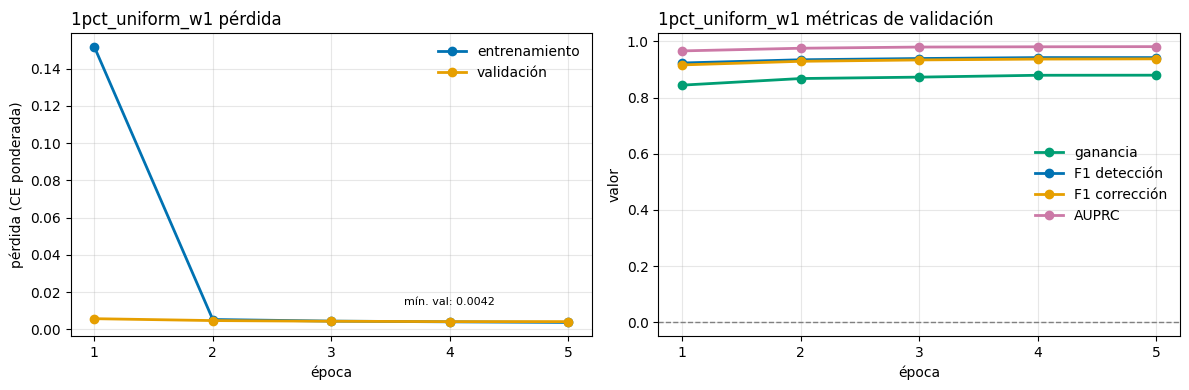


1pct_uniform_w5
Época 1/5 | train loss 0.1656 | val loss 0.0134 | ganancia 0.7998 | F1 det 0.9086 | F1 corr 0.9014 | AUPRC 0.9756 | 1392.2 s
Época 2/5 | train loss 0.0136 | val loss 0.0124 | ganancia 0.8130 | F1 det 0.9146 | F1 corr 0.9073 | AUPRC 0.9779 | 1371.9 s
Época 3/5 | train loss 0.0122 | val loss 0.0112 | ganancia 0.8376 | F1 det 0.9253 | F1 corr 0.9179 | AUPRC 0.9806 | 1393.7 s
Época 4/5 | train loss 0.0111 | val loss 0.0108 | ganancia 0.8318 | F1 det 0.9230 | F1 corr 0.9159 | AUPRC 0.9818 | 1401.8 s
Época 5/5 | train loss 0.0104 | val loss 0.0108 | ganancia 0.8149 | F1 det 0.9155 | F1 corr 0.9092 | AUPRC 0.9823 | 1391.6 s
Tiempo de entrenamiento: 6951.2 s | épocas: 5 | mejor época: 3 (ganancia 0.8376)


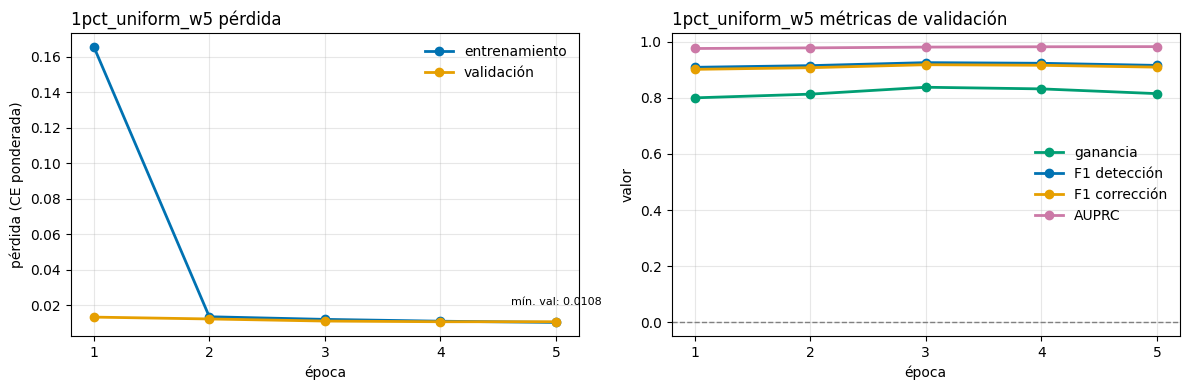


1pct_uniform_w20
Época 1/5 | train loss 0.1877 | val loss 0.0262 | ganancia 0.6351 | F1 det 0.8453 | F1 corr 0.8377 | AUPRC 0.9778 | 1389.0 s
Época 2/5 | train loss 0.0276 | val loss 0.0238 | ganancia 0.6520 | F1 det 0.8525 | F1 corr 0.8449 | AUPRC 0.9815 | 1399.7 s
Época 3/5 | train loss 0.0251 | val loss 0.0227 | ganancia 0.6720 | F1 det 0.8595 | F1 corr 0.8525 | AUPRC 0.9827 | 1386.0 s
Época 4/5 | train loss 0.0239 | val loss 0.0223 | ganancia 0.6839 | F1 det 0.8643 | F1 corr 0.8566 | AUPRC 0.9831 | 1391.2 s
Época 5/5 | train loss 0.0222 | val loss 0.0219 | ganancia 0.6829 | F1 det 0.8637 | F1 corr 0.8567 | AUPRC 0.9837 | 1384.2 s
Tiempo de entrenamiento: 6950.0 s | épocas: 5 | mejor época: 4 (ganancia 0.6839)


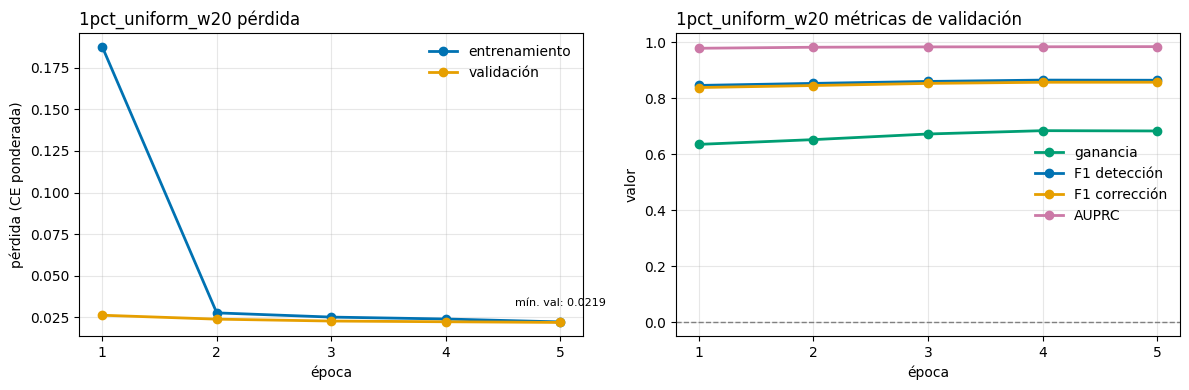


1pct_uniform_w100
Época 1/5 | train loss 0.2240 | val loss 0.0455 | ganancia 0.1645 | F1 det 0.7042 | F1 corr 0.6978 | AUPRC 0.9781 | 1396.0 s
Época 2/5 | train loss 0.0498 | val loss 0.0431 | ganancia 0.2073 | F1 det 0.7151 | F1 corr 0.7095 | AUPRC 0.9798 | 1374.5 s
Época 3/5 | train loss 0.0465 | val loss 0.0419 | ganancia 0.2546 | F1 det 0.7283 | F1 corr 0.7215 | AUPRC 0.9815 | 1397.0 s
Época 4/5 | train loss 0.0444 | val loss 0.0401 | ganancia 0.3163 | F1 det 0.7452 | F1 corr 0.7382 | AUPRC 0.9830 | 1405.3 s
Época 5/5 | train loss 0.0406 | val loss 0.0401 | ganancia 0.3029 | F1 det 0.7416 | F1 corr 0.7346 | AUPRC 0.9833 | 1395.2 s
Tiempo de entrenamiento: 6968.0 s | épocas: 5 | mejor época: 4 (ganancia 0.3163)


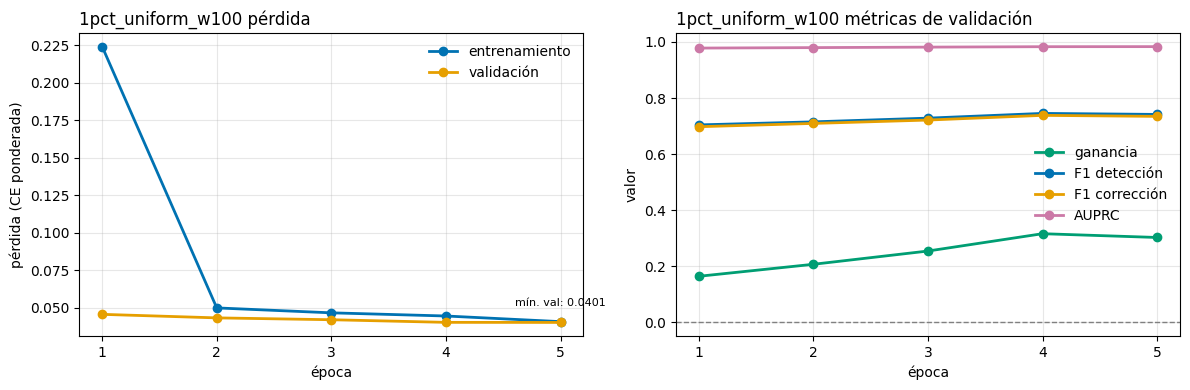

,epochs_run,best_epoch,best_val_gain,val_det_f1,val_corr_f1,val_auprc,val_loss,train_time_min,epoch_time_min
model,,,,,,,,,
1pct_uniform_w1,5,5,0.879588,0.942184,0.937706,0.981222,0.004189,115.719291,23.143858
1pct_uniform_w5,5,3,0.837602,0.925255,0.917857,0.980618,0.011210,115.852768,23.170554
1pct_uniform_w20,5,4,0.683919,0.864272,0.856576,0.983102,0.022270,115.832934,23.166587
1pct_uniform_w100,5,4,0.316345,0.745211,0.738228,0.983041,0.040123,116.133666,23.226733


In [ ]:
# Show the histories (per-epoch metrics, summary and curves) of the 4 error-weight runs with rank 8
plot_runs(results[8])

In [ ]:
# Step 2a: rank 4 with the best error weight on the tuning configuration (1 model)
results[4] = train_rank(4, [TUNING_KEY], [BEST_WEIGHT])


1pct_uniform_w1 ya está entrenado, se omite.


In [ ]:
# Step 2b: rank 16 with the best error weight on the tuning configuration (1 model)
results[16] = train_rank(16, [TUNING_KEY], [BEST_WEIGHT])


1pct_uniform_w1 ya está entrenado, se omite.



rank4_1pct_uniform_w1
Época 1/5 | train loss 0.1638 | val loss 0.0058 | ganancia 0.8416 | F1 det 0.9210 | F1 corr 0.9150 | AUPRC 0.9653 | 1397.9 s
Época 2/5 | train loss 0.0058 | val loss 0.0049 | ganancia 0.8659 | F1 det 0.9351 | F1 corr 0.9287 | AUPRC 0.9739 | 1408.4 s
Época 3/5 | train loss 0.0049 | val loss 0.0045 | ganancia 0.8754 | F1 det 0.9403 | F1 corr 0.9342 | AUPRC 0.9787 | 1400.7 s
Época 4/5 | train loss 0.0045 | val loss 0.0044 | ganancia 0.8783 | F1 det 0.9412 | F1 corr 0.9359 | AUPRC 0.9789 | 1405.1 s
Época 5/5 | train loss 0.0042 | val loss 0.0043 | ganancia 0.8788 | F1 det 0.9419 | F1 corr 0.9363 | AUPRC 0.9794 | 1394.0 s
Tiempo de entrenamiento: 7006.1 s | épocas: 5 | mejor época: 5 (ganancia 0.8788)


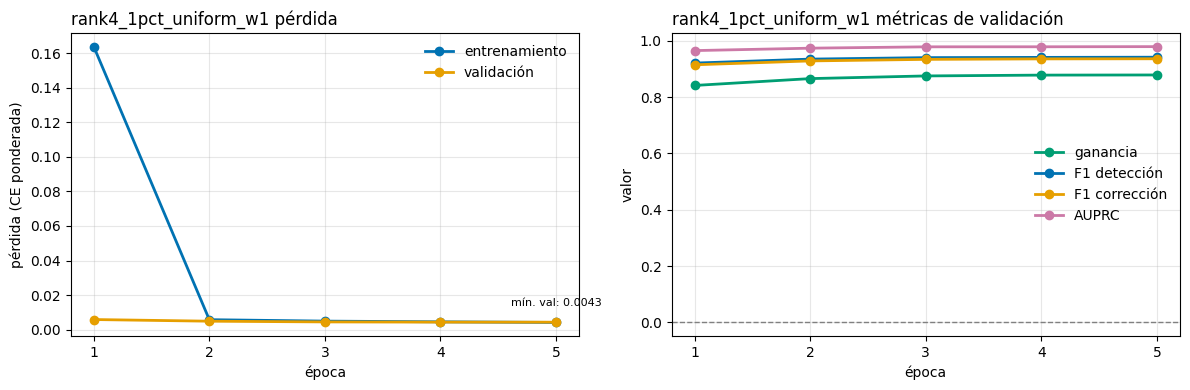


rank16_1pct_uniform_w1
Época 1/5 | train loss 0.1469 | val loss 0.0057 | ganancia 0.8450 | F1 det 0.9241 | F1 corr 0.9159 | AUPRC 0.9671 | 1384.3 s
Época 2/5 | train loss 0.0051 | val loss 0.0047 | ganancia 0.8682 | F1 det 0.9353 | F1 corr 0.9299 | AUPRC 0.9758 | 1394.6 s
Época 3/5 | train loss 0.0042 | val loss 0.0046 | ganancia 0.8696 | F1 det 0.9373 | F1 corr 0.9325 | AUPRC 0.9782 | 1387.0 s
Época 4/5 | train loss 0.0037 | val loss 0.0044 | ganancia 0.8735 | F1 det 0.9402 | F1 corr 0.9342 | AUPRC 0.9798 | 1391.0 s
Época 5/5 | train loss 0.0034 | val loss 0.0044 | ganancia 0.8669 | F1 det 0.9374 | F1 corr 0.9311 | AUPRC 0.9803 | 1379.9 s
Tiempo de entrenamiento: 6936.9 s | épocas: 5 | mejor época: 4 (ganancia 0.8735)


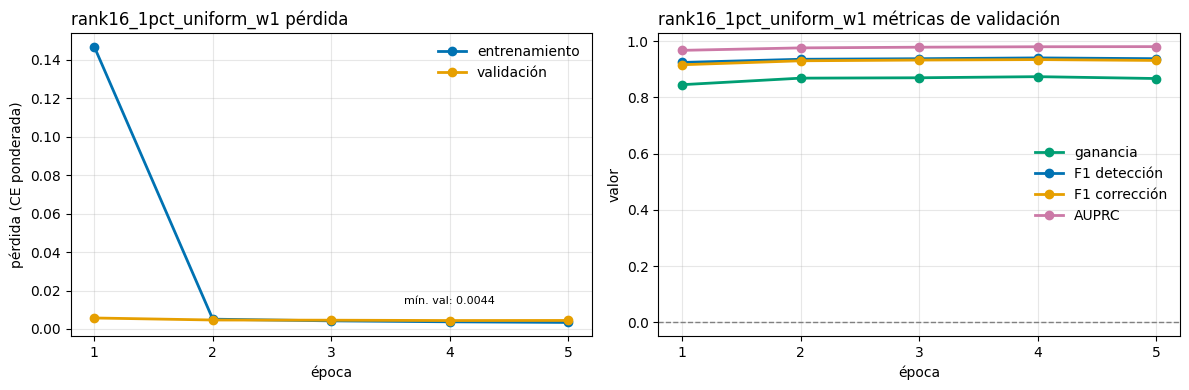

,epochs_run,best_epoch,best_val_gain,val_det_f1,val_corr_f1,val_auprc,val_loss,train_time_min,epoch_time_min
model,,,,,,,,,
rank4_1pct_uniform_w1,5,5,0.878796,0.941879,0.936306,0.979433,0.004313,116.767897,23.353579
rank16_1pct_uniform_w1,5,4,0.873515,0.940189,0.934155,0.979825,0.004390,115.614641,23.122928


In [ ]:
# Show the histories of the rank 4 and rank 16 runs (rank 8 is shown above); the rank is added to the names because both runs share the same configuration name
plot_runs({f"rank{rank}_{name}": run for rank in [4, 16] for name, run in results[rank].items()})

In [ ]:
# Choose the rank with the best validation gain among 4, 8 and 16
BEST_RANK = max([4, 8, 16], key=lambda r: results[r][f"{tuning_prefix}_w{BEST_WEIGHT:g}"]["history"]["best_val_gain"])
print("Mejor rango:", BEST_RANK)

Mejor rango: 8


In [ ]:
# Step 3: train the best rank and weight on all 6 configurations (5 new models; the tuning one is reused)
final_runs = train_rank(BEST_RANK, list(training_sets), [BEST_WEIGHT])


0.1pct_uniform_w1 ya está entrenado, se omite.

0.1pct_realistic_w1 ya está entrenado, se omite.

1pct_uniform_w1 ya está entrenado, se omite.

1pct_realistic_w1 ya está entrenado, se omite.

5pct_uniform_w1 ya está entrenado, se omite.

5pct_realistic_w1 ya está entrenado, se omite.


In [ ]:
def select_final_model(runs, rank, df, table_path):
    """
    Chooses the fine-tuned model with the best mean gain over every validation configuration.

    Each run is evaluated on the 6 validation sets (3 rates x 2 profiles), not only on the
    one it was trained on, so the chosen model is the one that works best when the real
    error rate is unknown. Ties in gain are broken by mean AUPRC. Only the trainable weights
    differ between runs, so one model is built and each run's weights are loaded into it.

    The metrics are saved to table_path after each run, so runs already in that file are not
    evaluated again: after an interrupted session (or when rerunning the notebook) only the
    missing runs are evaluated and the best run's weights are reloaded.

    Parameters
    ----------
    runs : dict
        Runs keyed by "{rate}_{profile}_w{weight}", as returned by train_rank.
    rank : int
        LoRA rank of the runs.
    df : pandas.DataFrame
        Validation genes with their noisy columns.
    table_path : str
        CSV file where the metrics of every run are saved and reloaded from.

    Returns
    -------
    best_name : str
        Name of the chosen run.
    model : LoraModel
        Model with the weights of the chosen run.
    summary : pandas.DataFrame
        Mean gain and AUPRC per run, sorted from best to worst.
    table : pandas.DataFrame
        Metrics of every run on every validation configuration, with a "model" column.
    """
    model = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=rank)
    predict = generanno_predictor(model, BATCH_SIZE)
    tables = [pd.read_csv(table_path)] if os.path.exists(table_path) else []
    done = set(tables[0]["model"]) if tables else set()
    for name, run in runs.items():
        if name in done:
            print(f"{name} ya está evaluado, se omite.")
            continue
        model.load_state_dict(torch.load(run["path"]), strict=False)
        tables.append(evaluate_corrector(predict, df, noisy_columns(1), label=name).assign(model=name))
        pd.concat(tables, ignore_index=True).to_csv(table_path, index=False)
    table = pd.concat(tables, ignore_index=True)
    table = table[table["model"].isin(runs)].reset_index(drop=True)
    summary = (table.groupby("model")[["gain", "auprc"]].mean()
               .sort_values(["gain", "auprc"], ascending=False))
    best_name = summary.index[0]
    model.load_state_dict(torch.load(runs[best_name]["path"]), strict=False)
    print(f"\nMejor modelo: {best_name} | ganancia media {summary.loc[best_name, 'gain']:.4f} | "
          f"AUPRC media {summary.loc[best_name, 'auprc']:.4f}")
    return best_name, model, summary, table

In [ ]:
# Step 4: evaluate the 6 final models on every validation configuration and keep the one with the best mean gain (the test set is not used to choose); the metrics are saved, so runs already evaluated are skipped
best_generanno_name, best_generanno, generanno_val_summary, generanno_val_table = select_final_model(
    final_runs, BEST_RANK, val_df, os.path.join(SAVE_ROOT, "models", f"rank{BEST_RANK}", "val_selection.csv"))

0.1pct_uniform_w1 ya está evaluado, se omite.
0.1pct_realistic_w1 ya está evaluado, se omite.
1pct_uniform_w1 ya está evaluado, se omite.
1pct_realistic_w1 ya está evaluado, se omite.
5pct_uniform_w1 ya está evaluado, se omite.
5pct_realistic_w1 ya está evaluado, se omite.

Mejor modelo: 1pct_realistic_w1 | ganancia media 0.7261 | AUPRC media 0.9652



0.1pct_uniform_w1
Época 1/5 | train loss 0.1545 | val loss 0.0019 | ganancia 0.6098 | F1 det 0.7910 | F1 corr 0.7857 | AUPRC 0.8330 | 1378.1 s
Época 2/5 | train loss 0.0017 | val loss 0.0015 | ganancia 0.6707 | F1 det 0.8293 | F1 corr 0.8241 | AUPRC 0.8676 | 1386.5 s
Época 3/5 | train loss 0.0012 | val loss 0.0015 | ganancia 0.6927 | F1 det 0.8478 | F1 corr 0.8478 | AUPRC 0.8899 | 1373.7 s
Época 4/5 | train loss 0.0010 | val loss 0.0014 | ganancia 0.7049 | F1 det 0.8519 | F1 corr 0.8494 | AUPRC 0.8865 | 1377.2 s
Época 5/5 | train loss 0.0009 | val loss 0.0015 | ganancia 0.6756 | F1 det 0.8435 | F1 corr 0.8387 | AUPRC 0.8964 | 1366.6 s
Tiempo de entrenamiento: 6882.1 s | épocas: 5 | mejor época: 4 (ganancia 0.7049)


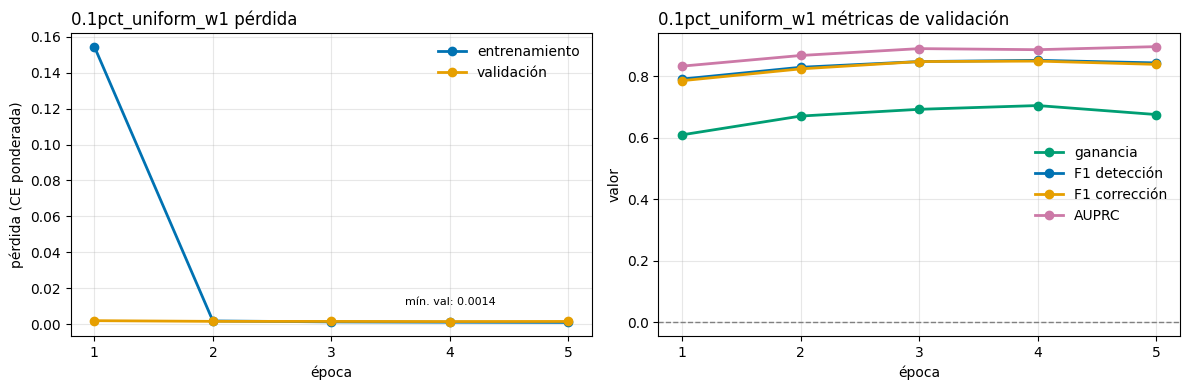


0.1pct_realistic_w1
Época 1/5 | train loss 0.1539 | val loss 0.0015 | ganancia 0.6247 | F1 det 0.8034 | F1 corr 0.7977 | AUPRC 0.8587 | 1377.4 s
Época 2/5 | train loss 0.0017 | val loss 0.0012 | ganancia 0.6863 | F1 det 0.8362 | F1 corr 0.8276 | AUPRC 0.8885 | 1386.3 s
Época 3/5 | train loss 0.0012 | val loss 0.0011 | ganancia 0.6944 | F1 det 0.8538 | F1 corr 0.8538 | AUPRC 0.9232 | 1377.9 s
Época 4/5 | train loss 0.0010 | val loss 0.0011 | ganancia 0.7105 | F1 det 0.8627 | F1 corr 0.8575 | AUPRC 0.9242 | 1386.1 s
Época 5/5 | train loss 0.0008 | val loss 0.0011 | ganancia 0.6971 | F1 det 0.8586 | F1 corr 0.8535 | AUPRC 0.9288 | 1374.4 s
Tiempo de entrenamiento: 6902.1 s | épocas: 5 | mejor época: 4 (ganancia 0.7105)


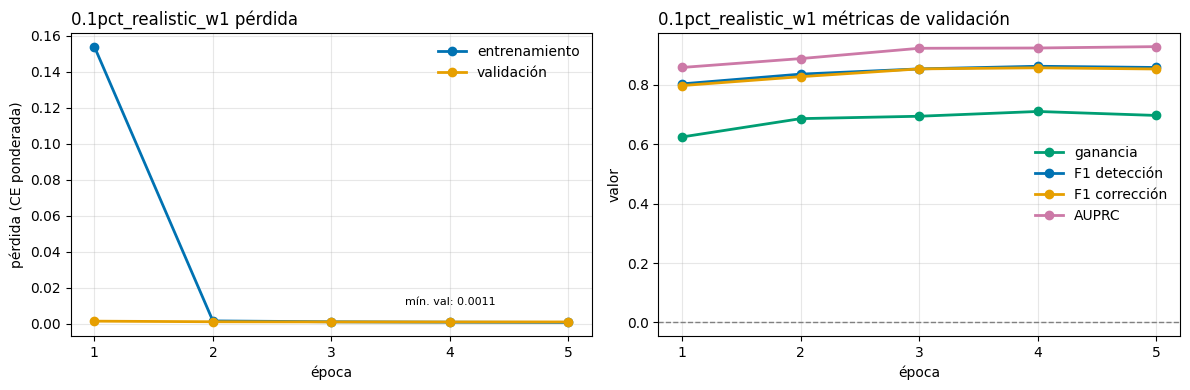


1pct_uniform_w1
Época 1/5 | train loss 0.1519 | val loss 0.0058 | ganancia 0.8442 | F1 det 0.9230 | F1 corr 0.9162 | AUPRC 0.9660 | 1385.4 s
Época 2/5 | train loss 0.0053 | val loss 0.0047 | ganancia 0.8677 | F1 det 0.9344 | F1 corr 0.9290 | AUPRC 0.9755 | 1395.8 s
Época 3/5 | train loss 0.0045 | val loss 0.0044 | ganancia 0.8727 | F1 det 0.9389 | F1 corr 0.9339 | AUPRC 0.9797 | 1388.2 s
Época 4/5 | train loss 0.0041 | val loss 0.0042 | ganancia 0.8793 | F1 det 0.9422 | F1 corr 0.9369 | AUPRC 0.9806 | 1392.6 s
Época 5/5 | train loss 0.0037 | val loss 0.0042 | ganancia 0.8796 | F1 det 0.9422 | F1 corr 0.9377 | AUPRC 0.9812 | 1381.2 s
Tiempo de entrenamiento: 6943.2 s | épocas: 5 | mejor época: 5 (ganancia 0.8796)


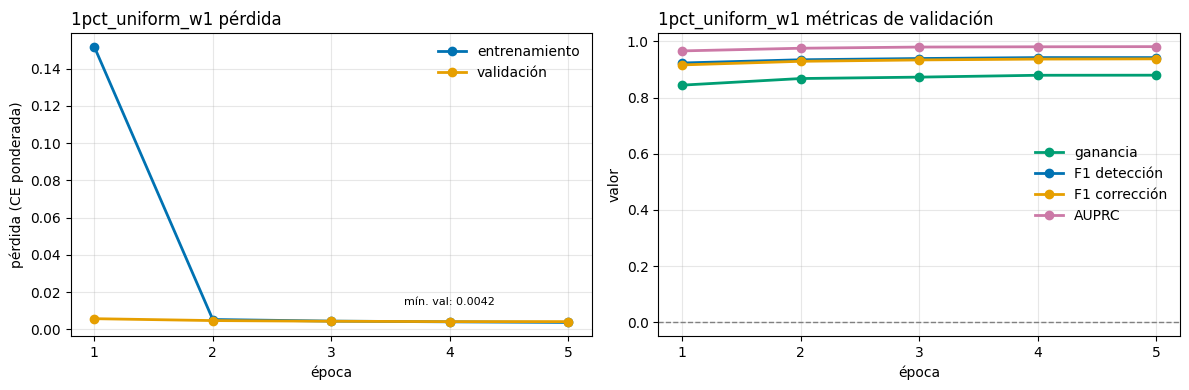


1pct_realistic_w1
Época 1/5 | train loss 0.1527 | val loss 0.0055 | ganancia 0.8596 | F1 det 0.9310 | F1 corr 0.9253 | AUPRC 0.9678 | 1392.6 s
Época 2/5 | train loss 0.0054 | val loss 0.0048 | ganancia 0.8739 | F1 det 0.9398 | F1 corr 0.9325 | AUPRC 0.9741 | 1403.4 s
Época 3/5 | train loss 0.0045 | val loss 0.0047 | ganancia 0.8760 | F1 det 0.9405 | F1 corr 0.9349 | AUPRC 0.9762 | 1396.6 s
Época 4/5 | train loss 0.0040 | val loss 0.0044 | ganancia 0.8837 | F1 det 0.9443 | F1 corr 0.9387 | AUPRC 0.9782 | 1400.0 s
Época 5/5 | train loss 0.0036 | val loss 0.0044 | ganancia 0.8781 | F1 det 0.9424 | F1 corr 0.9361 | AUPRC 0.9792 | 1388.5 s
Tiempo de entrenamiento: 6981.0 s | épocas: 5 | mejor época: 4 (ganancia 0.8837)


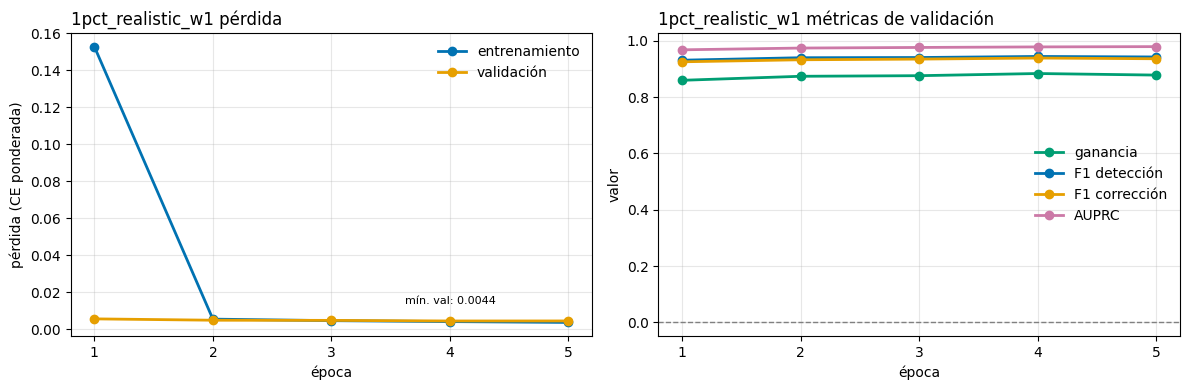


5pct_uniform_w1
Época 1/5 | train loss 0.1761 | val loss 0.0202 | ganancia 0.8775 | F1 det 0.9443 | F1 corr 0.9316 | AUPRC 0.9835 | 1393.4 s
Época 2/5 | train loss 0.0203 | val loss 0.0186 | ganancia 0.8858 | F1 det 0.9478 | F1 corr 0.9360 | AUPRC 0.9853 | 1404.6 s
Época 3/5 | train loss 0.0185 | val loss 0.0180 | ganancia 0.8879 | F1 det 0.9494 | F1 corr 0.9374 | AUPRC 0.9863 | 1397.0 s
Época 4/5 | train loss 0.0171 | val loss 0.0173 | ganancia 0.8935 | F1 det 0.9517 | F1 corr 0.9405 | AUPRC 0.9870 | 1401.0 s
Época 5/5 | train loss 0.0162 | val loss 0.0170 | ganancia 0.8962 | F1 det 0.9528 | F1 corr 0.9422 | AUPRC 0.9875 | 1389.7 s
Tiempo de entrenamiento: 6985.6 s | épocas: 5 | mejor época: 5 (ganancia 0.8962)


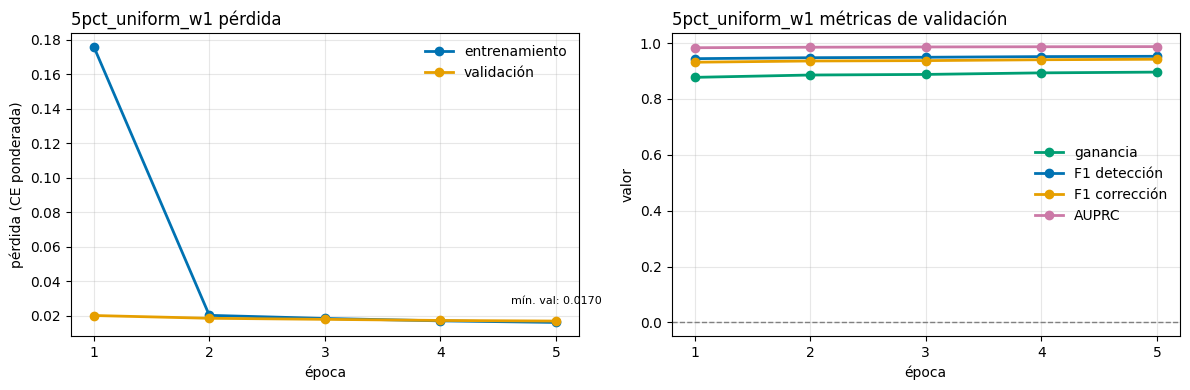


5pct_realistic_w1
Época 1/5 | train loss 0.1761 | val loss 0.0219 | ganancia 0.8671 | F1 det 0.9386 | F1 corr 0.9262 | AUPRC 0.9813 | 1394.3 s
Época 2/5 | train loss 0.0202 | val loss 0.0197 | ganancia 0.8767 | F1 det 0.9431 | F1 corr 0.9323 | AUPRC 0.9842 | 1404.8 s
Época 3/5 | train loss 0.0185 | val loss 0.0189 | ganancia 0.8813 | F1 det 0.9458 | F1 corr 0.9341 | AUPRC 0.9854 | 1397.6 s
Época 4/5 | train loss 0.0172 | val loss 0.0183 | ganancia 0.8842 | F1 det 0.9468 | F1 corr 0.9360 | AUPRC 0.9860 | 1401.7 s
Época 5/5 | train loss 0.0164 | val loss 0.0181 | ganancia 0.8855 | F1 det 0.9475 | F1 corr 0.9368 | AUPRC 0.9863 | 1390.3 s
Tiempo de entrenamiento: 6988.7 s | épocas: 5 | mejor época: 5 (ganancia 0.8855)


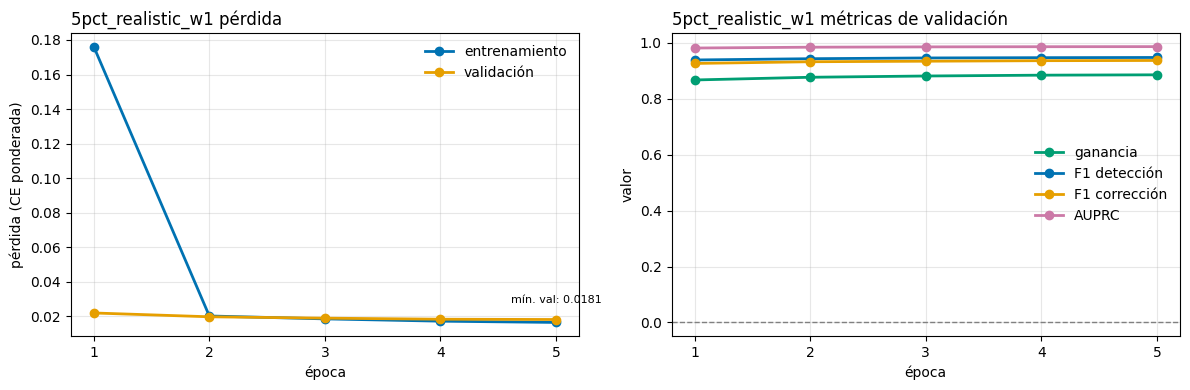

,epochs_run,best_epoch,best_val_gain,val_det_f1,val_corr_f1,val_auprc,val_loss,train_time_min,epoch_time_min
model,,,,,,,,,
0.1pct_uniform_w1,5,4,0.704878,0.851852,0.849383,0.886454,0.001399,114.701409,22.940282
0.1pct_realistic_w1,5,4,0.710456,0.862694,0.857513,0.924206,0.001096,115.035452,23.007090
1pct_uniform_w1,5,5,0.879588,0.942184,0.937706,0.981222,0.004189,115.719291,23.143858
1pct_realistic_w1,5,4,0.883690,0.944275,0.938689,0.978172,0.004361,116.350451,23.270090
5pct_uniform_w1,5,5,0.896229,0.952827,0.942223,0.987451,0.016967,116.427149,23.285430
5pct_realistic_w1,5,5,0.885453,0.947494,0.936792,0.986298,0.018121,116.478237,23.295647


In [ ]:
# Show the histories (per-epoch metrics, summary and curves) of the 6 final models
plot_runs(final_runs)

## 8. Evaluación

Todos los modelos se evalúan sobre las mismas secuencias de prueba: 3 tasas × 2 perfiles × 5 semillas de errores, más las arqueas como prueba fuera de dominio.

- Antes de evaluar se **verifica la partición**: como MMseqs2 se descarga en su última versión, se comprueba que los tamaños y los genes de validación sean exactamente los del entrenamiento; si no coinciden, el notebook se detiene.
- Las predicciones de cada modelo se **guardan en el Drive** apenas se calculan, junto con la identidad del modelo, así que una sesión interrumpida solo repite lo que falta.
- Una de las primeras celdas de esta sección reemplaza `plt.show` para que **cada figura** se guarde también como PNG en `SAVE_ROOT/evaluation/figures`, y la última celda de 8.6 guarda todas las **tablas** en CSV en `SAVE_ROOT/evaluation/tables`.


In [ ]:
# Imports used only in this section, and the folder where the predictions of every model are cached (one file per model, set and noisy column) so an interrupted session does not repeat the GENERanno passes
import zlib
from Bio.Data import CodonTable

EVAL_DIR = os.path.join(SAVE_ROOT, "evaluation")
os.makedirs(EVAL_DIR, exist_ok=True)
EVAL_SETS = {"test": test_df, "arch": arch_df}
SET_NAMES = {"test": "Prueba E. coli", "arch": "Arqueas"}
TEST_COLUMNS = noisy_columns(N_TEST_SEEDS)

In [ ]:
# Save every figure shown from here on to Drive (PNG, 200 dpi) before displaying it, named with its number and the first comment line of the cell that drew it
FIGURE_DIR = os.path.join(EVAL_DIR, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)
if not hasattr(plt, "_original_show"):
    plt._original_show = plt.show
figure_counter = [0]

def figure_name(fig):
    """
    Builds a file name for a figure.

    The name comes from the first comment line of the running cell or, if the cell does not
    start with a comment, from the title of the figure.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure to name.

    Returns
    -------
    name : str
        Name with only letters, digits and underscores, at most 70 characters.
    """
    try:
        source = get_ipython().user_ns["In"][-1].strip().splitlines()[0]
    except Exception:
        source = ""
    if not source.startswith("#"):
        source = fig._suptitle.get_text() if fig._suptitle else fig.axes[0].get_title(loc="left") if fig.axes else ""
    return re.sub(r"[^0-9A-Za-z]+", "_", source).strip("_")[:70]

def show_and_save(*args, **kwargs):
    """
    Saves every open figure to FIGURE_DIR and then displays it as plt.show would.

    Parameters
    ----------
    *args, **kwargs
        Arguments passed on to the original plt.show.
    """
    for num in plt.get_fignums():
        figure_counter[0] += 1
        fig = plt.figure(num)
        fig.savefig(os.path.join(FIGURE_DIR, f"fig{figure_counter[0]:02d}_{figure_name(fig)}.png"),
                    dpi=200, bbox_inches="tight")
    plt._original_show(*args, **kwargs)

plt.show = show_and_save
print("Las figuras se guardarán en", FIGURE_DIR)

Las figuras se guardarán en /content/drive/MyDrive/proyecto-nlp/evaluation/figures


In [ ]:
# Check that the split is the one the models were trained and selected with: MMseqs2 is downloaded in its latest version, and another version can cluster the genes differently and move training genes into test
TRAINING_SPLIT_SIZES = {"train": 3407, "val": 415, "test": 433}
split_sizes = {"train": len(train_df), "val": len(val_df), "test": len(test_df)}
print("Partición actual:", split_sizes, "| partición del entrenamiento:", TRAINING_SPLIT_SIZES)
if split_sizes != TRAINING_SPLIT_SIZES:
    raise ValueError("La partición no coincide con la del entrenamiento: los resultados de prueba no serían válidos "
                     "(puede haber genes de entrenamiento en prueba). Hay que recuperar la partición original.")

Partición actual: {'train': 3407, 'val': 415, 'test': 433} | partición del entrenamiento: {'train': 3407, 'val': 415, 'test': 433}


In [ ]:
# Exact check of the split without running any model: the validation metrics saved when the model was chosen (val_selection.csv) are ratios of whole counts (recall = hits / errors, overcorrection = false positives / correct positions), so multiplied by today's number of errors and of correct positions of each validation column they must give whole numbers in every row; with other validation genes or other errors they would not
split_mismatches = []
for (r_name, profile), rows in generanno_val_table.groupby(["rate", "profile"]):
    col = noisy_col_name(r_name, profile, 0)
    clean_bytes, noisy_bytes = "".join(val_df["seq"]).encode(), "".join(val_df[col]).encode()
    n_errors = int((np.frombuffer(clean_bytes, "S1") != np.frombuffer(noisy_bytes, "S1")).sum())
    n_correct = len(clean_bytes) - n_errors
    counts = np.concatenate([rows["det_recall"] * n_errors, rows["corr_recall"] * n_errors,
                             rows["overcorrection"] * n_correct])
    if not np.allclose(counts, np.round(counts), rtol=0, atol=1e-6):
        split_mismatches.append(col)
if split_mismatches:
    raise ValueError(f"Las columnas de validación {split_mismatches} no son las que se usaron para elegir el modelo: "
                     "la partición o la simulación de errores cambió. Hay que recuperar la partición original.")
print(f"Partición verificada: las {len(generanno_val_table)} filas de val_selection.csv corresponden a estos genes de validación.")

Partición verificada: las 36 filas de val_selection.csv corresponden a estos genes de validación.


#### Funciones de evaluación

Las predicciones de cada modelo se guardan de forma compacta: solo las posiciones con error o modificadas por el modelo, que son las únicas que cambian entre análisis (el resto son verdaderos negativos). A partir de ellas se cuentan, por gen, los aciertos y fallos de detección, de corrección y del oráculo, en total, por posición en el codón y por codón; todas las métricas y los intervalos de confianza se calculan sumando esos conteos.

In [ ]:
def column_fingerprint(df, column, model_tag):
    """
    Computes a checksum of a column of sequences and of the model that corrects them.

    It is stored with each cached prediction, so a cache made on other noisy sequences
    (e.g. after changing the split or the error simulation) or by another model (e.g.
    another chosen run or n-gram) is detected and recomputed.

    Parameters
    ----------
    df : pandas.DataFrame
        Table with the column.
    column : str
        Column of sequences.
    model_tag : str
        Identifier of the exact model (e.g. its run name or hyperparameters).

    Returns
    -------
    fingerprint : int
        CRC32 of the model tag and the sequences of the column, in order.
    """
    return zlib.crc32((model_tag + "\n" + "\n".join(df[column])).encode())

In [ ]:
def compact_predictions(originals, noisy, preds):
    """
    Keeps only the positions of the predictions that the metrics of this section need.

    A position with no error that the model did not change is a true negative in every
    analysis, so only the error positions and the positions the model changed are stored,
    with the input base, the output base and the oracle base: the most probable base among
    the three that differ from the input, i.e. the correction the model would make if it
    knew where the error is. The metrics of correction_metrics (including the AUPRC, which
    needs every position) are computed on the full predictions and stored too.

    Parameters
    ----------
    originals : list of str
        Clean sequences.
    noisy : list of str
        Noisy sequences given to the model, in the same order.
    preds : list of tuple of (str, numpy.ndarray)
        (corrected, probs [len, 4]) per gene, as returned by run_epoch.

    Returns
    -------
    compact : dict
        "pos" (positions in the concatenated genes), "inp", "out" and "oracle" (bases at
        those positions), plus every metric of correction_metrics.

    Raises
    ------
    AssertionError
        If a prediction does not have the length of its sequence.
    """
    orig = np.frombuffer("".join(originals).encode(), dtype="S1")
    inp = np.frombuffer("".join(noisy).encode(), dtype="S1")
    out = np.frombuffer("".join(c for c, _ in preds).encode(), dtype="S1")
    probs = np.concatenate([p for _, p in preds])
    assert len(orig) == len(inp) == len(out) == len(probs), "predictions do not match the sequences"

    pos = np.flatnonzero((inp != orig) | (out != inp))
    masked = probs[pos].astype(np.float64)
    masked[np.arange(len(pos)), [BASE2ID[b] for b in inp[pos].astype(str)]] = -np.inf
    oracle = np.array(list(BASES), dtype="S1")[masked.argmax(axis=1)]

    return {"pos": pos, "inp": inp[pos], "out": out[pos], "oracle": oracle,
            **correction_metrics(originals, noisy, preds)}

In [ ]:
def load_compact(path):
    """
    Loads compact predictions saved with numpy.savez.

    Parameters
    ----------
    path : str
        Path to the .npz file.

    Returns
    -------
    compact : dict
        Arrays as numpy arrays and scalars (metrics, fingerprint) as Python numbers.
    """
    with np.load(path) as f:
        return {k: f[k] if f[k].ndim else f[k].item() for k in f.files}

In [ ]:
def cached_predictions(predict, df, columns, model_name, set_name, model_tag):
    """
    Runs a corrector on every noisy column and caches its compact predictions.

    Each column is saved to EVAL_DIR/{set_name}/{model_name}/{column}.npz as soon as it is
    predicted, so after an interrupted session only the missing columns are run. A cached
    file is reused only if it was computed by the same model on the same noisy sequences
    (same fingerprint).

    Parameters
    ----------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    df : pandas.DataFrame
        Genes with the clean column "seq" and the noisy columns.
    columns : dict of tuple to str
        Configuration key mapped to its noisy column, as returned by noisy_columns.
    model_name : str
        Name of the model, used as folder name.
    set_name : str
        Name of the set ("test" or "arch"), used as folder name.
    model_tag : str
        Identifier of the exact model, part of the fingerprint.

    Returns
    -------
    compacts : dict of tuple to dict
        Configuration key mapped to its compact predictions.
    """
    folder = os.path.join(EVAL_DIR, set_name, model_name)
    os.makedirs(folder, exist_ok=True)
    originals = df["seq"].tolist()
    compacts = {}
    for key, col in columns.items():
        path = os.path.join(folder, f"{col}.npz")
        fingerprint = column_fingerprint(df, col, model_tag)
        if os.path.exists(path):
            cached = load_compact(path)
            if cached["fingerprint"] == fingerprint:
                compacts[key] = cached
                continue
            print(f"{model_name} | {set_name} | {col}: la caché es de otras secuencias o de otro modelo, se recalcula.")

        start = time.perf_counter()
        compact = compact_predictions(originals, df[col].tolist(), predict(df, col))
        tmp_path = path[:-len(".npz")] + ".tmp.npz"
        np.savez_compressed(tmp_path, fingerprint=fingerprint, **compact)
        os.replace(tmp_path, path)
        compacts[key] = load_compact(path)
        print(f"{model_name} | {set_name} | {col} | ganancia {compact['gain']:.4f} | "
              f"F1 det {compact['det_f1']:.4f} | F1 corr {compact['corr_f1']:.4f} | "
              f"AUPRC {compact['auprc']:.4f} | {time.perf_counter() - start:.1f} s")
    return compacts

In [ ]:
def gene_counts(df, compact):
    """
    Counts, for every gene, the outcomes of detection, correction and the oracle.

    The counts are computed over all positions, separately for the 1st, 2nd and 3rd
    position of the codon (prefixes "c1_", "c2_", "c3_"), and over codons (prefix
    "codon_"): a codon has an error if any of its bases is wrong, is changed if the model
    changed any of its bases, and is fixed only if it ends identical to the original.
    Every gene must be a complete CDS in reading frame (length divisible by 3).

    Parameters
    ----------
    df : pandas.DataFrame
        Genes with the clean column "seq", in the order used for the predictions.
    compact : dict
        Compact predictions of one noisy column, as returned by compact_predictions.

    Returns
    -------
    counts : pandas.DataFrame
        One row per gene with "gene" (row index in df), "id", "gc", "residual" (wrong
        bases after correction), "n" (positions), "err", "tp", "fp", "fixed" and
        "oracle_fixed", and the same counts with the prefixes "c1_", "c2_", "c3_" and
        "codon_".

    Raises
    ------
    AssertionError
        If the length of a gene is not a multiple of 3
    """
    seqs = df["seq"].tolist()
    lengths = np.array([len(s) for s in seqs])
    assert (lengths % 3 == 0).all(), "every gene must have a length divisible by 3"
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    orig = np.frombuffer("".join(seqs).encode(), dtype="S1")
    n_genes = len(seqs)

    pos, inp, out, oracle = compact["pos"], compact["inp"], compact["out"], compact["oracle"]
    ref = orig[pos]
    gene = np.searchsorted(starts, pos, side="right") - 1
    codon_position = (pos - starts[gene]) % 3

    is_error = inp != ref
    changed = out != inp
    wrong = out != ref
    oracle_wrong = is_error & (oracle != ref)

    def per_gene(mask, genes=gene):
        """
        Counts, for every gene, the positions selected by a mask.

        Parameters
        ----------
        mask : numpy.ndarray
            Boolean mask over the compact positions.
        genes : numpy.ndarray, optional
            Gene index of every compact position.

        Returns
        -------
        counts : numpy.ndarray
            Number of selected positions per gene, of length n_genes.
        """
        return np.bincount(genes[mask], minlength=n_genes)

    def outcome_counts(prefix, n, err, chg, wrg, orc_wrg, genes=gene):
        """
        Builds the counts of detection, correction and oracle outcomes with a prefix.

        Parameters
        ----------
        prefix : str
            Prefix of the count names ("", "c1_", "c2_", "c3_" or "codon_").
        n : numpy.ndarray or int
            Number of evaluated units (positions or codons) per gene.
        err : numpy.ndarray
            Mask of the units with an error.
        chg : numpy.ndarray
            Mask of the units changed by the model.
        wrg : numpy.ndarray
            Mask of the units that are wrong after correction.
        orc_wrg : numpy.ndarray
            Mask of the units with an error that the oracle leaves wrong.
        genes : numpy.ndarray, optional
            Gene index of every unit.

        Returns
        -------
        counts : dict of str to numpy.ndarray
            "n", "err", "tp", "fp", "fixed" and "oracle_fixed", with the prefix.
        """
        return {
            f"{prefix}n": n,
            f"{prefix}err": per_gene(err, genes),
            f"{prefix}tp": per_gene(err & chg, genes),
            f"{prefix}fp": per_gene(~err & chg, genes),
            f"{prefix}fixed": per_gene(err & ~wrg, genes),
            f"{prefix}oracle_fixed": per_gene(err & ~orc_wrg, genes),
        }

    counts = {"gene": np.arange(n_genes), "id": df["id"].to_numpy(),
              "gc": np.array([(s.count("G") + s.count("C")) / len(s) for s in seqs]),
              "residual": per_gene(wrong)}
    counts.update(outcome_counts("", lengths, is_error, changed, wrong, oracle_wrong))
    for k in range(3):
        m = codon_position == k
        counts.update(outcome_counts(f"c{k + 1}_", lengths // 3, is_error & m, changed & m, wrong & m, oracle_wrong & m))

    # Codons: positions are sorted, so the positions of one codon are contiguous; reduce each group with "any"
    codon = pos // 3
    first = np.flatnonzero(np.r_[True, codon[1:] != codon[:-1]]) if len(pos) else np.array([], dtype=int)
    codon_any = (lambda mask: np.logical_or.reduceat(mask, first)) if len(pos) else (lambda mask: mask)
    counts.update(outcome_counts("codon_", lengths // 3, codon_any(is_error), codon_any(changed),
                                 codon_any(wrong), codon_any(oracle_wrong), genes=gene[first]))
    return pd.DataFrame(counts)

In [ ]:
def ratio(numerator, denominator):
    """
    Divides element-wise, returning NaN where the denominator is 0.

    Parameters
    ----------
    numerator, denominator : array-like
        Values to divide.

    Returns
    -------
    result : numpy.ndarray
        numerator / denominator, NaN where undefined.
    """
    numerator, denominator = np.asarray(numerator, dtype=float), np.asarray(denominator, dtype=float)
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.where(denominator > 0, numerator / np.where(denominator > 0, denominator, 1), np.nan)

In [ ]:
def metrics_from_counts(counts, prefix=""):
    """
    Computes the detection, correction and oracle metrics from summed counts.

    The definitions are those of correction_metrics, except that a precision with no
    changes (e.g. NoChange) is NaN instead of 0, since it is undefined; an F1 with
    recall 0 is 0. Works on scalars, on the columns of a table (one value per row) and
    on the arrays of the bootstrap.

    Parameters
    ----------
    counts : mapping of str to array-like
        Counts "n", "err", "tp", "fp", "fixed" and "oracle_fixed", with the prefix.
    prefix : str, optional
        Prefix of the counts and of the returned metrics ("", "c1_", "codon_", ...).

    Returns
    -------
    metrics : dict of str to numpy.ndarray
        "gain", "det_precision", "det_recall", "det_f1", "corr_precision", "corr_recall",
        "corr_f1", "overcorrection" and "oracle_accuracy", with the prefix.
    """
    c = {k: np.asarray(counts[prefix + k], dtype=float) for k in ["n", "err", "tp", "fp", "fixed", "oracle_fixed"]}
    changes = c["tp"] + c["fp"]

    def f1(p, r):
        """
        Computes the F1 score, defined as 0 when the recall is 0.

        Parameters
        ----------
        p : numpy.ndarray
            Precision.
        r : numpy.ndarray
            Recall.

        Returns
        -------
        f1 : numpy.ndarray
            Harmonic mean of p and r.
        """
        with np.errstate(invalid="ignore"):
            return np.where(r == 0, 0.0, 2 * p * r / (p + r))

    det_p, det_r = ratio(c["tp"], changes), ratio(c["tp"], c["err"])
    corr_p, corr_r = ratio(c["fixed"], changes), ratio(c["fixed"], c["err"])
    metrics = {
        "gain": ratio(c["fixed"] - c["fp"], c["err"]),
        "det_precision": det_p, "det_recall": det_r, "det_f1": f1(det_p, det_r),
        "corr_precision": corr_p, "corr_recall": corr_r, "corr_f1": f1(corr_p, corr_r),
        "overcorrection": ratio(c["fp"], c["n"] - c["err"]),
        "oracle_accuracy": ratio(c["oracle_fixed"], c["err"]),
    }
    return {prefix + k: v for k, v in metrics.items()}

In [ ]:
# Groups of metrics reported in the tables; the "c1_", "c2_" and "c3_" variants are reported in 8.6.4
MAIN_METRICS = ["gain", "det_precision", "det_recall", "det_f1", "corr_precision", "corr_recall", "corr_f1",
                "overcorrection", "auprc", "auprc_random"]
GENE_METRICS = ["pct_perfect", "pct_reference", "pct_repaired", "pct_damaged"]
ORACLE_METRICS = ["corr_recall", "oracle_accuracy", "codon_corr_recall", "codon_oracle_accuracy"]
CODON_METRICS = ["codon_gain", "codon_det_precision", "codon_det_recall", "codon_det_f1",
                 "codon_corr_precision", "codon_corr_recall", "codon_corr_f1", "codon_overcorrection"]
COUNT_COLUMNS = [f"{p}{k}" for p in ["", "c1_", "c2_", "c3_", "codon_"]
                 for k in ["n", "err", "tp", "fp", "fixed", "oracle_fixed"]]
# Names shown in tables and plots: Frequency is given the error positions, so its gain is a gain with an oracle
MODEL_LABELS = {"Frequency": "Frequency (oráculo)"}

In [ ]:
def config_metrics(genes):
    """
    Computes the metrics of every configuration from the per-gene counts.

    Counts are summed over the genes of each (model, set, rate, profile, seed), so genes
    without errors still count (as in correction_metrics). The gene-level metrics are the
    share of genes identical to the original after correction ("pct_perfect"), its
    reference, i.e. the share that received no errors and that NoChange leaves perfect
    ("pct_reference"), the share of genes with errors that end perfect ("pct_repaired")
    and the share of genes without errors that the model damages ("pct_damaged").

    Parameters
    ----------
    genes : pandas.DataFrame
        Per-gene counts with the columns "model", "set", "rate", "profile" and "seed", as
        built by evaluate_model.

    Returns
    -------
    table : pandas.DataFrame
        One row per configuration with the metrics of metrics_from_counts (all positions,
        each codon position and codons) and the gene-level metrics.
    """
    keys = ["model", "set", "rate", "profile", "seed"]
    flags = genes[keys].assign(
        perfect=genes["residual"] == 0,
        reference=genes["err"] == 0,
        repaired=(genes["residual"] == 0) & (genes["err"] > 0),
        with_error=genes["err"] > 0,
        damaged=(genes["residual"] > 0) & (genes["err"] == 0),
    )
    gene_level = flags.groupby(keys, sort=False).sum()
    n_genes = flags.groupby(keys, sort=False).size()

    table = genes.groupby(keys, sort=False)[COUNT_COLUMNS].sum()
    for prefix in ["", "c1_", "c2_", "c3_", "codon_"]:
        for name, values in metrics_from_counts(table, prefix).items():
            table[name] = values
    table["pct_perfect"] = gene_level["perfect"] / n_genes
    table["pct_reference"] = gene_level["reference"] / n_genes
    table["pct_repaired"] = ratio(gene_level["repaired"], gene_level["with_error"])
    table["pct_damaged"] = ratio(gene_level["damaged"], gene_level["reference"])
    return table.reset_index()

In [ ]:
def evaluate_model(predict, model_name, model_tag, has_probs=True, knows_errors=False):
    """
    Evaluates a corrector on the E. coli test set and on the archaea, every noisy column.

    Predictions are cached with cached_predictions, and the metrics of every
    configuration are saved to EVAL_DIR/{model_name}_configs.csv (the per-gene counts are
    rebuilt from the cache in seconds, so they are not saved).

    Parameters
    ----------
    predict : callable
        Function (df, noisy_col) -> list of (corrected, probs) per gene, in the order of df.
    model_name : str
        Name of the model in the tables.
    model_tag : str
        Identifier of the exact model (run name, hyperparameters), stored in the cache so
        predictions of another model are never reused.
    has_probs : bool, optional
        Whether the corrector returns real probabilities. If False (NoChange, Frequency),
        the oracle cannot choose among the other three bases and its metrics are NaN.
    knows_errors : bool, optional
        Whether the corrector is given the error positions (Frequency). Its detection
        metrics, overcorrection and AUPRC are then NaN, and its oracle accuracy is its own
        correction recall.

    Returns
    -------
    result : dict
        "configs" (metrics per configuration, both sets), "genes" (per-gene counts) and
        "compacts" (set name -> configuration key -> compact predictions).

    Raises
    ------
    AssertionError
        If the metrics rebuilt from the counts do not match the ones of correction_metrics.
    """
    genes, compacts = [], {}
    for set_name, df in EVAL_SETS.items():
        compacts[set_name] = cached_predictions(predict, df, TEST_COLUMNS, model_name, set_name, model_tag)
        for (r_name, profile, seed), compact in compacts[set_name].items():
            genes.append(gene_counts(df, compact).assign(model=model_name, set=set_name, rate=r_name,
                                                         profile=profile, seed=seed))
    genes = pd.concat(genes, ignore_index=True)
    configs = config_metrics(genes)

    stored = {(s, r, p, sd): c for s, cs in compacts.items() for (r, p, sd), c in cs.items()}
    keys = list(zip(configs["set"], configs["rate"], configs["profile"], configs["seed"]))
    configs["auprc"] = [stored[k]["auprc"] for k in keys]
    configs["auprc_random"] = configs["err"] / configs["n"]

    # The cached metrics of correction_metrics must match the ones rebuilt from the counts, on the columns with errors
    # (with no errors the gain and the recalls are undefined); an undefined precision is NaN here and 0 there
    has_errors = (configs["err"] > 0).to_numpy()
    for name in ["gain", "det_recall", "corr_precision", "corr_recall", "overcorrection"]:
        rebuilt = np.nan_to_num(configs[name].to_numpy(dtype=float)[has_errors])
        cached = np.array([stored[k][name] for k in keys], dtype=float)[has_errors]
        assert np.allclose(rebuilt, cached), (
            f"{model_name}: {name} no coincide con correction_metrics; borra la carpeta "
            f"{os.path.join(EVAL_DIR, '<set>', model_name)} y vuelve a correr la celda")

    oracle_columns = [c for c in configs if c.endswith("oracle_accuracy")]
    if not has_probs:
        configs[oracle_columns] = np.nan
    if knows_errors:
        for prefix in ["", "c1_", "c2_", "c3_", "codon_"]:
            configs[prefix + "oracle_accuracy"] = configs[prefix + "corr_recall"]
            for name in ["det_precision", "det_recall", "det_f1", "overcorrection"]:
                configs[prefix + name] = np.nan
        configs["auprc"] = np.nan

    configs.to_csv(os.path.join(EVAL_DIR, f"{model_name}_configs.csv"), index=False)
    return {"configs": configs, "genes": genes, "compacts": compacts}

In [ ]:
def order_configs(table):
    """
    Sorts a table by model (in order of appearance), error rate (as in RATES) and profile
    (as in PROFILES); rows of one group keep their order.

    Parameters
    ----------
    table : pandas.DataFrame
        Table with the column "rate", and optionally "profile" and "model".

    Returns
    -------
    table : pandas.DataFrame
        Sorted copy.
    """
    order = table["rate"].map(list(RATES).index) * len(PROFILES)
    if "profile" in table:
        order = order + table["profile"].map(PROFILES.index)
    if "model" in table:
        order = order + pd.factorize(table["model"])[0] * len(RATES) * len(PROFILES)
    return table.assign(_order=order).sort_values("_order", kind="stable").drop(columns="_order")

In [ ]:
def mean_std_table(configs, metrics, set_name, by=("model", "rate", "profile")):
    """
    Formats the mean ± standard deviation of some metrics over the seeds.

    Parameters
    ----------
    configs : pandas.DataFrame
        Metrics per configuration, as returned by evaluate_model.
    metrics : list of str
        Metrics to show.
    set_name : str
        Set to show ("test" or "arch").
    by : tuple of str, optional
        Columns that define a row; the seeds are aggregated.

    Returns
    -------
    table : pandas.DataFrame
        One row per group and one column per metric, as "mean ± std" strings ("—" when
        the metric is undefined).
    """
    data = configs[configs["set"] == set_name]
    grouped = data.groupby(list(by), sort=False)[metrics]
    mean, std = grouped.mean(), grouped.std()

    def fmt(m, s, name):
        """
        Formats a mean and its standard deviation as text.

        Parameters
        ----------
        m : float
            Mean; NaN is shown as "—".
        s : float
            Standard deviation; omitted when it is NaN.
        name : str
            Metric name; overcorrection metrics use scientific notation.

        Returns
        -------
        text : str
            "mean ± std" with 4 decimals, or in scientific notation.
        """
        if np.isnan(m):
            return "—"
        spec = ".2e" if name.endswith("overcorrection") else ".4f"
        return f"{m:{spec}}" if np.isnan(s) else f"{m:{spec}} ± {s:{spec}}"

    table = pd.DataFrame({name: [fmt(m, s, name) for m, s in zip(mean[name], std[name])] for name in metrics},
                         index=mean.index)
    table = order_configs(table.reset_index())
    if "model" in table:
        table["model"] = table["model"].map(lambda m: MODEL_LABELS.get(m, m))
    return table.set_index(list(by))

In [ ]:
def bootstrap_ci(genes, model_names, set_name, n_boot=1000, level=0.95, seed=0,
                 metrics=("gain", "det_f1", "corr_f1"), reference=None):
    """
    Computes bootstrap confidence intervals by resampling whole genes.

    The positions of one gene are not independent, so each replicate draws genes with
    replacement (all their positions, pooled over the seeds of the configuration) and
    recomputes the metrics from the summed counts. All models use the same draws, so the
    difference with a reference model is a paired bootstrap.

    Parameters
    ----------
    genes : pandas.DataFrame
        Per-gene counts of every model, as in evaluate_model.
    model_names : list of str
        Models to include.
    set_name : str
        Set ("test" or "arch").
    n_boot : int, optional
        Number of bootstrap replicates.
    level : float, optional
        Confidence level.
    seed : int, optional
        Seed of the resampling.
    metrics : tuple of str, optional
        Metrics, names returned by metrics_from_counts.
    reference : str, optional
        Model subtracted from the others to get paired differences.

    Returns
    -------
    intervals : pandas.DataFrame
        One row per (model, rate, profile, metric) with the point estimate (seeds pooled)
        and the lower and upper bounds; if reference is given, also one row per difference
        "model − reference" with "excludes_zero".
    """
    alpha = (1 - level) / 2 * 100
    rng = np.random.default_rng(seed)
    data = genes[(genes["set"] == set_name) & genes["model"].isin(model_names)]
    count_names = ["n", "err", "tp", "fp", "fixed", "oracle_fixed"]
    rows = []
    for (r_name, profile), group in data.groupby(["rate", "profile"], sort=False):
        per_model = {m: g.groupby("gene")[count_names].sum().sort_index() for m, g in group.groupby("model")}
        n_genes = len(next(iter(per_model.values())))
        weights = rng.multinomial(n_genes, np.full(n_genes, 1 / n_genes), size=n_boot)
        estimates, replicates = {}, {}
        for m, counts in per_model.items():
            estimates[m] = metrics_from_counts(counts.sum())
            replicates[m] = metrics_from_counts({k: weights @ counts[k].to_numpy() for k in count_names})

        def add_row(model, metric, estimate, values):
            """
            Appends the estimate and the percentile interval of one metric to rows.

            Parameters
            ----------
            model : str
                Model name, or "model − reference" for a paired difference.
            metric : str
                Metric name.
            estimate : float
                Point estimate computed with every gene.
            values : numpy.ndarray
                Bootstrap replicates of the metric.
            """
            low, high = np.nanpercentile(values, [alpha, 100 - alpha])
            rows.append({"model": model, "rate": r_name, "profile": profile, "metric": metric,
                         "estimate": float(estimate), "low": low, "high": high})

        for m in per_model:
            for metric in metrics:
                add_row(m, metric, estimates[m][metric], replicates[m][metric])
        if reference is not None:
            for m in per_model:
                if m == reference:
                    continue
                for metric in metrics:
                    add_row(f"{m} − {reference}", metric, estimates[m][metric] - estimates[reference][metric],
                            replicates[m][metric] - replicates[reference][metric])
    table = order_configs(pd.DataFrame(rows))
    if reference is not None:
        excludes = (table["low"] > 0) | (table["high"] < 0)
        table["excludes_zero"] = excludes.where(table["model"].str.contains(" − "), None)
    return table.reset_index(drop=True)

In [ ]:
# Colors of the models in the plots (same palette as the training plots)
MODEL_COLORS = {"NoChange": "#999999", "Frequency": "#CC79A7", "N-grama": "#0072B2",
                "Zero-shot": "#E69F00", "Fine-tuned": "#009E73"}
METRIC_NAMES = {"gain": "ganancia", "auprc": "AUPRC", "det_f1": "F1 detección", "corr_f1": "F1 corrección",
                "oracle_accuracy": "exactitud con oráculo", "corr_recall": "recall corrección",
                "det_recall": "recall detección", "overcorrection": "sobrecorrección"}

In [ ]:
def plot_metric_vs_rate(configs, metric, set_name, model_names=None, axes=None):
    """
    Plots a metric against the evaluation error rate, one panel per error profile.

    Each line is a model, with the mean over the seeds and the standard deviation as
    error bars. For the AUPRC the dashed line is a random detector (AUPRC = error rate);
    for the other metrics it marks 0, the level of NoChange.

    Parameters
    ----------
    configs : pandas.DataFrame
        Metrics per configuration of every model.
    metric : str
        Metric to plot.
    set_name : str
        Set ("test" or "arch").
    model_names : list of str, optional
        Models to plot; all with a defined value by default.
    axes : sequence of matplotlib.axes.Axes, optional
        One axes per profile; a new figure is created if None.
    """
    data = configs[configs["set"] == set_name]
    if model_names is None:
        model_names = [m for m in MODEL_COLORS if data.loc[data["model"] == m, metric].notna().any()]
    show = axes is None
    if axes is None:
        fig, axes = plt.subplots(1, len(PROFILES), figsize=(5 * len(PROFILES), 3.8), sharey=True)
    rates = np.array(list(RATES.values()))

    for ax, profile in zip(axes, PROFILES):
        subset = data[data["profile"] == profile]
        for m in model_names:
            g = subset[subset["model"] == m].groupby("rate")[metric]
            mean, std = g.mean().reindex(list(RATES)), g.std().reindex(list(RATES))
            ax.errorbar(rates, mean, yerr=std, marker="o", linewidth=2, capsize=3,
                        color=MODEL_COLORS.get(m, "black"), label=MODEL_LABELS.get(m, m))
        if metric == "auprc":
            ax.plot(rates, rates, color="gray", linewidth=1, linestyle="--", label="azar")
        else:
            ax.axhline(0, color="gray", linewidth=1, linestyle="--")
        ax.set_xscale("log")
        ax.minorticks_off()
        ax.set_xticks(rates)
        ax.set_xticklabels([f"{r:.1%}" for r in rates])
        ax.set_xlabel("tasa de error en evaluación")
        ax.set_title(f"{SET_NAMES[set_name]} · {profile}", loc="left")
        ax.grid(alpha=0.3)
    axes[0].set_ylabel(METRIC_NAMES.get(metric, metric))
    axes[-1].legend(frameon=False, fontsize=8)

    if show:
        plt.tight_layout()
        plt.show()

In [ ]:
# Results of every model, filled in sections 8.1 to 8.5
EVALUATION = {}

### 8.1 Sin cambios (NoChange)

Piso de referencia: ganancia 0. Sirve también para comprobar el cálculo de las métricas.

In [ ]:
# NoChange on the E. coli test set and on the archaea
EVALUATION["NoChange"] = evaluate_model(lambda df, c: hard_preds(no_change.predict(df[c].tolist())),
                                        "NoChange", "NoChangeCorrector", has_probs=False)

In [ ]:
# Sanity checks: NoChange changes nothing, so its gain is 0, every gene without errors stays perfect, and its AUPRC equals the error rate (a constant score ranks no position above another)
nochange_configs = EVALUATION["NoChange"]["configs"]
with_errors = nochange_configs[nochange_configs["err"] > 0]
assert (with_errors["gain"] == 0).all() and (nochange_configs["overcorrection"] == 0).all()
assert np.allclose(nochange_configs["pct_perfect"], nochange_configs["pct_reference"])
assert np.allclose(with_errors["auprc"], with_errors["auprc_random"])
mean_std_table(nochange_configs, MAIN_METRICS + GENE_METRICS, "test")

gain det_precision       det_recall  \
model    rate   profile                                                     
NoChange 0.1pct uniform    0.0000 ± 0.0000             —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000             —  0.0000 ± 0.0000   
         1pct   uniform    0.0000 ± 0.0000             —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000             —  0.0000 ± 0.0000   
         5pct   uniform    0.0000 ± 0.0000             —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000             —  0.0000 ± 0.0000   

                                    det_f1 corr_precision      corr_recall  \
model    rate   profile                                                      
NoChange 0.1pct uniform    0.0000 ± 0.0000              —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000              —  0.0000 ± 0.0000   
         1pct   uniform    0.0000 ± 0.0000              —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000              —  0.0000 ± 0.0000   
         5pct   uniform    0.0000 ± 0.0000              —  0.0000 ± 0.0000   
                realistic  0.0000 ± 0.0000              —  0.0000 ± 0.0000   

                                   corr_f1       overcorrection  \
model    rate   profile                                           
NoChange 0.1pct uniform    0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
                realistic  0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
         1pct   uniform    0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
                realistic  0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
         5pct   uniform    0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
                realistic  0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   

                                     auprc     auprc_random      pct_perfect  \
model    rate   profile                                                        
NoChange 0.1pct uniform    0.0010 ± 0.0000  0.0010 ± 0.0000  0.4517 ± 0.0103   
                realistic  0.0010 ± 0.0000  0.0010 ± 0.0000  0.4573 ± 0.0067   
         1pct   uniform    0.0099 ± 0.0001  0.0099 ± 0.0001  0.0245 ± 0.0074   
                realistic  0.0100 ± 0.0001  0.0100 ± 0.0001  0.0263 ± 0.0067   
         5pct   uniform    0.0502 ± 0.0006  0.0502 ± 0.0006  0.0005 ± 0.0010   
                realistic  0.0502 ± 0.0005  0.0502 ± 0.0005  0.0009 ± 0.0013   

                             pct_reference     pct_repaired      pct_damaged  
model    rate   profile                                                       
NoChange 0.1pct uniform    0.4517 ± 0.0103  0.0000 ± 0.0000  0.0000 ± 0.0000  
                realistic  0.4573 ± 0.0067  0.0000 ± 0.0000  0.0000 ± 0.0000  
         1pct   uniform    0.0245 ± 0.0074  0.0000 ± 0.0000  0.0000 ± 0.0000  
                realistic  0.0263 ± 0.0067  0.0000 ± 0.0000  0.0000 ± 0.0000  
         5pct   uniform    0.0005 ± 0.0010  0.0000 ± 0.0000           0.0000  
                realistic  0.0009 ± 0.0013  0.0000 ± 0.0000  0.0000 ± 0.0000

### 8.2 Frecuencias (Frequency)

Conoce la posición de los errores y elige la base al azar según su frecuencia: referencia de la corrección cuando la detección es perfecta. Solo son informativas las métricas de corrección.

In [ ]:
def frequency_predict(df, c):
    """
    Corrects a noisy column with FrequencyCorrector, giving it the error positions.

    Each column uses its own generator seeded from the column name, so the result of a
    column does not depend on which columns were run before (needed by the cache).

    Parameters
    ----------
    df : pandas.DataFrame
        Genes with the clean column "seq" and the noisy column c.
    c : str
        Noisy column.

    Returns
    -------
    preds : list of tuple of (str, numpy.ndarray)
        (corrected, one-hot probs) per gene, as returned by hard_preds.
    """
    masks = [np.frombuffer(n.encode(), "S1") != np.frombuffer(o.encode(), "S1") for n, o in zip(df[c], df["seq"])]
    corrector = copy.copy(frequency)
    corrector.rng = np.random.default_rng(zlib.crc32(c.encode()))
    return hard_preds(corrector.predict(df[c].tolist(), masks))

In [ ]:
# Frequency on the E. coli test set and on the archaea; with perfect detection its gain equals its correction recall
EVALUATION["Frequency"] = evaluate_model(frequency_predict, "Frequency", "FrequencyCorrector, seed per column",
                                         has_probs=False, knows_errors=True)
mean_std_table(EVALUATION["Frequency"]["configs"], ["gain", "corr_precision", "corr_recall", "corr_f1"] + GENE_METRICS, "test")

gain   corr_precision  \
model               rate   profile                                       
Frequency (oráculo) 0.1pct uniform    0.3427 ± 0.0274  0.3427 ± 0.0274   
                           realistic  0.3354 ± 0.0286  0.3354 ± 0.0286   
                    1pct   uniform    0.3312 ± 0.0097  0.3312 ± 0.0097   
                           realistic  0.3310 ± 0.0055  0.3310 ± 0.0055   
                    5pct   uniform    0.3350 ± 0.0023  0.3350 ± 0.0023   
                           realistic  0.3331 ± 0.0039  0.3331 ± 0.0039   

                                          corr_recall          corr_f1  \
model               rate   profile                                       
Frequency (oráculo) 0.1pct uniform    0.3427 ± 0.0274  0.3427 ± 0.0274   
                           realistic  0.3354 ± 0.0286  0.3354 ± 0.0286   
                    1pct   uniform    0.3312 ± 0.0097  0.3312 ± 0.0097   
                           realistic  0.3310 ± 0.0055  0.3310 ± 0.0055   
                    5pct   uniform    0.3350 ± 0.0023  0.3350 ± 0.0023   
                           realistic  0.3331 ± 0.0039  0.3331 ± 0.0039   

                                          pct_perfect    pct_reference  \
model               rate   profile                                       
Frequency (oráculo) 0.1pct uniform    0.5769 ± 0.0211  0.4517 ± 0.0103   
                           realistic  0.5704 ± 0.0153  0.4573 ± 0.0067   
                    1pct   uniform    0.0527 ± 0.0085  0.0245 ± 0.0074   
                           realistic  0.0508 ± 0.0073  0.0263 ± 0.0067   
                    5pct   uniform    0.0018 ± 0.0019  0.0005 ± 0.0010   
                           realistic  0.0014 ± 0.0013  0.0009 ± 0.0013   

                                         pct_repaired      pct_damaged  
model               rate   profile                                      
Frequency (oráculo) 0.1pct uniform    0.2286 ± 0.0247  0.0000 ± 0.0000  
                           realistic  0.2085 ± 0.0270  0.0000 ± 0.0000  
                    1pct   uniform    0.0289 ± 0.0054  0.0000 ± 0.0000  
                           realistic  0.0251 ± 0.0063  0.0000 ± 0.0000  
                    5pct   uniform    0.0014 ± 0.0013           0.0000  
                           realistic  0.0005 ± 0.0010  0.0000 ± 0.0000

### 8.3 N-gramas

Mejor combinación de la búsqueda de 7.2.3 (n = 4, pesos lineales, e = 0.1).


In [ ]:
# Best n-gram model (chosen with validation in 7.2.3) on the E. coli test set and on the archaea
EVALUATION["N-grama"] = evaluate_model(lambda df, c: best_ngram_model.predict(df[c].tolist()), "N-grama",
                                       f"n-gram n={best_ngram_params[0]} {best_ngram_params[1]} e={best_ngram_params[2]:g}")
mean_std_table(EVALUATION["N-grama"]["configs"], MAIN_METRICS, "test")

gain    det_precision       det_recall  \
model   rate   profile                                                        
N-grama 0.1pct uniform    0.0005 ± 0.0011           1.0000  0.0005 ± 0.0011   
               realistic  0.0000 ± 0.0000                —  0.0000 ± 0.0000   
        1pct   uniform    0.0009 ± 0.0001  1.0000 ± 0.0000  0.0010 ± 0.0002   
               realistic  0.0007 ± 0.0005  0.9333 ± 0.1491  0.0008 ± 0.0004   
        5pct   uniform    0.0010 ± 0.0003  1.0000 ± 0.0000  0.0010 ± 0.0002   
               realistic  0.0006 ± 0.0003  1.0000 ± 0.0000  0.0007 ± 0.0003   

                                   det_f1   corr_precision      corr_recall  \
model   rate   profile                                                        
N-grama 0.1pct uniform    0.0009 ± 0.0021           1.0000  0.0005 ± 0.0011   
               realistic  0.0000 ± 0.0000                —  0.0000 ± 0.0000   
        1pct   uniform    0.0019 ± 0.0003  0.9100 ± 0.1245  0.0009 ± 0.0001   
               realistic  0.0015 ± 0.0009  0.8333 ± 0.2357  0.0007 ± 0.0005   
        5pct   uniform    0.0021 ± 0.0005  0.9581 ± 0.0274  0.0010 ± 0.0003   
               realistic  0.0013 ± 0.0006  0.9162 ± 0.0732  0.0006 ± 0.0003   

                                  corr_f1       overcorrection  \
model   rate   profile                                           
N-grama 0.1pct uniform    0.0009 ± 0.0021  0.00e+00 ± 0.00e+00   
               realistic  0.0000 ± 0.0000  0.00e+00 ± 0.00e+00   
        1pct   uniform    0.0018 ± 0.0003  0.00e+00 ± 0.00e+00   
               realistic  0.0014 ± 0.0010  4.86e-07 ± 1.09e-06   
        5pct   uniform    0.0020 ± 0.0005  0.00e+00 ± 0.00e+00   
               realistic  0.0012 ± 0.0005  0.00e+00 ± 0.00e+00   

                                    auprc     auprc_random  
model   rate   profile                                      
N-grama 0.1pct uniform    0.0028 ± 0.0013  0.0010 ± 0.0000  
               realistic  0.0021 ± 0.0005  0.0010 ± 0.0000  
        1pct   uniform    0.0232 ± 0.0010  0.0099 ± 0.0001  
               realistic  0.0215 ± 0.0009  0.0100 ± 0.0001  
        5pct   uniform    0.0953 ± 0.0008  0.0502 ± 0.0006  
               realistic  0.0900 ± 0.0013  0.0502 ± 0.0005

### 8.4 GENERanno sin fine-tuning

Cada secuencia con errores se pasa una sola vez por el modelo, **sin enmascarar** ninguna posición, y en cada posición se toma la base más probable entre A, C, G y T según la cabeza de lenguaje enmascarado; si es distinta de la observada, se cambia. Es la misma regla de decisión del modelo ajustado. Enmascarar cada posición por separado multiplicaría el costo por la longitud del gen.


In [ ]:
# Zero-shot GENERanno on the E. coli test set and on the archaea (GPU; the archaea take most of the time, and every column is cached)
EVALUATION["Zero-shot"] = evaluate_model(generanno_predictor(backbone, BATCH_SIZE), "Zero-shot",
                                         f"{MODEL_NAME}@{MODEL_REVISION} MLM head")
mean_std_table(EVALUATION["Zero-shot"]["configs"], MAIN_METRICS, "test")

gain    det_precision  \
model     rate   profile                                        
Zero-shot 0.1pct uniform    -3.9672 ± 0.2135  0.1373 ± 0.0056   
                 realistic  -4.0878 ± 0.1674  0.1341 ± 0.0069   
          1pct   uniform     0.2328 ± 0.0086  0.6023 ± 0.0040   
                 realistic   0.2320 ± 0.0145  0.6020 ± 0.0055   
          5pct   uniform     0.4298 ± 0.0092  0.8265 ± 0.0080   
                 realistic   0.4401 ± 0.0080  0.8304 ± 0.0046   

                                 det_recall           det_f1   corr_precision  \
model     rate   profile                                                        
Zero-shot 0.1pct uniform    0.7478 ± 0.0154  0.2320 ± 0.0083  0.1354 ± 0.0056   
                 realistic  0.7460 ± 0.0276  0.2274 ± 0.0112  0.1316 ± 0.0070   
          1pct   uniform    0.7151 ± 0.0032  0.6538 ± 0.0033  0.5938 ± 0.0040   
                 realistic  0.7168 ± 0.0123  0.6544 ± 0.0077  0.5928 ± 0.0061   
          5pct   uniform    0.5629 ± 0.0057  0.6697 ± 0.0056  0.8046 ± 0.0077   
                 realistic  0.5706 ± 0.0058  0.6764 ± 0.0051  0.8101 ± 0.0054   

                                corr_recall          corr_f1  \
model     rate   profile                                       
Zero-shot 0.1pct uniform    0.7376 ± 0.0193  0.2288 ± 0.0084   
                 realistic  0.7316 ± 0.0286  0.2230 ± 0.0113   
          1pct   uniform    0.7051 ± 0.0038  0.6447 ± 0.0036   
                 realistic  0.7059 ± 0.0122  0.6444 ± 0.0079   
          5pct   uniform    0.5480 ± 0.0055  0.6519 ± 0.0054   
                 realistic  0.5566 ± 0.0065  0.6598 ± 0.0059   

                                 overcorrection            auprc  \
model     rate   profile                                           
Zero-shot 0.1pct uniform    4.67e-03 ± 1.35e-05  0.6605 ± 0.0169   
                 realistic  4.68e-03 ± 3.64e-05  0.6658 ± 0.0231   
          1pct   uniform    4.71e-03 ± 5.49e-05  0.7442 ± 0.0044   
                 realistic  4.77e-03 ± 7.42e-05  0.7458 ± 0.0111   
          5pct   uniform    6.24e-03 ± 2.85e-04  0.7009 ± 0.0061   
                 realistic  6.16e-03 ± 1.84e-04  0.7068 ± 0.0059   

                               auprc_random  
model     rate   profile                     
Zero-shot 0.1pct uniform    0.0010 ± 0.0000  
                 realistic  0.0010 ± 0.0000  
          1pct   uniform    0.0099 ± 0.0001  
                 realistic  0.0100 ± 0.0001  
          5pct   uniform    0.0502 ± 0.0006  
                 realistic  0.0502 ± 0.0005

### 8.5 GENERanno con fine-tuning

Modelo elegido con validación en 7.3 (`best_generanno_name`), evaluado con la misma regla de decisión que el zero-shot.


In [ ]:
def fine_tuned_tag(run_name):
    """
    Builds the cache identifier of a fine-tuned run.

    Parameters
    ----------
    run_name : str
        Run name, "{rate}_{profile}_w{weight}".

    Returns
    -------
    tag : str
        Identifier with the LoRA rank and the run name.
    """
    return f"LoRA rank {BEST_RANK} {run_name}"

In [ ]:
# Fine-tuned GENERanno chosen with validation in 7.3 on the E. coli test set and on the archaea (GPU; every column is cached)
print("Modelo evaluado:", best_generanno_name)
EVALUATION["Fine-tuned"] = evaluate_model(generanno_predictor(best_generanno, BATCH_SIZE), "Fine-tuned",
                                          fine_tuned_tag(best_generanno_name))
mean_std_table(EVALUATION["Fine-tuned"]["configs"], MAIN_METRICS, "test")

Modelo evaluado: 1pct_realistic_w1


gain    det_precision  \
model      rate   profile                                       
Fine-tuned 0.1pct uniform    0.4244 ± 0.0191  0.6464 ± 0.0100   
                  realistic  0.4128 ± 0.0298  0.6403 ± 0.0102   
           1pct   uniform    0.8767 ± 0.0042  0.9461 ± 0.0019   
                  realistic  0.8781 ± 0.0064  0.9461 ± 0.0019   
           5pct   uniform    0.8188 ± 0.0059  0.9840 ± 0.0006   
                  realistic  0.8183 ± 0.0034  0.9838 ± 0.0004   

                                  det_recall           det_f1  \
model      rate   profile                                       
Fine-tuned 0.1pct uniform    0.9464 ± 0.0065  0.7681 ± 0.0050   
                  realistic  0.9511 ± 0.0149  0.7653 ± 0.0118   
           1pct   uniform    0.9349 ± 0.0034  0.9404 ± 0.0021   
                  realistic  0.9370 ± 0.0055  0.9415 ± 0.0034   
           5pct   uniform    0.8418 ± 0.0057  0.9074 ± 0.0035   
                  realistic  0.8416 ± 0.0033  0.9072 ± 0.0019   

                              corr_precision      corr_recall  \
model      rate   profile                                       
Fine-tuned 0.1pct uniform    0.6437 ± 0.0097  0.9425 ± 0.0074   
                  realistic  0.6376 ± 0.0105  0.9471 ± 0.0148   
           1pct   uniform    0.9412 ± 0.0025  0.9301 ± 0.0033   
                  realistic  0.9405 ± 0.0017  0.9315 ± 0.0057   
           5pct   uniform    0.9731 ± 0.0009  0.8325 ± 0.0057   
                  realistic  0.9728 ± 0.0009  0.8322 ± 0.0034   

                                     corr_f1       overcorrection  \
model      rate   profile                                           
Fine-tuned 0.1pct uniform    0.7649 ± 0.0049  5.14e-04 ± 8.24e-06   
                  realistic  0.7622 ± 0.0120  5.19e-04 ± 8.92e-06   
           1pct   uniform    0.9356 ± 0.0023  5.32e-04 ± 1.64e-05   
                  realistic  0.9360 ± 0.0034  5.37e-04 ± 2.23e-05   
           5pct   uniform    0.8973 ± 0.0035  7.24e-04 ± 1.99e-05   
                  realistic  0.8970 ± 0.0021  7.35e-04 ± 1.92e-05   

                                       auprc     auprc_random  
model      rate   profile                                      
Fine-tuned 0.1pct uniform    0.9148 ± 0.0047  0.0010 ± 0.0000  
                  realistic  0.9189 ± 0.0146  0.0010 ± 0.0000  
           1pct   uniform    0.9751 ± 0.0013  0.0099 ± 0.0001  
                  realistic  0.9750 ± 0.0022  0.0100 ± 0.0001  
           5pct   uniform    0.9766 ± 0.0012  0.0502 ± 0.0006  
                  realistic  0.9765 ± 0.0005  0.0502 ± 0.0005

### 8.6 Comparación

Tabla de métricas por modelo, matriz de tasa de entrenamiento × tasa de evaluación e intervalos de confianza del 95 % por bootstrap de genes.

In [ ]:
# Metrics and per-gene counts of every model in one table each
all_configs = pd.concat([r["configs"] for r in EVALUATION.values()], ignore_index=True)
all_genes = pd.concat([r["genes"] for r in EVALUATION.values()], ignore_index=True)
all_configs.to_csv(os.path.join(EVAL_DIR, "all_configs.csv"), index=False)
MODEL_NAMES = list(EVALUATION)

#### 8.6.1 Tabla general

Media ± desviación estándar sobre las 5 semillas. Frequency conoce la posición de los errores, así que sus métricas de detección y su AUPRC no aplican (—) y su ganancia es con oráculo: no es comparable con la de los modelos que tienen que encontrar los errores. La precisión de NoChange no está definida porque no hace ningún cambio.

In [ ]:
# Main metrics of every model on the E. coli test set
mean_std_table(all_configs, MAIN_METRICS, "test")

gain    det_precision  \
model               rate   profile                                        
NoChange            0.1pct uniform     0.0000 ± 0.0000                —   
                           realistic   0.0000 ± 0.0000                —   
                    1pct   uniform     0.0000 ± 0.0000                —   
                           realistic   0.0000 ± 0.0000                —   
                    5pct   uniform     0.0000 ± 0.0000                —   
                           realistic   0.0000 ± 0.0000                —   
Frequency (oráculo) 0.1pct uniform     0.3427 ± 0.0274                —   
                           realistic   0.3354 ± 0.0286                —   
                    1pct   uniform     0.3312 ± 0.0097                —   
                           realistic   0.3310 ± 0.0055                —   
                    5pct   uniform     0.3350 ± 0.0023                —   
                           realistic   0.3331 ± 0.0039                —   
N-grama             0.1pct uniform     0.0005 ± 0.0011           1.0000   
                           realistic   0.0000 ± 0.0000                —   
                    1pct   uniform     0.0009 ± 0.0001  1.0000 ± 0.0000   
                           realistic   0.0007 ± 0.0005  0.9333 ± 0.1491   
                    5pct   uniform     0.0010 ± 0.0003  1.0000 ± 0.0000   
                           realistic   0.0006 ± 0.0003  1.0000 ± 0.0000   
Zero-shot           0.1pct uniform    -3.9672 ± 0.2135  0.1373 ± 0.0056   
                           realistic  -4.0878 ± 0.1674  0.1341 ± 0.0069   
                    1pct   uniform     0.2328 ± 0.0086  0.6023 ± 0.0040   
                           realistic   0.2320 ± 0.0145  0.6020 ± 0.0055   
                    5pct   uniform     0.4298 ± 0.0092  0.8265 ± 0.0080   
                           realistic   0.4401 ± 0.0080  0.8304 ± 0.0046   
Fine-tuned          0.1pct uniform     0.4244 ± 0.0191  0.6464 ± 0.0100   
                           realistic   0.4128 ± 0.0298  0.6403 ± 0.0102   
                    1pct   uniform     0.8767 ± 0.0042  0.9461 ± 0.0019   
                           realistic   0.8781 ± 0.0064  0.9461 ± 0.0019   
                    5pct   uniform     0.8188 ± 0.0059  0.9840 ± 0.0006   
                           realistic   0.8183 ± 0.0034  0.9838 ± 0.0004   

                                           det_recall           det_f1  \
model               rate   profile                                       
NoChange            0.1pct uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    1pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    5pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Frequency (oráculo) 0.1pct uniform                  —                —   
                           realistic                —                —   
                    1pct   uniform                  —                —   
                           realistic                —                —   
                    5pct   uniform                  —                —   
                           realistic                —                —   
N-grama             0.1pct uniform    0.0005 ± 0.0011  0.0009 ± 0.0021   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    1pct   uniform    0.0010 ± 0.0002  0.0019 ± 0.0003   
                           realistic  0.0008 ± 0.0004  0.0015 ± 0.0009   
                    5pct   uniform    0.0010 ± 0.0002  0.0021 ± 0.0005   
                           realistic  0.0007 ± 0.0003  0.0013 ± 0.0006   
Zero-shot           0.1pct uniform    0.7478 ± 0.0154  0.2320 ± 0.0083   
                           realistic  0.7460 ± 0.0276  0.2274 ± 0.0112   
                    1

In [ ]:
# Main metrics of every model on the archaea (out of domain)
mean_std_table(all_configs, MAIN_METRICS, "arch")

gain    det_precision  \
model               rate   profile                                         
NoChange            0.1pct uniform      0.0000 ± 0.0000                —   
                           realistic    0.0000 ± 0.0000                —   
                    1pct   uniform      0.0000 ± 0.0000                —   
                           realistic    0.0000 ± 0.0000                —   
                    5pct   uniform      0.0000 ± 0.0000                —   
                           realistic    0.0000 ± 0.0000                —   
Frequency (oráculo) 0.1pct uniform      0.3288 ± 0.0061                —   
                           realistic    0.3389 ± 0.0121                —   
                    1pct   uniform      0.3383 ± 0.0016                —   
                           realistic    0.3384 ± 0.0017                —   
                    5pct   uniform      0.3377 ± 0.0009                —   
                           realistic    0.3367 ± 0.0014                —   
N-grama             0.1pct uniform     -0.0004 ± 0.0005  0.4370 ± 0.1804   
                           realistic   -0.0008 ± 0.0007  0.3457 ± 0.1680   
                    1pct   uniform      0.0006 ± 0.0002  0.8606 ± 0.0331   
                           realistic    0.0006 ± 0.0001  0.8583 ± 0.0256   
                    5pct   uniform      0.0009 ± 0.0001  0.9699 ± 0.0086   
                           realistic    0.0006 ± 0.0001  0.9638 ± 0.0049   
Zero-shot           0.1pct uniform    -24.6137 ± 0.1715  0.0073 ± 0.0002   
                           realistic  -24.3601 ± 0.4257  0.0072 ± 0.0003   
                    1pct   uniform     -2.3032 ± 0.0208  0.0673 ± 0.0013   
                           realistic   -2.3088 ± 0.0143  0.0667 ± 0.0009   
                    5pct   uniform     -0.3637 ± 0.0019  0.2376 ± 0.0009   
                           realistic   -0.3650 ± 0.0027  0.2343 ± 0.0016   
Fine-tuned          0.1pct uniform     -0.5963 ± 0.0038  0.1254 ± 0.0048   
                           realistic   -0.5935 ± 0.0074  0.1242 ± 0.0020   
                    1pct   uniform      0.0075 ± 0.0017  0.5579 ± 0.0048   
                           realistic    0.0043 ± 0.0016  0.5495 ± 0.0047   
                    5pct   uniform      0.0372 ± 0.0006  0.7749 ± 0.0018   
                           realistic    0.0359 ± 0.0005  0.7751 ± 0.0039   

                                           det_recall           det_f1  \
model               rate   profile                                       
NoChange            0.1pct uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    1pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    5pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Frequency (oráculo) 0.1pct uniform                  —                —   
                           realistic                —                —   
                    1pct   uniform                  —                —   
                           realistic                —                —   
                    5pct   uniform                  —                —   
                           realistic                —                —   
N-grama             0.1pct uniform    0.0014 ± 0.0009  0.0028 ± 0.0017   
                           realistic  0.0010 ± 0.0008  0.0019 ± 0.0017   
                    1pct   uniform    0.0009 ± 0.0002  0.0018 ± 0.0005   
                           realistic  0.0008 ± 0.0001  0.0017 ± 0.0002   
                    5pct   uniform    0.0011 ± 0.0001  0.0022 ± 0.0002   
                           realistic  0.0008 ± 0.0001  0.0016 ± 0.0001   
Zero-shot           0.1pct uniform    0.1822 ± 0.0048  0.0140 ± 0.0003   
                           realistic  0.1771 ± 0.0055  0.0138 ± 

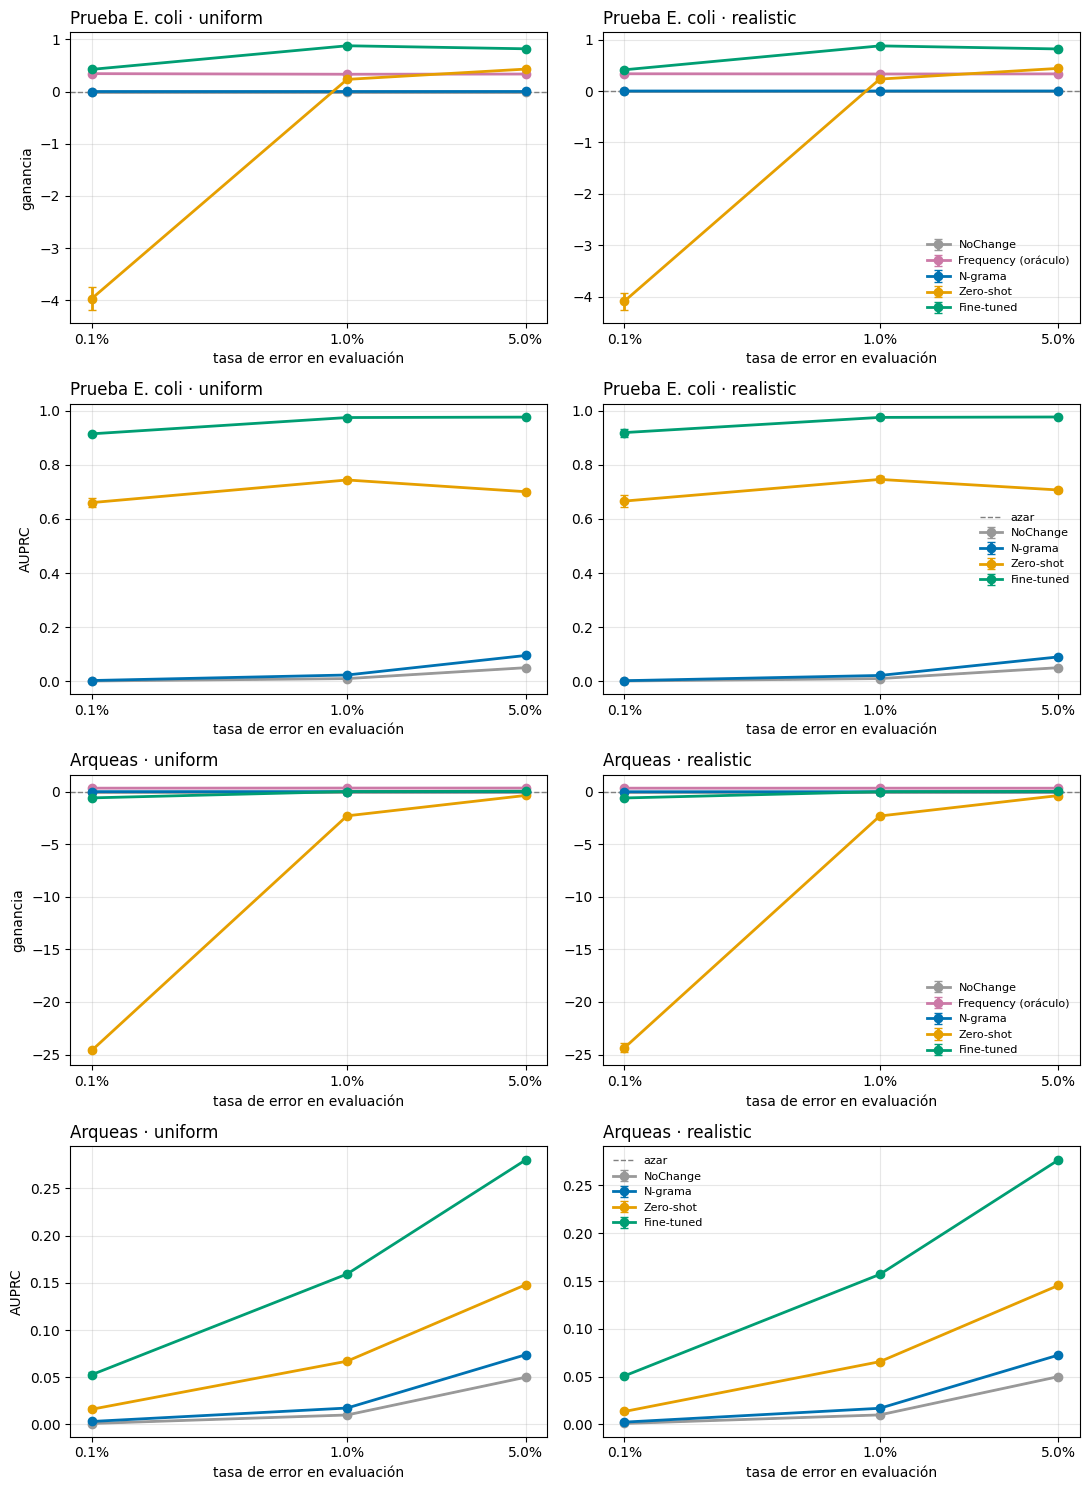

In [ ]:
# Gain and AUPRC against the evaluation error rate, per profile, on the E. coli test set and on the archaea
fig, axes = plt.subplots(4, len(PROFILES), figsize=(11, 15))
for row, (metric, set_name) in enumerate([("gain", "test"), ("auprc", "test"), ("gain", "arch"), ("auprc", "arch")]):
    plot_metric_vs_rate(all_configs, metric, set_name, axes=axes[row])
plt.tight_layout()
plt.show()

#### 8.6.2 Detección perfecta (oráculo)

Solo en las posiciones con error: el modelo elige la base más probable entre las tres distintas de la de entrada, como si supiera dónde están los errores. La exactitud con oráculo se compara con 1/3 (elegir al azar), con Frequency y con el recall de corrección del mismo modelo sin oráculo: la diferencia entre ambos es lo que se pierde por no encontrar los errores. Se reporta por nucleótido y por codón (`codon_`): un codón con error cuenta como corregido por el oráculo solo si todos sus errores quedan corregidos.

In [ ]:
# Correction recall with the model's own detection vs. with perfect detection, on the E. coli test set and on the archaea
oracle_models = ["Frequency", "N-grama", "Zero-shot", "Fine-tuned"]
oracle_configs = all_configs[all_configs["model"].isin(oracle_models)]
for set_name in EVAL_SETS:
    print(f"{SET_NAMES[set_name]} (azar con oráculo: {1 / 3:.4f})")
    display(mean_std_table(oracle_configs, ORACLE_METRICS, set_name))

Prueba E. coli (azar con oráculo: 0.3333)


corr_recall  oracle_accuracy  \
model               rate   profile                                       
Frequency (oráculo) 0.1pct uniform    0.3427 ± 0.0274  0.3427 ± 0.0274   
                           realistic  0.3354 ± 0.0286  0.3354 ± 0.0286   
                    1pct   uniform    0.3312 ± 0.0097  0.3312 ± 0.0097   
                           realistic  0.3310 ± 0.0055  0.3310 ± 0.0055   
                    5pct   uniform    0.3350 ± 0.0023  0.3350 ± 0.0023   
                           realistic  0.3331 ± 0.0039  0.3331 ± 0.0039   
N-grama             0.1pct uniform    0.0005 ± 0.0011  0.4434 ± 0.0184   
                           realistic  0.0000 ± 0.0000  0.4649 ± 0.0237   
                    1pct   uniform    0.0009 ± 0.0001  0.4755 ± 0.0066   
                           realistic  0.0007 ± 0.0005  0.4720 ± 0.0107   
                    5pct   uniform    0.0010 ± 0.0003  0.4605 ± 0.0023   
                           realistic  0.0006 ± 0.0003  0.4572 ± 0.0043   
Zero-shot           0.1pct uniform    0.7376 ± 0.0193  0.9190 ± 0.0052   
                           realistic  0.7316 ± 0.0286  0.9110 ± 0.0135   
                    1pct   uniform    0.7051 ± 0.0038  0.8989 ± 0.0041   
                           realistic  0.7059 ± 0.0122  0.9048 ± 0.0028   
                    5pct   uniform    0.5480 ± 0.0055  0.8493 ± 0.0021   
                           realistic  0.5566 ± 0.0065  0.8498 ± 0.0040   
Fine-tuned          0.1pct uniform    0.9425 ± 0.0074  0.9884 ± 0.0042   
                           realistic  0.9471 ± 0.0148  0.9856 ± 0.0040   
                    1pct   uniform    0.9301 ± 0.0033  0.9859 ± 0.0014   
                           realistic  0.9315 ± 0.0057  0.9845 ± 0.0009   
                    5pct   uniform    0.8325 ± 0.0057  0.9718 ± 0.0013   
                           realistic  0.8322 ± 0.0034  0.9714 ± 0.0012   

                                     codon_corr_recall codon_oracle_accuracy  
model               rate   profile                                            
Frequency (oráculo) 0.1pct uniform     0.3421 ± 0.0285       0.3421 ± 0.0285  
                           realistic   0.3356 ± 0.0284       0.3356 ± 0.0284  
                    1pct   uniform     0.3288 ± 0.0097       0.3288 ± 0.0097  
                           realistic   0.3282 ± 0.0050       0.3282 ± 0.0050  
                    5pct   uniform     0.3228 ± 0.0020       0.3228 ± 0.0020  
                           realistic   0.3206 ± 0.0043       0.3206 ± 0.0043  
N-grama             0.1pct uniform     0.0005 ± 0.0011       0.4438 ± 0.0177  
                           realistic   0.0000 ± 0.0000       0.4646 ± 0.0242  
                    1pct   uniform     0.0009 ± 0.0001       0.4729 ± 0.0063  
                           realistic   0.0007 ± 0.0005       0.4699 ± 0.0111  
                    5pct   uniform     0.0009 ± 0.0002       0.4518 ± 0.0029  
                           realistic   0.0006 ± 0.0003       0.4472 ± 0.0044  
Zero-shot           0.1pct uniform     0.7205 ± 0.0228       0.9189 ± 0.0053  
                           realistic   0.7175 ± 0.0277       0.9109 ± 0.0135  
                    1pct   uniform     0.6918 ± 0.0037       0.8984 ± 0.0045  
                           realistic   0.6902 ± 0.0130       0.9043 ± 0.0026  
                    5pct   uniform     0.5282 ± 0.0056       0.8470 ± 0.0021  
                           realistic   0.5382 ± 0.0069       0.8474 ± 0.0044  
Fine-tuned          0.1pct uniform     0.9389 ± 0.0061       0.9884 ± 0.0043  
                           realistic   0.9436 ± 0.0143       0.9856 ± 0.0040  
                    1pct   uniform     0.9260 ± 0.0025       0.9857 ± 0.0014  
                           realistic   0.9263 ± 0.0061       0.9844 ± 0.0009  
                    5pct   uniform     0.8274 ± 0.0054       0.9713 ± 0.0011  
                           realistic   0.8263 ± 0.0038       0.9709 ± 0.0011

Arqueas (azar con oráculo: 0.3333)


corr_recall  oracle_accuracy  \
model               rate   profile                                       
Frequency (oráculo) 0.1pct uniform    0.3288 ± 0.0061  0.3288 ± 0.0061   
                           realistic  0.3389 ± 0.0121  0.3389 ± 0.0121   
                    1pct   uniform    0.3383 ± 0.0016  0.3383 ± 0.0016   
                           realistic  0.3384 ± 0.0017  0.3384 ± 0.0017   
                    5pct   uniform    0.3377 ± 0.0009  0.3377 ± 0.0009   
                           realistic  0.3367 ± 0.0014  0.3367 ± 0.0014   
N-grama             0.1pct uniform    0.0011 ± 0.0005  0.3811 ± 0.0077   
                           realistic  0.0007 ± 0.0007  0.3884 ± 0.0073   
                    1pct   uniform    0.0008 ± 0.0002  0.3815 ± 0.0025   
                           realistic  0.0007 ± 0.0001  0.3902 ± 0.0030   
                    5pct   uniform    0.0009 ± 0.0000  0.3819 ± 0.0010   
                           realistic  0.0007 ± 0.0001  0.3883 ± 0.0007   
Zero-shot           0.1pct uniform    0.1423 ± 0.0047  0.6280 ± 0.0106   
                           realistic  0.1347 ± 0.0036  0.6317 ± 0.0070   
                    1pct   uniform    0.1358 ± 0.0025  0.6235 ± 0.0014   
                           realistic  0.1345 ± 0.0018  0.6243 ± 0.0011   
                    5pct   uniform    0.1098 ± 0.0009  0.5930 ± 0.0004   
                           realistic  0.1076 ± 0.0010  0.5918 ± 0.0007   
Fine-tuned          0.1pct uniform    0.0857 ± 0.0045  0.6774 ± 0.0095   
                           realistic  0.0819 ± 0.0037  0.6767 ± 0.0073   
                    1pct   uniform    0.0799 ± 0.0014  0.6727 ± 0.0004   
                           realistic  0.0770 ± 0.0011  0.6742 ± 0.0016   
                    5pct   uniform    0.0563 ± 0.0006  0.6464 ± 0.0010   
                           realistic  0.0542 ± 0.0004  0.6467 ± 0.0008   

                                     codon_corr_recall codon_oracle_accuracy  
model               rate   profile                                            
Frequency (oráculo) 0.1pct uniform     0.3285 ± 0.0061       0.3285 ± 0.0061  
                           realistic   0.3386 ± 0.0120       0.3386 ± 0.0120  
                    1pct   uniform     0.3361 ± 0.0016       0.3361 ± 0.0016  
                           realistic   0.3354 ± 0.0017       0.3354 ± 0.0017  
                    5pct   uniform     0.3264 ± 0.0009       0.3264 ± 0.0009  
                           realistic   0.3238 ± 0.0011       0.3238 ± 0.0011  
N-grama             0.1pct uniform     0.0011 ± 0.0005       0.3806 ± 0.0075  
                           realistic   0.0007 ± 0.0007       0.3882 ± 0.0074  
                    1pct   uniform     0.0008 ± 0.0002       0.3791 ± 0.0026  
                           realistic   0.0007 ± 0.0001       0.3877 ± 0.0029  
                    5pct   uniform     0.0008 ± 0.0000       0.3701 ± 0.0011  
                           realistic   0.0007 ± 0.0001       0.3751 ± 0.0006  
Zero-shot           0.1pct uniform     0.1016 ± 0.0049       0.6278 ± 0.0107  
                           realistic   0.0960 ± 0.0032       0.6314 ± 0.0067  
                    1pct   uniform     0.0963 ± 0.0015       0.6222 ± 0.0014  
                           realistic   0.0960 ± 0.0017       0.6228 ± 0.0010  
                    5pct   uniform     0.0765 ± 0.0009       0.5851 ± 0.0006  
                           realistic   0.0746 ± 0.0009       0.5831 ± 0.0010  
Fine-tuned          0.1pct uniform     0.0805 ± 0.0039       0.6772 ± 0.0095  
                           realistic   0.0765 ± 0.0029       0.6764 ± 0.0074  
                    1pct   uniform     0.0751 ± 0.0020       0.6713 ± 0.0005  
                           realistic   0.0718 ± 0.0010       0.6727 ± 0.0015  
                    5pct   uniform     0.0525 ± 0.0007       0.6391 ± 0.0011  
                           realistic   0.0506 ± 0.0004       0.6386 ± 0.0008

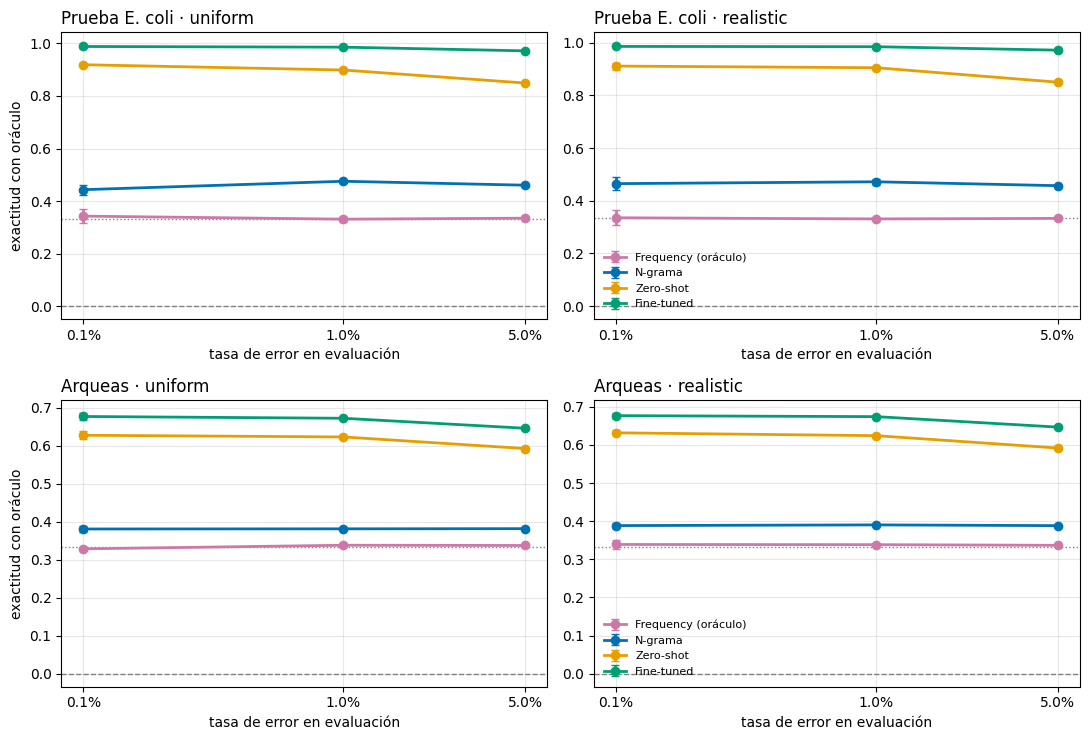

In [ ]:
# Accuracy with perfect detection against the evaluation error rate, with random choice (1/3) as reference
fig, axes = plt.subplots(2, len(PROFILES), figsize=(11, 7.5))
for row, set_name in enumerate(EVAL_SETS):
    plot_metric_vs_rate(all_configs, "oracle_accuracy", set_name, model_names=oracle_models, axes=axes[row])
    for ax in axes[row]:
        ax.axhline(1 / 3, color="gray", linewidth=1, linestyle=":")
plt.tight_layout()
plt.show()

#### 8.6.3 Exactitud a nivel de gen

Porcentaje de genes que quedan idénticos al original. Con tasas bajas muchos genes no reciben ningún error y NoChange ya los deja perfectos, así que el porcentaje se lee junto a su referencia (`pct_reference`). `pct_repaired` es el porcentaje de genes con errores que quedan perfectos y `pct_damaged` el de genes sin errores que el modelo daña.

In [ ]:
# Gene-level accuracy of every model on the E. coli test set and on the archaea
for set_name in EVAL_SETS:
    print(SET_NAMES[set_name])
    display(mean_std_table(all_configs, GENE_METRICS, set_name))

Prueba E. coli


pct_perfect    pct_reference  \
model               rate   profile                                       
NoChange            0.1pct uniform    0.4517 ± 0.0103  0.4517 ± 0.0103   
                           realistic  0.4573 ± 0.0067  0.4573 ± 0.0067   
                    1pct   uniform    0.0245 ± 0.0074  0.0245 ± 0.0074   
                           realistic  0.0263 ± 0.0067  0.0263 ± 0.0067   
                    5pct   uniform    0.0005 ± 0.0010  0.0005 ± 0.0010   
                           realistic  0.0009 ± 0.0013  0.0009 ± 0.0013   
Frequency (oráculo) 0.1pct uniform    0.5769 ± 0.0211  0.4517 ± 0.0103   
                           realistic  0.5704 ± 0.0153  0.4573 ± 0.0067   
                    1pct   uniform    0.0527 ± 0.0085  0.0245 ± 0.0074   
                           realistic  0.0508 ± 0.0073  0.0263 ± 0.0067   
                    5pct   uniform    0.0018 ± 0.0019  0.0005 ± 0.0010   
                           realistic  0.0014 ± 0.0013  0.0009 ± 0.0013   
N-grama             0.1pct uniform    0.4522 ± 0.0097  0.4517 ± 0.0103   
                           realistic  0.4573 ± 0.0067  0.4573 ± 0.0067   
                    1pct   uniform    0.0254 ± 0.0077  0.0245 ± 0.0074   
                           realistic  0.0263 ± 0.0067  0.0263 ± 0.0067   
                    5pct   uniform    0.0005 ± 0.0010  0.0005 ± 0.0010   
                           realistic  0.0009 ± 0.0013  0.0009 ± 0.0013   
Zero-shot           0.1pct uniform    0.1533 ± 0.0078  0.4517 ± 0.0103   
                           realistic  0.1510 ± 0.0058  0.4573 ± 0.0067   
                    1pct   uniform    0.0277 ± 0.0083  0.0245 ± 0.0074   
                           realistic  0.0291 ± 0.0081  0.0263 ± 0.0067   
                    5pct   uniform    0.0005 ± 0.0010  0.0005 ± 0.0010   
                           realistic  0.0014 ± 0.0013  0.0009 ± 0.0013   
Fine-tuned          0.1pct uniform    0.6249 ± 0.0069  0.4517 ± 0.0103   
                           realistic  0.6291 ± 0.0058  0.4573 ± 0.0067   
                    1pct   uniform    0.4092 ± 0.0143  0.0245 ± 0.0074   
                           realistic  0.3968 ± 0.0168  0.0263 ± 0.0067   
                    5pct   uniform    0.0125 ± 0.0035  0.0005 ± 0.0010   
                           realistic  0.0120 ± 0.0058  0.0009 ± 0.0013   

                                         pct_repaired      pct_damaged  
model               rate   profile                                      
NoChange            0.1pct uniform    0.0000 ± 0.0000  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    1pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    5pct   uniform    0.0000 ± 0.0000           0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
Frequency (oráculo) 0.1pct uniform    0.2286 ± 0.0247  0.0000 ± 0.0000  
                           realistic  0.2085 ± 0.0270  0.0000 ± 0.0000  
                    1pct   uniform    0.0289 ± 0.0054  0.0000 ± 0.0000  
                           realistic  0.0251 ± 0.0063  0.0000 ± 0.0000  
                    5pct   uniform    0.0014 ± 0.0013           0.0000  
                           realistic  0.0005 ± 0.0010  0.0000 ± 0.0000  
N-grama             0.1pct uniform    0.0008 ± 0.0018  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    1pct   uniform    0.0009 ± 0.0013  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    5pct   uniform    0.0000 ± 0.0000           0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
Zero-shot           0.1pct uniform    0.0184 ± 0.0103  0.6829 ± 0.0103  
                           realistic  0.0170 ± 0.0078  0.6900 ± 0.0181  
                    1pct   uniform    0.0047 ± 0.0017  0.0517 ± 0.0

Arqueas


pct_perfect    pct_reference  \
model               rate   profile                                       
NoChange            0.1pct uniform    0.4795 ± 0.0038  0.4795 ± 0.0038   
                           realistic  0.4742 ± 0.0036  0.4742 ± 0.0036   
                    1pct   uniform    0.0196 ± 0.0020  0.0196 ± 0.0020   
                           realistic  0.0196 ± 0.0026  0.0196 ± 0.0026   
                    5pct   uniform    0.0001 ± 0.0001  0.0001 ± 0.0001   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Frequency (oráculo) 0.1pct uniform    0.5968 ± 0.0061  0.4795 ± 0.0038   
                           realistic  0.5983 ± 0.0059  0.4742 ± 0.0036   
                    1pct   uniform    0.0491 ± 0.0043  0.0196 ± 0.0020   
                           realistic  0.0480 ± 0.0021  0.0196 ± 0.0026   
                    5pct   uniform    0.0003 ± 0.0002  0.0001 ± 0.0001   
                           realistic  0.0002 ± 0.0002  0.0000 ± 0.0000   
N-grama             0.1pct uniform    0.4795 ± 0.0037  0.4795 ± 0.0038   
                           realistic  0.4741 ± 0.0036  0.4742 ± 0.0036   
                    1pct   uniform    0.0200 ± 0.0020  0.0196 ± 0.0020   
                           realistic  0.0197 ± 0.0024  0.0196 ± 0.0026   
                    5pct   uniform    0.0001 ± 0.0001  0.0001 ± 0.0001   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Zero-shot           0.1pct uniform    0.1508 ± 0.0037  0.4795 ± 0.0038   
                           realistic  0.1510 ± 0.0027  0.4742 ± 0.0036   
                    1pct   uniform    0.0128 ± 0.0008  0.0196 ± 0.0020   
                           realistic  0.0132 ± 0.0010  0.0196 ± 0.0026   
                    5pct   uniform    0.0001 ± 0.0001  0.0001 ± 0.0001   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Fine-tuned          0.1pct uniform    0.4084 ± 0.0029  0.4795 ± 0.0038   
                           realistic  0.4077 ± 0.0038  0.4742 ± 0.0036   
                    1pct   uniform    0.0211 ± 0.0022  0.0196 ± 0.0020   
                           realistic  0.0204 ± 0.0018  0.0196 ± 0.0026   
                    5pct   uniform    0.0001 ± 0.0001  0.0001 ± 0.0001   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   

                                         pct_repaired      pct_damaged  
model               rate   profile                                      
NoChange            0.1pct uniform    0.0000 ± 0.0000  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    1pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000  
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000  
                    5pct   uniform    0.0000 ± 0.0000           0.0000  
                           realistic  0.0000 ± 0.0000                —  
Frequency (oráculo) 0.1pct uniform    0.2254 ± 0.0074  0.0000 ± 0.0000  
                           realistic  0.2361 ± 0.0086  0.0000 ± 0.0000  
                    1pct   uniform    0.0300 ± 0.0039  0.0000 ± 0.0000  
                           realistic  0.0290 ± 0.0013  0.0000 ± 0.0000  
                    5pct   uniform    0.0002 ± 0.0002           0.0000  
                           realistic  0.0002 ± 0.0002                —  
N-grama             0.1pct uniform    0.0008 ± 0.0006  0.0009 ± 0.0006  
                           realistic  0.0005 ± 0.0005  0.0008 ± 0.0006  
                    1pct   uniform    0.0004 ± 0.0004  0.0000 ± 0.0000  
                           realistic  0.0002 ± 0.0002  0.0000 ± 0.0000  
                    5pct   uniform    0.0000 ± 0.0000           0.0000  
                           realistic  0.0000 ± 0.0000                —  
Zero-shot           0.1pct uniform    0.0022 ± 0.0011  0.6879 ± 0.0057  
                           realistic  0.0013 ± 0.0006  0.6830 ± 0.0070  
                    1pct   uniform    0.0002 ± 0.0001  0.3527 ± 0.0

#### 8.6.4 Nivel de codón y posición en el codón

Las métricas a nivel de codón cuentan codones en vez de nucleótidos: un codón con error se cuenta como corregido solo si queda idéntico al original, así que es más estricto cuando un codón tiene más de un error. El desglose por posición del nucleótido en el codón (1.ª, 2.ª o 3.ª) muestra si la tercera posición, donde se concentran las sustituciones sinónimas, es la más difícil; se reporta en todas las tasas y en los dos conjuntos, juntando los dos perfiles y las 5 semillas (media ± desviación sobre esas 10 configuraciones).

In [ ]:
# Codon-level metrics on the E. coli test set
mean_std_table(all_configs, CODON_METRICS, "test")

codon_gain codon_det_precision  \
model               rate   profile                                           
NoChange            0.1pct uniform     0.0000 ± 0.0000                   —   
                           realistic   0.0000 ± 0.0000                   —   
                    1pct   uniform     0.0000 ± 0.0000                   —   
                           realistic   0.0000 ± 0.0000                   —   
                    5pct   uniform     0.0000 ± 0.0000                   —   
                           realistic   0.0000 ± 0.0000                   —   
Frequency (oráculo) 0.1pct uniform     0.3421 ± 0.0285                   —   
                           realistic   0.3356 ± 0.0284                   —   
                    1pct   uniform     0.3288 ± 0.0097                   —   
                           realistic   0.3282 ± 0.0050                   —   
                    5pct   uniform     0.3228 ± 0.0020                   —   
                           realistic   0.3206 ± 0.0043                   —   
N-grama             0.1pct uniform     0.0005 ± 0.0011              1.0000   
                           realistic   0.0000 ± 0.0000                   —   
                    1pct   uniform     0.0009 ± 0.0001     1.0000 ± 0.0000   
                           realistic   0.0007 ± 0.0005     1.0000 ± 0.0000   
                    5pct   uniform     0.0009 ± 0.0002     1.0000 ± 0.0000   
                           realistic   0.0006 ± 0.0003     1.0000 ± 0.0000   
Zero-shot           0.1pct uniform    -3.3299 ± 0.1887     0.1569 ± 0.0064   
                           realistic  -3.4307 ± 0.1507     0.1540 ± 0.0078   
                    1pct   uniform     0.2957 ± 0.0087     0.6455 ± 0.0039   
                           realistic   0.2917 ± 0.0135     0.6450 ± 0.0039   
                    5pct   uniform     0.4436 ± 0.0089     0.8722 ± 0.0061   
                           realistic   0.4533 ± 0.0093     0.8737 ± 0.0048   
Fine-tuned          0.1pct uniform     0.4297 ± 0.0186     0.6505 ± 0.0085   
                           realistic   0.4164 ± 0.0317     0.6438 ± 0.0117   
                    1pct   uniform     0.8787 ± 0.0041     0.9520 ± 0.0024   
                           realistic   0.8789 ± 0.0064     0.9519 ± 0.0011   
                    5pct   uniform     0.8211 ± 0.0055     0.9927 ± 0.0004   
                           realistic   0.8197 ± 0.0036     0.9924 ± 0.0005   

                                     codon_det_recall     codon_det_f1  \
model               rate   profile                                       
NoChange            0.1pct uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    1pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    5pct   uniform    0.0000 ± 0.0000  0.0000 ± 0.0000   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
Frequency (oráculo) 0.1pct uniform                  —                —   
                           realistic                —                —   
                    1pct   uniform                  —                —   
                           realistic                —                —   
                    5pct   uniform                  —                —   
                           realistic                —                —   
N-grama             0.1pct uniform    0.0005 ± 0.0011  0.0010 ± 0.0021   
                           realistic  0.0000 ± 0.0000  0.0000 ± 0.0000   
                    1pct   uniform    0.0010 ± 0.0002  0.0020 ± 0.0003   
                           realistic  0.0008 ± 0.0004  0.0017 ± 0.0008   
                    5pct   uniform    0.0011 ± 0.0003  0.0022 ± 0.0005   
                           realistic  0.0007 ± 0.0003  0.0014 ± 0.0006   
Zero-shot           0.1pct uniform    0.7529 ± 0.0150  0.2597 ± 0.0

In [ ]:
# Metrics reported per position of the nucleotide in the codon
POSITION_METRICS = ["gain", "det_precision", "det_recall", "det_f1", "corr_recall", "corr_f1",
                    "overcorrection", "oracle_accuracy"]

In [ ]:
def codon_position_table(configs, model_names):
    """
    Reshapes the per-codon-position metrics into one row per position.

    The metrics of each position ("c1_", "c2_", "c3_" columns of config_metrics) are
    stacked under a "position" column (1, 2 or 3), so they can be summarized like the
    other metrics.

    Parameters
    ----------
    configs : pandas.DataFrame
        Metrics per configuration of every model.
    model_names : list of str
        Models to include.

    Returns
    -------
    table : pandas.DataFrame
        One row per (model, set, rate, profile, seed, position) with POSITION_METRICS.
    """
    data = configs[configs["model"].isin(model_names)]
    keys = ["model", "set", "rate", "profile", "seed"]
    frames = [data[keys + [f"c{k}_{m}" for m in POSITION_METRICS]]
              .rename(columns={f"c{k}_{m}": m for m in POSITION_METRICS}).assign(position=k)
              for k in (1, 2, 3)]
    return pd.concat(frames, ignore_index=True)

In [ ]:
# Metrics per codon position, every error rate, both profiles and the 5 seeds pooled (mean ± std over the 10 configurations), on the E. coli test set and on the archaea
position_models = ["N-grama", "Zero-shot", "Fine-tuned"]
position_table = codon_position_table(all_configs, position_models)
for set_name in EVAL_SETS:
    print(SET_NAMES[set_name])
    display(mean_std_table(position_table, POSITION_METRICS, set_name, by=("model", "rate", "position")))

Prueba E. coli


gain    det_precision  \
model      rate   position                                      
N-grama    0.1pct 1          0.0007 ± 0.0022           1.0000   
                  2          0.0000 ± 0.0000                —   
                  3          0.0000 ± 0.0000                —   
           1pct   1          0.0004 ± 0.0007  0.8000 ± 0.4472   
                  2          0.0000 ± 0.0000                —   
                  3          0.0019 ± 0.0011  1.0000 ± 0.0000   
           5pct   1          0.0006 ± 0.0004  1.0000 ± 0.0000   
                  2          0.0000 ± 0.0000                —   
                  3          0.0018 ± 0.0007  1.0000 ± 0.0000   
Zero-shot  0.1pct 1         -2.8822 ± 0.1805  0.1751 ± 0.0066   
                  2         -2.0459 ± 0.2221  0.2231 ± 0.0171   
                  3         -7.3327 ± 0.6325  0.0756 ± 0.0071   
           1pct   1          0.3601 ± 0.0198  0.6659 ± 0.0098   
                  2          0.4817 ± 0.0148  0.7247 ± 0.0091   
                  3         -0.1379 ± 0.0225  0.4558 ± 0.0086   
           5pct   1          0.4822 ± 0.0091  0.8704 ± 0.0067   
                  2          0.5722 ± 0.0092  0.8907 ± 0.0040   
                  3          0.2506 ± 0.0200  0.7124 ± 0.0137   
Fine-tuned 0.1pct 1          0.6328 ± 0.0299  0.7443 ± 0.0119   
                  2          0.6770 ± 0.0335  0.7674 ± 0.0167   
                  3         -0.0795 ± 0.0858  0.4819 ± 0.0222   
           1pct   1          0.9118 ± 0.0070  0.9616 ± 0.0026   
                  2          0.9304 ± 0.0030  0.9656 ± 0.0023   
                  3          0.7917 ± 0.0105  0.9109 ± 0.0040   
           5pct   1          0.8607 ± 0.0050  0.9862 ± 0.0011   
                  2          0.9033 ± 0.0029  0.9851 ± 0.0008   
                  3          0.6918 ± 0.0095  0.9794 ± 0.0017   

                                 det_recall           det_f1      corr_recall  \
model      rate   position                                                      
N-grama    0.1pct 1         0.0007 ± 0.0022  0.0014 ± 0.0045  0.0007 ± 0.0022   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
           1pct   1         0.0004 ± 0.0006  0.0009 ± 0.0013  0.0004 ± 0.0006   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0022 ± 0.0011  0.0043 ± 0.0021  0.0019 ± 0.0011   
           5pct   1         0.0007 ± 0.0005  0.0014 ± 0.0009  0.0006 ± 0.0004   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0018 ± 0.0007  0.0037 ± 0.0014  0.0018 ± 0.0007   
Zero-shot  0.1pct 1         0.7731 ± 0.0355  0.2855 ± 0.0100  0.7628 ± 0.0325   
                  2         0.8161 ± 0.0394  0.3503 ± 0.0237  0.8068 ± 0.0406   
                  3         0.6478 ± 0.0421  0.1353 ± 0.0120  0.6304 ± 0.0372   
           1pct   1         0.7390 ± 0.0135  0.7005 ± 0.0093  0.7310 ± 0.0127   
                  2         0.7873 ± 0.0102  0.7547 ± 0.0066  0.7809 ± 0.0107   
                  3         0.6235 ± 0.0136  0.5266 ± 0.0102  0.6066 ± 0.0129   
           5pct   1         0.5805 ± 0.0061  0.6965 ± 0.0058  0.5687 ± 0.0065   
                  2         0.6633 ± 0.0080  0.7604 ± 0.0059  0.6536 ± 0.0086   
                  3         0.4567 ± 0.0149  0.5565 ± 0.0143  0.4349 ± 0.0153   
Fine-tuned 0.1pct 1         0.9677 ± 0.0161  0.8414 ± 0.0117  0.9655 ± 0.0190   
                  2         0.9729 ± 0.0169  0.8579 ± 0.0149  0.9723 ± 0.0164   
                  3         0.9030 ± 0.0278  0.6282 ± 0.0226  0.8941 ± 0.0275   
           1pct   1         0.9533 ± 0.0065  0.9574 ± 0.0038  0.9499 ± 0.0062   
                  2         0.9664 ± 0.0036  0.9660 ± 0.0013  0.9649 ± 0.0040   
                  3         0.8890 ± 0.0091  0.8998 ± 0.0057  0.8786 ± 0.0086   
           5pct   1         0.8803 ± 0.0047  0.9

Arqueas


gain    det_precision  \
model      rate   position                                       
N-grama    0.1pct 1          -0.0039 ± 0.0006  0.1119 ± 0.1029   
                  2           0.0000 ± 0.0000                —   
                  3           0.0020 ± 0.0016  1.0000 ± 0.0000   
           1pct   1          -0.0000 ± 0.0001  0.5310 ± 0.1058   
                  2           0.0000 ± 0.0000                —   
                  3           0.0018 ± 0.0003  1.0000 ± 0.0000   
           5pct   1           0.0004 ± 0.0003  0.8283 ± 0.0871   
                  2           0.0000 ± 0.0000  1.0000 ± 0.0000   
                  3           0.0018 ± 0.0001  1.0000 ± 0.0000   
Zero-shot  0.1pct 1         -24.5611 ± 0.4133  0.0069 ± 0.0005   
                  2         -25.6931 ± 0.8809  0.0078 ± 0.0006   
                  3         -23.2448 ± 0.4942  0.0070 ± 0.0004   
           1pct   1          -2.3107 ± 0.0230  0.0625 ± 0.0020   
                  2          -2.4308 ± 0.0358  0.0705 ± 0.0017   
                  3          -2.1772 ± 0.0163  0.0678 ± 0.0015   
           5pct   1          -0.3740 ± 0.0047  0.2247 ± 0.0031   
                  2          -0.3933 ± 0.0041  0.2373 ± 0.0023   
                  3          -0.3259 ± 0.0020  0.2464 ± 0.0039   
Fine-tuned 0.1pct 1          -0.3372 ± 0.0129  0.1923 ± 0.0162   
                  2          -1.1945 ± 0.0402  0.0962 ± 0.0059   
                  3          -0.2545 ± 0.0105  0.1436 ± 0.0148   
           1pct   1           0.0250 ± 0.0024  0.6351 ± 0.0081   
                  2          -0.0149 ± 0.0053  0.4988 ± 0.0102   
                  3           0.0076 ± 0.0028  0.5879 ± 0.0158   
           5pct   1           0.0362 ± 0.0011  0.7703 ± 0.0039   
                  2           0.0583 ± 0.0015  0.7772 ± 0.0054   
                  3           0.0152 ± 0.0014  0.7799 ± 0.0106   

                                 det_recall           det_f1      corr_recall  \
model      rate   position                                                      
N-grama    0.1pct 1         0.0006 ± 0.0006  0.0013 ± 0.0012  0.0006 ± 0.0006   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0029 ± 0.0023  0.0057 ± 0.0046  0.0020 ± 0.0016   
           1pct   1         0.0005 ± 0.0002  0.0010 ± 0.0005  0.0004 ± 0.0001   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0021 ± 0.0004  0.0041 ± 0.0008  0.0018 ± 0.0003   
           5pct   1         0.0006 ± 0.0003  0.0012 ± 0.0006  0.0005 ± 0.0003   
                  2         0.0000 ± 0.0000  0.0000 ± 0.0000  0.0000 ± 0.0000   
                  3         0.0022 ± 0.0002  0.0044 ± 0.0004  0.0018 ± 0.0001   
Zero-shot  0.1pct 1         0.1704 ± 0.0113  0.0132 ± 0.0009  0.1273 ± 0.0118   
                  2         0.2028 ± 0.0104  0.0150 ± 0.0011  0.1626 ± 0.0080   
                  3         0.1656 ± 0.0100  0.0135 ± 0.0008  0.1255 ± 0.0091   
           1pct   1         0.1622 ± 0.0050  0.0902 ± 0.0028  0.1231 ± 0.0040   
                  2         0.1960 ± 0.0035  0.1037 ± 0.0022  0.1556 ± 0.0031   
                  3         0.1675 ± 0.0034  0.0965 ± 0.0020  0.1268 ± 0.0041   
           5pct   1         0.1376 ± 0.0024  0.1707 ± 0.0026  0.1007 ± 0.0016   
                  2         0.1607 ± 0.0020  0.1916 ± 0.0021  0.1231 ± 0.0019   
                  3         0.1400 ± 0.0034  0.1785 ± 0.0038  0.1023 ± 0.0025   
Fine-tuned 0.1pct 1         0.1000 ± 0.0098  0.1316 ± 0.0123  0.0824 ± 0.0093   
                  2         0.1404 ± 0.0081  0.1142 ± 0.0066  0.1255 ± 0.0086   
                  3         0.0500 ± 0.0057  0.0742 ± 0.0082  0.0437 ± 0.0050   
           1pct   1         0.0944 ± 0.0026  0.1643 ± 0.0042  0.0792 ± 0.0019   
                  2         0.1329 ± 0.0033  0.2099 ± 0.0048  0.1187 ± 0.0031   
                  3         0.0428 ± 0.0029  0.0799 ± 0.0051  0.0376 ± 0.0030   
           5pct   1 

In [ ]:
def plot_codon_position(table, metric, set_name, r_name, ax):
    """
    Plots a metric per codon position as grouped bars, one bar per model.

    Parameters
    ----------
    table : pandas.DataFrame
        Per-position metrics, as returned by codon_position_table.
    metric : str
        Metric to plot.
    set_name : str
        Set ("test" or "arch").
    r_name : str
        Error rate, a key of RATES; both profiles and every seed are averaged.
    ax : matplotlib.axes.Axes
        Axes to draw on.
    """
    data = table[(table["set"] == set_name) & (table["rate"] == r_name)]
    model_names = list(dict.fromkeys(data["model"]))
    width = 0.8 / len(model_names)
    for j, m in enumerate(model_names):
        g = data[data["model"] == m].groupby("position")[metric]
        ax.bar(np.array([1, 2, 3]) + (j - (len(model_names) - 1) / 2) * width, g.mean().reindex([1, 2, 3]),
               width, yerr=g.std().reindex([1, 2, 3]), capsize=3, color=MODEL_COLORS.get(m, "black"), label=m)
    ax.set_xticks([1, 2, 3])
    ax.set_xticklabels(["1.ª", "2.ª", "3.ª"])
    ax.set_xlabel("posición en el codón")
    ax.set_ylabel(METRIC_NAMES.get(metric, metric))
    ax.set_title(f"{SET_NAMES[set_name]} · {r_name}", loc="left")
    ax.grid(alpha=0.3, axis="y")

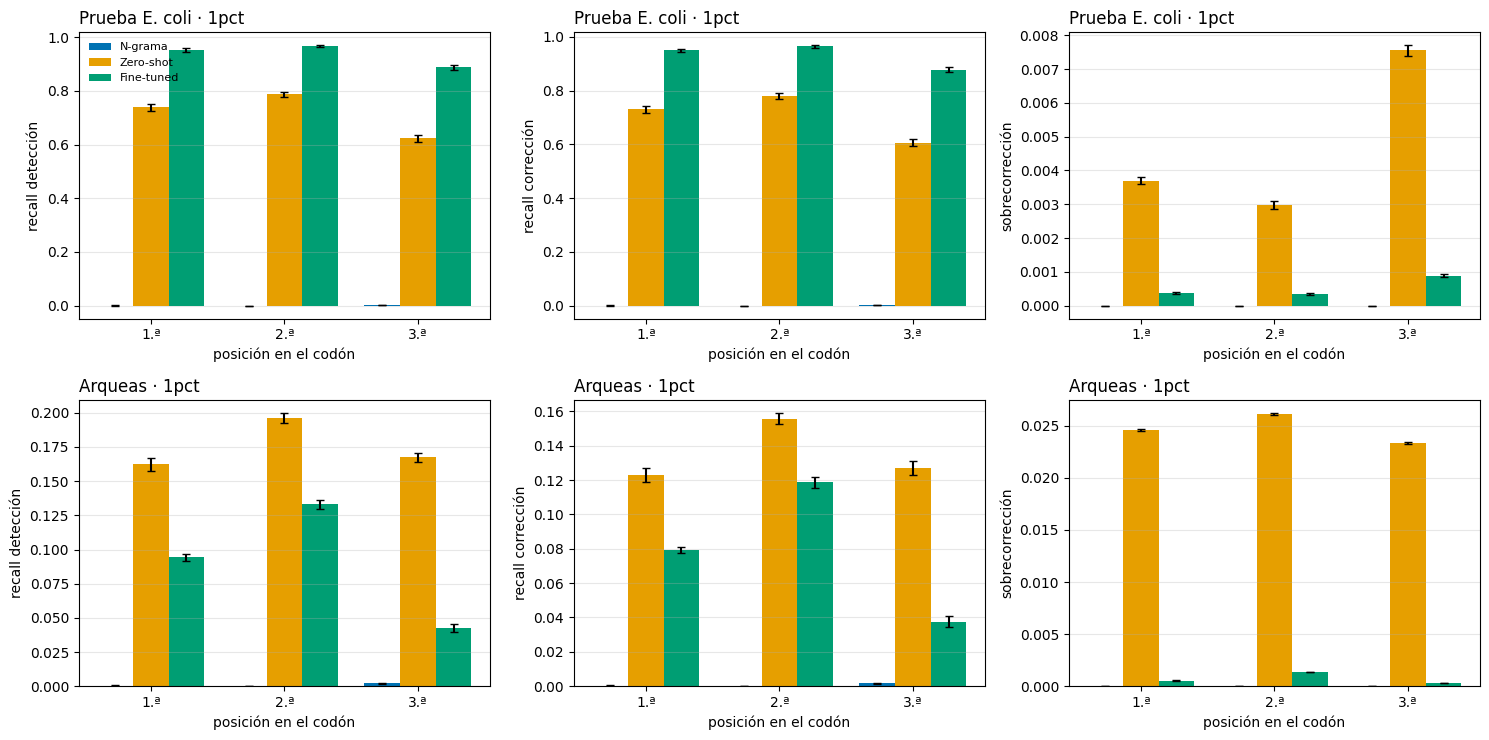

In [ ]:
# Detection recall, correction recall and overcorrection per codon position at 1% errors, on the E. coli test set and on the archaea
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for row, set_name in enumerate(EVAL_SETS):
    for col, metric in enumerate(["det_recall", "corr_recall", "overcorrection"]):
        plot_codon_position(position_table, metric, set_name, "1pct", axes[row, col])
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

#### 8.6.5 Desglose por categorías

Recall de detección, recall de corrección y exactitud con oráculo según el efecto del error en la proteína (sinónimo, no sinónimo o sin sentido, es decir, que crea un codón de parada), el tipo de sustitución y la ubicación del error (codón de inicio, de parada o interior). Se usa la tasa del 1 % (las 5 semillas juntas). El efecto se evalúa por error, cambiando solo esa base del codón original; en el primer codón cualquier codón de inicio válido equivale a metionina.

In [ ]:
# Genetic code of translation table 11 (bacteria and archaea), with "*" for the stop codons
TABLE_11 = CodonTable.unambiguous_dna_by_id[11]
GENETIC_CODE = {**TABLE_11.forward_table, **{c: "*" for c in TABLE_11.stop_codons}}

In [ ]:
def substitution_effect(codon_original, codon_mutated, first_codon):
    """
    Classifies the effect of a substitution on the protein.

    Parameters
    ----------
    codon_original : str
        Original codon.
    codon_mutated : str
        Codon with the substitution.
    first_codon : bool
        Whether it is the start codon of the gene, where every valid start codon is read
        as methionine.

    Returns
    -------
    effect : str
        "sinónimo" (same amino acid), "sin sentido" (a stop codon appears) or
        "no sinónimo" (another amino acid, a wrong start codon or a lost stop codon).
    """
    if first_codon:
        if codon_mutated in CODONES_INICIO:
            return "sinónimo"
    elif GENETIC_CODE[codon_mutated] == GENETIC_CODE[codon_original]:
        return "sinónimo"
    return "sin sentido" if GENETIC_CODE[codon_mutated] == "*" else "no sinónimo"

In [ ]:
def error_table(df, compact):
    """
    Lists every error position of one noisy column with its categories and outcome.

    Parameters
    ----------
    df : pandas.DataFrame
        Genes with the clean column "seq", in the order used for the predictions.
    compact : dict
        Compact predictions of the column, as returned by compact_predictions.

    Returns
    -------
    errors : pandas.DataFrame
        One row per error with "effect", "substitution" (e.g. "A>G", original > noisy),
        "location" ("inicio", "parada" or "interior"), "codon_position" (1, 2 or 3),
        "detected", "fixed" and "oracle_fixed".
    """
    seqs = df["seq"].tolist()
    lengths = np.array([len(s) for s in seqs])
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    joined = "".join(seqs)
    orig = np.frombuffer(joined.encode(), dtype="S1")

    is_error = compact["inp"] != orig[compact["pos"]]
    pos = compact["pos"][is_error]
    inp, out, oracle = (compact[k][is_error].astype(str) for k in ["inp", "out", "oracle"])
    gene = np.searchsorted(starts, pos, side="right") - 1
    local = pos - starts[gene]

    rows = []
    for p, i, o, orc, g, loc in zip(pos, inp, out, oracle, gene, local):
        k = loc % 3
        codon_original = joined[p - k:p - k + 3]
        codon_mutated = codon_original[:k] + i + codon_original[k + 1:]
        rows.append({
            "effect": substitution_effect(codon_original, codon_mutated, loc < 3),
            "substitution": f"{joined[p]}>{i}",
            "location": "inicio" if loc < 3 else "parada" if loc >= lengths[g] - 3 else "interior",
            "codon_position": k + 1,
            "detected": o != i,
            "fixed": o == joined[p],
            "oracle_fixed": orc == joined[p],
        })
    return pd.DataFrame(rows)

In [ ]:
def category_summary(model_names, set_name, r_name, by):
    """
    Summarizes the outcome of the errors of one error rate by category.

    Parameters
    ----------
    model_names : list of str
        Models to include (with real probabilities, so the oracle applies).
    set_name : str
        Set ("test" or "arch").
    r_name : str
        Error rate, a key of RATES; both profiles and every seed are pooled.
    by : str
        Category column of error_table ("effect", "substitution", "location").

    Returns
    -------
    summary : pandas.DataFrame
        One row per (category, model) with the number of errors, the detection recall,
        the correction recall and the oracle accuracy.
    """
    tables = []
    for m in model_names:
        for (rate, profile, seed), compact in EVALUATION[m]["compacts"][set_name].items():
            if rate == r_name:
                tables.append(error_table(EVAL_SETS[set_name], compact).assign(model=m))
    errors = pd.concat(tables, ignore_index=True)
    summary = errors.groupby([by, "model"], sort=True).agg(
        errors=("detected", "size"), det_recall=("detected", "mean"),
        corr_recall=("fixed", "mean"), oracle_accuracy=("oracle_fixed", "mean"))
    return summary.round(4)

In [ ]:
# Outcome of the errors by effect on the protein, substitution type and location, at 1% errors on the E. coli test set
category_models = ["N-grama", "Zero-shot", "Fine-tuned"]
for by in ["effect", "location", "substitution"]:
    display(category_summary(category_models, "test", "1pct", by).unstack("model"))

errors                   det_recall                    \
model       Fine-tuned N-grama Zero-shot Fine-tuned N-grama Zero-shot   
effect                                                                  
no sinónimo      29821   29821     29821     0.9604  0.0010    0.7494   
sin sentido       1425    1425      1425     0.9853  0.0000    0.9018   
sinónimo          9968    9968      9968     0.8558  0.0006    0.5895   

            corr_recall                   oracle_accuracy                    
model        Fine-tuned N-grama Zero-shot      Fine-tuned N-grama Zero-shot  
effect                                                                       
no sinónimo      0.9567  0.0009    0.7410          0.9877  0.4658    0.9141  
sin sentido      0.9796  0.0000    0.8596          0.9909  0.4484    0.9172  
sinónimo         0.8463  0.0006    0.5774          0.9768  0.5012    0.8630

errors                   det_recall                    \
model    Fine-tuned N-grama Zero-shot Fine-tuned N-grama Zero-shot   
location                                                             
inicio           85      85        85     0.7765  0.0706    0.5765   
interior      40990   40990     40990     0.9369  0.0000    0.7182   
parada          139     139       139     0.7626  0.2158    0.1511   

         corr_recall                   oracle_accuracy                    
model     Fine-tuned N-grama Zero-shot      Fine-tuned N-grama Zero-shot  
location                                                                  
inicio        0.7765  0.0706    0.5647          0.9647  0.9882    0.7529  
interior      0.9317  0.0000    0.7081          0.9853  0.4712    0.9047  
parada        0.7482  0.1942    0.0288          0.9712  0.9137    0.1583

errors                   det_recall                    \
model        Fine-tuned N-grama Zero-shot Fine-tuned N-grama Zero-shot   
substitution                                                             
A>C                3175    3175      3175     0.9524  0.0057    0.7058   
A>G                3348    3348      3348     0.9017  0.0000    0.6700   
A>T                3242    3242      3242     0.9500  0.0046    0.7196   
C>A                3377    3377      3377     0.9497  0.0000    0.7329   
C>G                3462    3462      3462     0.9607  0.0000    0.7207   
C>T                3456    3456      3456     0.8927  0.0000    0.6858   
G>A                3786    3786      3786     0.9086  0.0000    0.6910   
G>C                3804    3804      3804     0.9537  0.0005    0.7369   
G>T                3807    3807      3807     0.9567  0.0003    0.7515   
T>A                3255    3255      3255     0.9502  0.0000    0.7404   
T>C                3286    3286      3286     0.9075  0.0000    0.6975   
T>G                3216    3216      3216     0.9481  0.0000    0.7369   

             corr_recall                   oracle_accuracy                    
model         Fine-tuned N-grama Zero-shot      Fine-tuned N-grama Zero-shot  
substitution                                                                  
A>C               0.9468  0.0057    0.6923          0.9836  0.3241    0.8791  
A>G               0.8990  0.0000    0.6640          0.9919  0.4465    0.9444  
A>T               0.9448  0.0046    0.7082          0.9886  0.3069    0.8868  
C>A               0.9440  0.0000    0.7178          0.9822  0.3725    0.8952  
C>G               0.9549  0.0000    0.7097          0.9856  0.5012    0.8541  
C>T               0.8877  0.0000    0.6756          0.9861  0.4051    0.9253  
G>A               0.9070  0.0000    0.6852          0.9934  0.7039    0.9345  
G>C               0.9487  0.0000    0.7261          0.9848  0.7085    0.8906  
G>T               0.9522  0.0000    0.7428          0.9835  0.6882    0.9133  
T>A               0.9410  0.0000    0.7278          0.9785  0.3379    0.8879  
T>C               0.9044  0.0000    0.6902          0.9893  0.3344    0.9270  
T>G               0.9384  0.0000    0.7223          0.9736  0.4459    0.8781

**Sustituciones hechas por los modelos (matrices 4×4)**

Dos lecturas complementarias, con la tasa del 1 % (los dos perfiles y las 5 semillas juntos):

- **Cambios que hace el modelo** (base de entrada → base de salida), separados en cambios sobre posiciones con error (lo que intenta corregir) y sobre posiciones correctas (falsos positivos). Muestra si el modelo tiene un sesgo, por ejemplo hacia G o C. La diagonal es 0 porque ahí no hay cambio.
- **Confusión en las posiciones con error** (base original → base de salida): la diagonal son los errores bien corregidos; fuera de ella están los no detectados (la salida es la base con error) y los mal corregidos. Cada fila se normaliza por el número de errores de esa base original.

In [ ]:
def base_indices(bases):
    """
    Converts an array of bases into their class indices.

    Parameters
    ----------
    bases : numpy.ndarray
        Bases as bytes ("S1"), e.g. the "inp" or "out" arrays of compact predictions.

    Returns
    -------
    indices : numpy.ndarray of int
        Index of each base in BASES.
    """
    return np.array([BASE2ID[b] for b in bases.astype(str)], dtype=int)

In [ ]:
def change_matrices(model_name, set_name, r_name):
    """
    Counts the changes a model made, input base → output base, at one error rate.

    Parameters
    ----------
    model_name : str
        Model, a key of EVALUATION.
    set_name : str
        Set ("test" or "arch").
    r_name : str
        Error rate, a key of RATES; both profiles and every seed are pooled.

    Returns
    -------
    on_errors : pandas.DataFrame
        4 × 4 counts of the changes at error positions (rows: input base, columns: output base).
    on_correct : pandas.DataFrame
        4 × 4 counts of the changes at correct positions, i.e. the false positives.
    """
    orig = np.frombuffer("".join(EVAL_SETS[set_name]["seq"]).encode(), dtype="S1")
    on_errors, on_correct = np.zeros((4, 4), dtype=int), np.zeros((4, 4), dtype=int)
    for (rate, profile, seed), compact in EVALUATION[model_name]["compacts"][set_name].items():
        if rate != r_name:
            continue
        is_error = compact["inp"] != orig[compact["pos"]]
        changed = compact["out"] != compact["inp"]
        inp, out = base_indices(compact["inp"]), base_indices(compact["out"])
        np.add.at(on_errors, (inp[is_error & changed], out[is_error & changed]), 1)
        np.add.at(on_correct, (inp[~is_error & changed], out[~is_error & changed]), 1)
    return (pd.DataFrame(on_errors, index=list(BASES), columns=list(BASES)),
            pd.DataFrame(on_correct, index=list(BASES), columns=list(BASES)))

In [ ]:
def error_confusion_matrix(model_name, set_name, r_name):
    """
    Counts, at the error positions, the original base against the base the model output.

    Parameters
    ----------
    model_name : str
        Model, a key of EVALUATION.
    set_name : str
        Set ("test" or "arch").
    r_name : str
        Error rate, a key of RATES; both profiles and every seed are pooled.

    Returns
    -------
    confusion : pandas.DataFrame
        4 × 4 counts (rows: original base, columns: output base); the diagonal holds the
        errors corrected to the original base.
    """
    orig = np.frombuffer("".join(EVAL_SETS[set_name]["seq"]).encode(), dtype="S1")
    confusion = np.zeros((4, 4), dtype=int)
    for (rate, profile, seed), compact in EVALUATION[model_name]["compacts"][set_name].items():
        if rate != r_name:
            continue
        ref = orig[compact["pos"]]
        is_error = compact["inp"] != ref
        np.add.at(confusion, (base_indices(ref[is_error]), base_indices(compact["out"][is_error])), 1)
    return pd.DataFrame(confusion, index=list(BASES), columns=list(BASES))

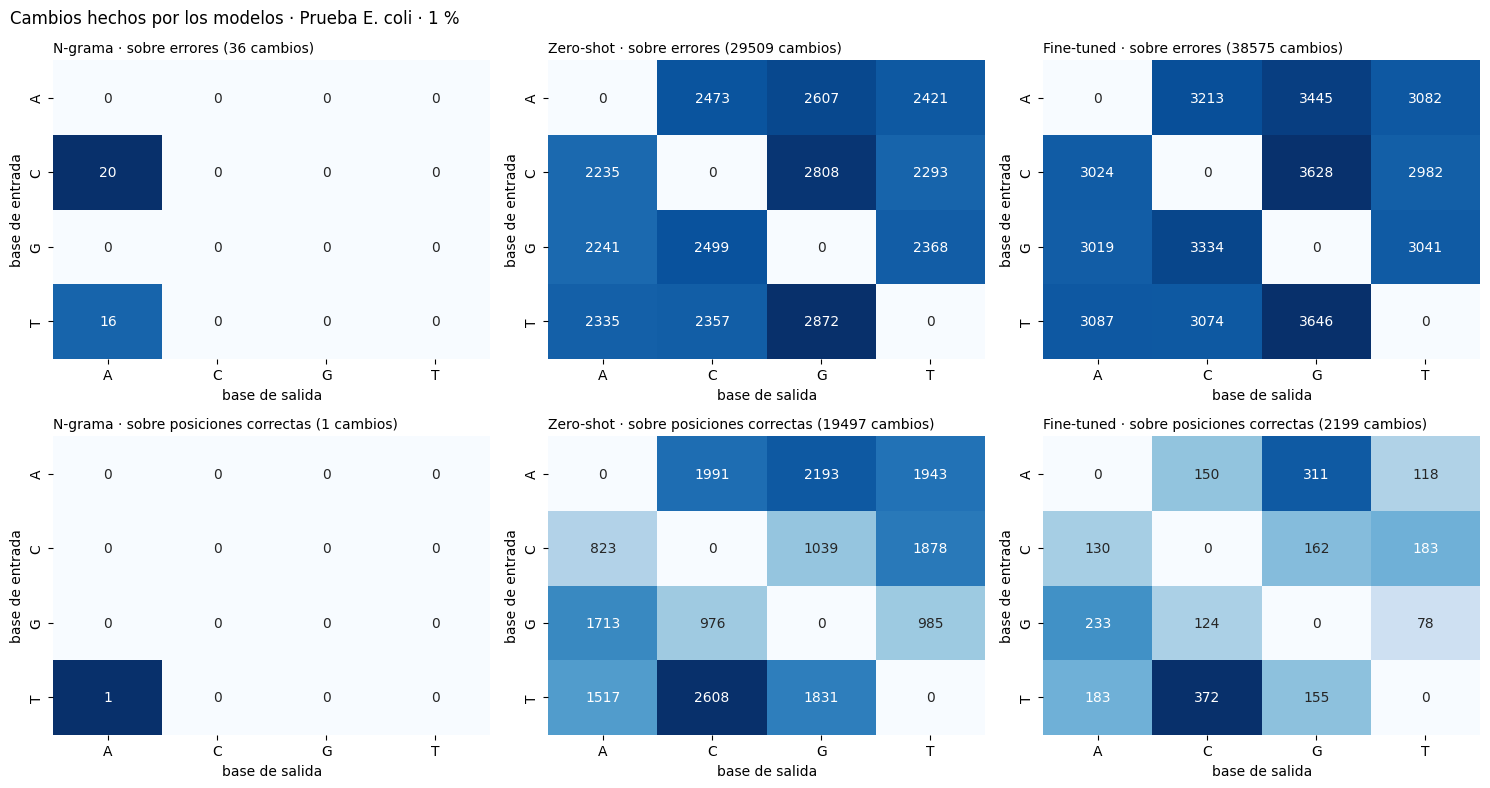

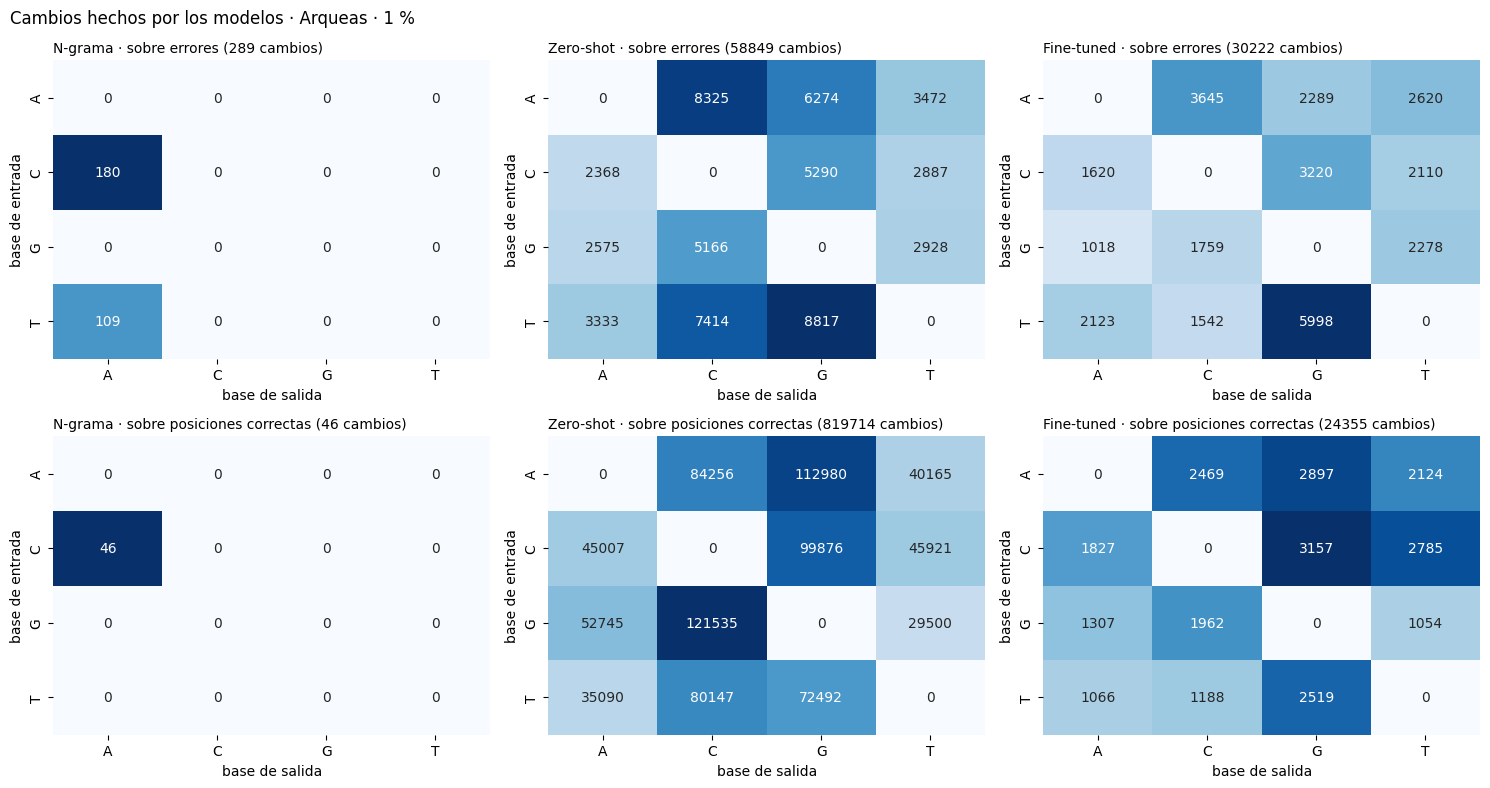

In [ ]:
# Changes made by each model at 1% errors: at error positions (top) and at correct positions, the false positives (bottom); E. coli test set and archaea
matrix_models = ["N-grama", "Zero-shot", "Fine-tuned"]
for set_name in EVAL_SETS:
    fig, axes = plt.subplots(2, len(matrix_models), figsize=(5 * len(matrix_models), 8))
    for col, m in enumerate(matrix_models):
        on_errors, on_correct = change_matrices(m, set_name, "1pct")
        for row, (kind, counts) in enumerate([("sobre errores", on_errors), ("sobre posiciones correctas", on_correct)]):
            sns.heatmap(counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[row, col])
            axes[row, col].set_title(f"{m} · {kind} ({counts.to_numpy().sum()} cambios)", loc="left", fontsize=10)
            axes[row, col].set_xlabel("base de salida")
            axes[row, col].set_ylabel("base de entrada")
    fig.suptitle(f"Cambios hechos por los modelos · {SET_NAMES[set_name]} · 1 %", x=0.01, ha="left")
    plt.tight_layout()
    plt.show()

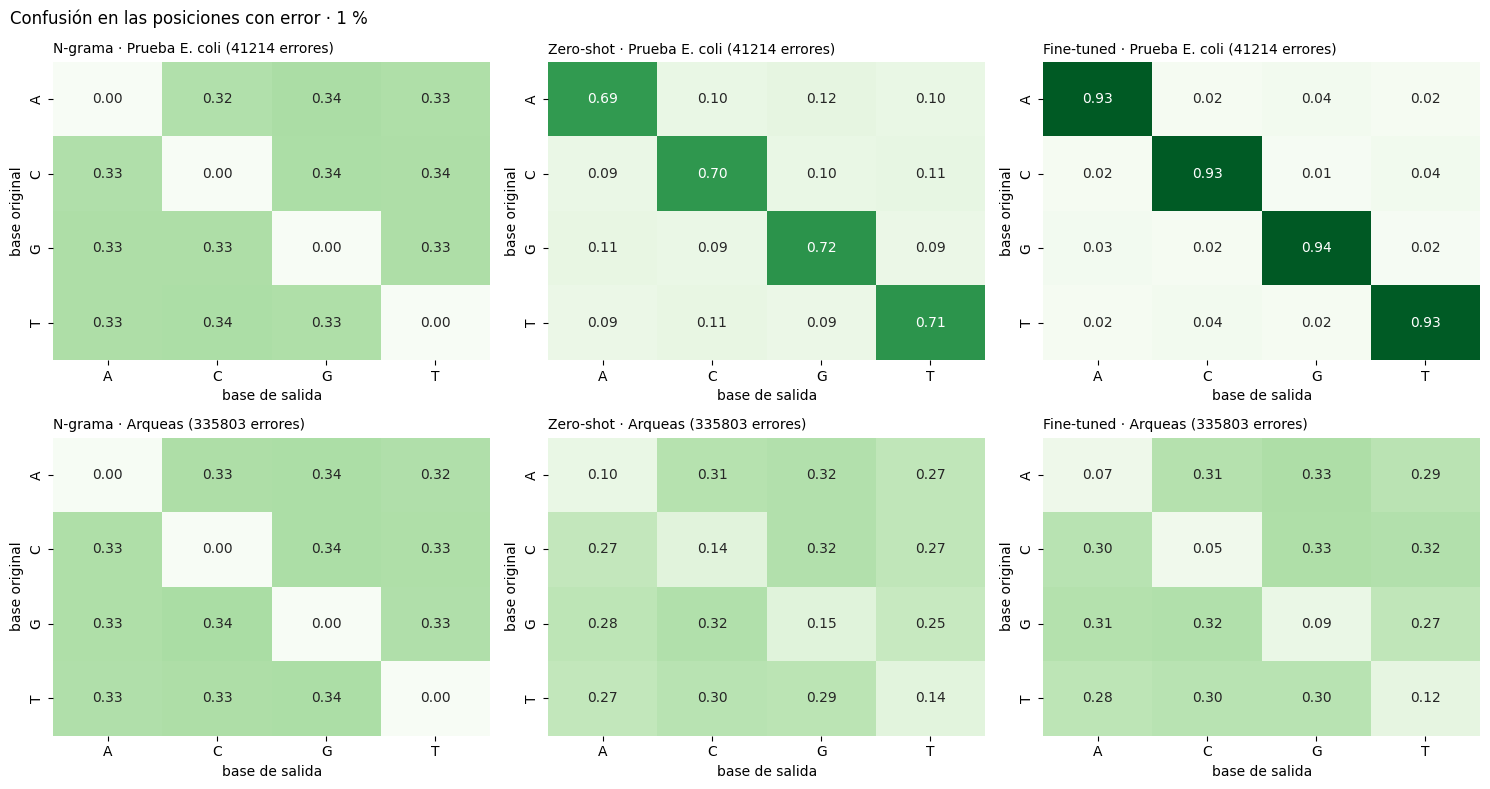

In [ ]:
# Confusion at the error positions at 1% errors, each row normalized by the errors of that original base (counts in the title); E. coli test set and archaea
fig, axes = plt.subplots(2, len(matrix_models), figsize=(5 * len(matrix_models), 8))
for row, set_name in enumerate(EVAL_SETS):
    for col, m in enumerate(matrix_models):
        confusion = error_confusion_matrix(m, set_name, "1pct")
        share = confusion.div(confusion.sum(axis=1).replace(0, np.nan), axis=0)
        sns.heatmap(share, annot=True, fmt=".2f", vmin=0, vmax=1, cmap="Greens", cbar=False, ax=axes[row, col])
        axes[row, col].set_title(f"{m} · {SET_NAMES[set_name]} ({confusion.to_numpy().sum()} errores)", loc="left", fontsize=10)
        axes[row, col].set_xlabel("base de salida")
        axes[row, col].set_ylabel("base original")
fig.suptitle("Confusión en las posiciones con error · 1 %", x=0.01, ha="left")
plt.tight_layout()
plt.show()

**Codones de inicio y de parada**

Para el codón de inicio (primeros 3 nucleótidos de cada gen) y el de parada (últimos 3):

- Sobre los errores que caen ahí: recall de detección y de corrección.
- Falsos positivos: posiciones correctas de esos codones que el modelo cambió, y su tasa sobre las posiciones correctas. Es el daño más grave, porque altera dónde empieza o termina la proteína.
- Porcentaje de genes con el codón correcto antes de corregir (lo que deja NoChange) y después, el porcentaje de genes con error en ese codón que quedan reparados y el de genes sin error que el modelo daña.

Son pocos casos por tasa (cerca de 2 codones por gen), así que además de cada tasa se reporta la fila «todas», que junta las tres tasas; los conteos se muestran para leer los porcentajes con cuidado.

In [ ]:
def boundary_codon_counts(df, compact):
    """
    Counts, for every gene, the outcomes at its start and stop codons in one noisy column.

    Parameters
    ----------
    df : pandas.DataFrame
        Genes with the clean column "seq", in the order used for the predictions.
    compact : dict
        Compact predictions of the column.

    Returns
    -------
    counts : pandas.DataFrame
        Two rows per gene, one per "boundary" ("inicio", "parada"), with "gene", "err",
        "tp", "fp", "fixed" and "residual" (wrong bases of the codon after correction).
    """
    seqs = df["seq"].tolist()
    lengths = np.array([len(s) for s in seqs])
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    orig = np.frombuffer("".join(seqs).encode(), dtype="S1")
    n_genes = len(seqs)

    pos = compact["pos"]
    ref = orig[pos]
    gene = np.searchsorted(starts, pos, side="right") - 1
    local = pos - starts[gene]
    is_error = compact["inp"] != ref
    changed = compact["out"] != compact["inp"]
    wrong = compact["out"] != ref

    frames = []
    for boundary, in_codon in [("inicio", local < 3), ("parada", local >= lengths[gene] - 3)]:
        def per_gene(mask):
            """
            Counts, for every gene, the positions of the codon selected by a mask.

            Parameters
            ----------
            mask : numpy.ndarray
                Boolean mask over the compact positions.

            Returns
            -------
            counts : numpy.ndarray
                Number of selected positions of the codon per gene, of length n_genes.
            """
            return np.bincount(gene[in_codon & mask], minlength=n_genes)
        frames.append(pd.DataFrame({
            "boundary": boundary, "gene": np.arange(n_genes),
            "err": per_gene(is_error), "tp": per_gene(is_error & changed), "fp": per_gene(~is_error & changed),
            "fixed": per_gene(is_error & ~wrong), "residual": per_gene(wrong),
        }))
    return pd.concat(frames, ignore_index=True)

In [ ]:
def boundary_codon_table(model_names, set_name):
    """
    Summarizes the start and stop codons of every model, per error rate and for all rates.

    Parameters
    ----------
    model_names : list of str
        Models to include.
    set_name : str
        Set ("test" or "arch").

    Returns
    -------
    table : pandas.DataFrame
        One row per (model, boundary, rate), with rate "todas" pooling the three rates; both
        profiles and every seed are pooled. Columns: "codons" (codons evaluated), "errors",
        "det_recall", "corr_recall", "false_positives", "fp_rate" (false positives per
        correct position of these codons), "pct_ok_before", "pct_ok_after",
        "pct_repaired" and "pct_damaged".
    """
    frames = []
    for m in model_names:
        for (rate, profile, seed), compact in EVALUATION[m]["compacts"][set_name].items():
            frames.append(boundary_codon_counts(EVAL_SETS[set_name], compact).assign(model=m, rate=rate))
    data = pd.concat(frames, ignore_index=True)
    data = pd.concat([data, data.assign(rate="todas")], ignore_index=True)
    data = data.assign(ok_before=data["err"] == 0, ok_after=data["residual"] == 0,
                       repaired=(data["err"] > 0) & (data["residual"] == 0),
                       damaged=(data["err"] == 0) & (data["residual"] > 0), with_error=data["err"] > 0)

    s = data.groupby(["model", "boundary", "rate"], sort=False)[
        ["err", "tp", "fp", "fixed", "ok_before", "ok_after", "repaired", "damaged", "with_error"]].sum()
    codons = data.groupby(["model", "boundary", "rate"], sort=False).size()
    table = pd.DataFrame({
        "codons": codons, "errors": s["err"],
        "det_recall": ratio(s["tp"], s["err"]), "corr_recall": ratio(s["fixed"], s["err"]),
        "false_positives": s["fp"], "fp_rate": ratio(s["fp"], 3 * codons - s["err"]),
        "pct_ok_before": s["ok_before"] / codons, "pct_ok_after": s["ok_after"] / codons,
        "pct_repaired": ratio(s["repaired"], s["with_error"]), "pct_damaged": ratio(s["damaged"], s["ok_before"]),
    }, index=s.index).reset_index()
    model_order = {m: i for i, m in enumerate(model_names)}
    rate_order = {r: i for i, r in enumerate(list(RATES) + ["todas"])}
    table = (table.assign(_model=table["model"].map(model_order), _rate=table["rate"].map(rate_order))
             .sort_values(["_model", "boundary", "_rate"]).drop(columns=["_model", "_rate"]))
    return table.set_index(["model", "boundary", "rate"])

In [ ]:
# Start and stop codons of each model, on the E. coli test set and on the archaea
boundary_models = ["N-grama", "Zero-shot", "Fine-tuned"]
boundary_tables = {}
for set_name in EVAL_SETS:
    boundary_tables[set_name] = boundary_codon_table(boundary_models, set_name)
    boundary_tables[set_name].to_csv(os.path.join(EVAL_DIR, f"boundary_codons_{set_name}.csv"))
    print(SET_NAMES[set_name])
    display(boundary_tables[set_name].round(4).assign(fp_rate=boundary_tables[set_name]["fp_rate"].map("{:.2e}".format)))

Prueba E. coli


codons  errors  det_recall  corr_recall  \
model      boundary rate                                              
N-grama    inicio   0.1pct    4330       8      0.1250       0.1250   
                    1pct      4330      85      0.0706       0.0706   
                    5pct      4330     429      0.1119       0.1026   
                    todas    12990     522      0.1054       0.0977   
           parada   0.1pct    4330       9      0.0000       0.0000   
                    1pct      4330     139      0.2158       0.1942   
                    5pct      4330     652      0.1963       0.1871   
                    todas    12990     800      0.1975       0.1862   
Zero-shot  inicio   0.1pct    4330       8      0.6250       0.6250   
                    1pct      4330      85      0.5765       0.5647   
                    5pct      4330     429      0.4988       0.4825   
                    todas    12990     522      0.5134       0.4981   
           parada   0.1pct    4330       9      0.1111       0.1111   
                    1pct      4330     139      0.1511       0.0288   
                    5pct      4330     652      0.1380       0.0337   
                    todas    12990     800      0.1400       0.0338   
Fine-tuned inicio   0.1pct    4330       8      0.6250       0.6250   
                    1pct      4330      85      0.7765       0.7765   
                    5pct      4330     429      0.7366       0.7203   
                    todas    12990     522      0.7414       0.7280   
           parada   0.1pct    4330       9      0.6667       0.6667   
                    1pct      4330     139      0.7626       0.7482   
                    5pct      4330     652      0.7086       0.6702   
                    todas    12990     800      0.7175       0.6838   

                            false_positives   fp_rate  pct_ok_before  \
model      boundary rate                                               
N-grama    inicio   0.1pct                0  0.00e+00         0.9982   
                    1pct                  1  7.75e-05         0.9804   
                    5pct                  0  0.00e+00         0.9039   
                    todas                 1  2.60e-05         0.9608   
           parada   0.1pct                0  0.00e+00         0.9979   
                    1pct                  0  0.00e+00         0.9681   
                    5pct                  0  0.00e+00         0.8566   
                    todas                 0  0.00e+00         0.9409   
Zero-shot  inicio   0.1pct              158  1.22e-02         0.9982   
                    1pct                150  1.16e-02         0.9804   
                    5pct                130  1.03e-02         0.9039   
                    todas               438  1.14e-02         0.9608   
           parada   0.1pct             4834  3.72e-01         0.9979   
                    1pct               4603  3.58e-01         0.9681   
                    5pct               3751  3.04e-01         0.8566   
                    todas             13188  3.46e-01         0.9409   
Fine-tuned inicio   0.1pct                0  0.00e+00         0.9982   
                    1pct                  0  0.00e+00         0.9804   
                    5pct                  0  0.00e+00         0.9039   
                    todas                 0  0.00e+00         0.9608   
           parada   0.1pct                0  0.00e+00         0.9979   
                    1pct                  0  0.00e+00         0.9681   
                    5pct                  2  1.62e-04         0.8566   
                    todas                 2  5.24e-05         0.9409   

                            pct_ok_after  pct_repaired  pct_damaged  
model      boundary rate                                             
N-grama    inicio   0.1pct        0.9984        0.1250       0.0000  
                    1pct          0.9818        0.0706       0.0000  
                    5pct    

Arqueas


codons  errors  det_recall  corr_recall  \
model      boundary rate                                              
N-grama    inicio   0.1pct   38730      66      0.1061       0.1061   
                    1pct     38730     795      0.0717       0.0566   
                    5pct     38730    3951      0.0843       0.0724   
                    todas   116190    4812      0.0825       0.0702   
           parada   0.1pct   38730     128      0.2500       0.1797   
                    1pct     38730    1133      0.2048       0.1792   
                    5pct     38730    5825      0.2130       0.1763   
                    todas   116190    7086      0.2124       0.1768   
Zero-shot  inicio   0.1pct   38730      66      0.2727       0.2576   
                    1pct     38730     795      0.2692       0.2591   
                    5pct     38730    3951      0.2478       0.2356   
                    todas   116190    4812      0.2517       0.2398   
           parada   0.1pct   38730     128      0.1406       0.0078   
                    1pct     38730    1133      0.0891       0.0018   
                    5pct     38730    5825      0.0750       0.0027   
                    todas   116190    7086      0.0785       0.0027   
Fine-tuned inicio   0.1pct   38730      66      0.5606       0.5303   
                    1pct     38730     795      0.6189       0.5987   
                    5pct     38730    3951      0.5662       0.5548   
                    todas   116190    4812      0.5748       0.5617   
           parada   0.1pct   38730     128      0.6250       0.5078   
                    1pct     38730    1133      0.6496       0.5816   
                    5pct     38730    5825      0.5638       0.4967   
                    todas   116190    7086      0.5786       0.5104   

                            false_positives   fp_rate  pct_ok_before  \
model      boundary rate                                               
N-grama    inicio   0.1pct               50  4.31e-04         0.9983   
                    1pct                 46  3.99e-04         0.9796   
                    5pct                 53  4.72e-04         0.9015   
                    todas               149  4.33e-04         0.9598   
           parada   0.1pct                0  0.00e+00         0.9967   
                    1pct                  0  0.00e+00         0.9709   
                    5pct                  0  0.00e+00         0.8572   
                    todas                 0  0.00e+00         0.9416   
Zero-shot  inicio   0.1pct              407  3.50e-03         0.9983   
                    1pct                409  3.54e-03         0.9796   
                    5pct                353  3.15e-03         0.9015   
                    todas              1169  3.40e-03         0.9598   
           parada   0.1pct            41006  3.53e-01         0.9967   
                    1pct              39506  3.43e-01         0.9709   
                    5pct              33049  2.99e-01         0.8572   
                    todas            113561  3.33e-01         0.9416   
Fine-tuned inicio   0.1pct               60  5.17e-04         0.9983   
                    1pct                 57  4.94e-04         0.9796   
                    5pct                 53  4.72e-04         0.9015   
                    todas               170  4.95e-04         0.9598   
           parada   0.1pct              121  1.04e-03         0.9967   
                    1pct                104  9.04e-04         0.9709   
                    5pct                 78  7.07e-04         0.8572   
                    todas               303  8.87e-04         0.9416   

                            pct_ok_after  pct_repaired  pct_damaged  
model      boundary rate                                             
N-grama    inicio   0.1pct        0.9972        0.1061       0.0013  
                    1pct          0.9796        0.0570       0.0012  
                    5pct    

#### 8.6.6 Arqueas y contenido de GC

Caída del desempeño fuera de dominio, relacionada con el contenido de GC de los genes. Las arqueas tienen mucho más GC (el 90 % de sus genes entre 56 % y 73 %) que *E. coli* (entre 40 % y 57 %), así que se compara la ganancia por rango de GC en los dos conjuntos.

In [ ]:
def gc_metrics(genes, model_names, r_name, bins=(0, 0.4, 0.5, 0.6, 0.7, 1.0001)):
    """
    Computes the metrics of each model by GC-content range of the genes.

    Parameters
    ----------
    genes : pandas.DataFrame
        Per-gene counts of every model.
    model_names : list of str
        Models to include.
    r_name : str
        Error rate, a key of RATES; both profiles and every seed are pooled.
    bins : tuple of float, optional
        Edges of the GC ranges.

    Returns
    -------
    table : pandas.DataFrame
        One row per (set, model, GC range) with the number of genes, the gain, the
        detection F1, the correction F1 and the oracle accuracy.
    """
    labels = [f"{lo:.0%}-{min(hi, 1):.0%}" for lo, hi in zip(bins[:-1], bins[1:])]
    data = genes[(genes["rate"] == r_name) & genes["model"].isin(model_names)].copy()
    data["gc_range"] = pd.cut(data["gc"], bins=list(bins), labels=labels, right=False).astype(str)
    summed = data.groupby(["set", "model", "gc_range"], sort=True)[["n", "err", "tp", "fp", "fixed", "oracle_fixed"]].sum()
    n_genes = data.groupby(["set", "model", "gc_range"], sort=True)["gene"].nunique()
    metrics = metrics_from_counts(summed)
    return pd.DataFrame({"genes": n_genes, **{k: metrics[k] for k in ["gain", "det_f1", "corr_f1", "oracle_accuracy"]}},
                        index=summed.index).round(4)

In [ ]:
# Gain by GC range at 1% errors, on the E. coli test set and on the archaea
gc_table = gc_metrics(all_genes, ["N-grama", "Zero-shot", "Fine-tuned"], "1pct")
gc_table.to_csv(os.path.join(EVAL_DIR, "gc_metrics.csv"))
gc_table

genes    gain  det_f1  corr_f1  oracle_accuracy
set  model      gc_range                                                 
arch Fine-tuned 0%-40%        4  0.0100  0.0872   0.0685           0.5351
                40%-50%      70 -0.0153  0.0705   0.0500           0.4963
                50%-60%     391 -0.0009  0.0947   0.0741           0.5700
                60%-70%    2484  0.0096  0.1744   0.1527           0.6871
                70%-100%    924  0.0005  0.1294   0.1147           0.6890
     N-grama    0%-40%        4  0.0000  0.0000   0.0000           0.3746
                40%-50%      70  0.0006  0.0012   0.0012           0.3366
                50%-60%     391  0.0009  0.0021   0.0018           0.3642
                60%-70%    2484  0.0006  0.0017   0.0015           0.3824
                70%-100%    924  0.0006  0.0017   0.0014           0.4063
     Zero-shot  0%-40%        4 -0.0903  0.0300   0.0120           0.5184
                40%-50%      70 -3.2353  0.0532   0.0334           0.4765
                50%-60%     391 -2.3676  0.0599   0.0401           0.5262
                60%-70%    2484 -2.3763  0.1051   0.0821           0.6393
                70%-100%    924 -2.0389  0.0920   0.0710           0.6307
test Fine-tuned 0%-40%       22  0.4986  0.7001   0.6910           0.8313
                40%-50%     123  0.8358  0.9207   0.9139           0.9795
                50%-60%     288  0.9021  0.9534   0.9488           0.9920
     N-grama    0%-40%       22  0.0037  0.0075   0.0075           0.4302
                40%-50%     123  0.0003  0.0007   0.0007           0.4435
                50%-60%     288  0.0008  0.0019   0.0017           0.4838
     Zero-shot  0%-40%       22 -0.2390  0.1016   0.0824           0.5698
                40%-50%     123  0.1586  0.5373   0.5256           0.8098
                50%-60%     288  0.2694  0.6907   0.6818           0.9392

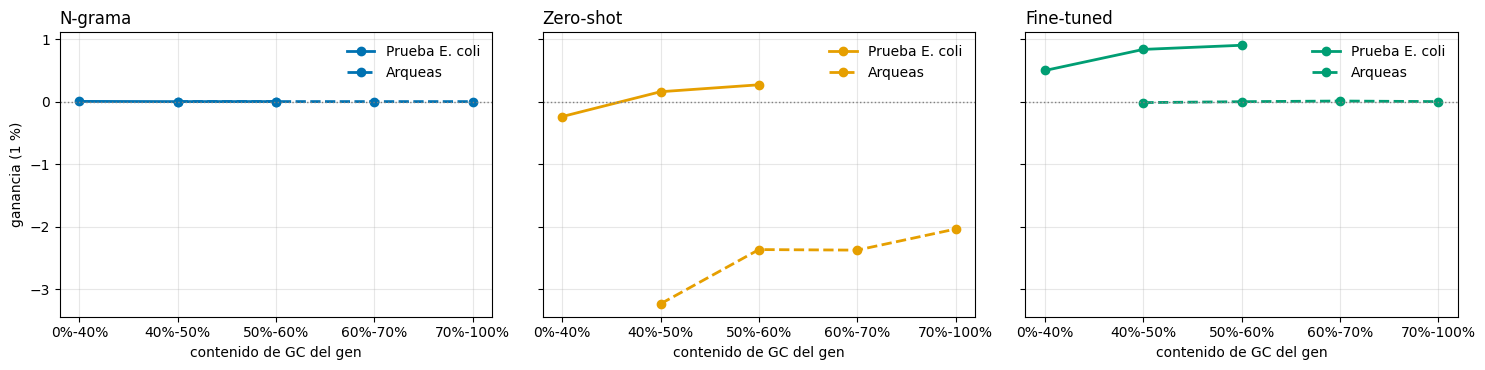

In [ ]:
# Gain by GC range of each model, E. coli test set vs. archaea (ranges with fewer than 20 genes are not plotted)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, m in zip(axes, ["N-grama", "Zero-shot", "Fine-tuned"]):
    for set_name, style in [("test", "-"), ("arch", "--")]:
        subset = gc_table.loc[(set_name, m)]
        subset = subset[subset["genes"] >= 20]
        ax.plot(subset.index, subset["gain"], marker="o", linewidth=2, linestyle=style,
                color=MODEL_COLORS[m], label=SET_NAMES[set_name])
    ax.axhline(0, color="gray", linewidth=1, linestyle=":")
    ax.set_title(m, loc="left")
    ax.set_xlabel("contenido de GC del gen")
    ax.grid(alpha=0.3)
    ax.legend(frameon=False)
axes[0].set_ylabel("ganancia (1 %)")
plt.tight_layout()
plt.show()

#### 8.6.7 Falsos positivos

Posiciones correctas que el modelo cambió. Se revisa si el modelo tiende a «corregir» codones poco frecuentes pero válidos hacia codones más comunes, es decir, si confunde la variación natural con un error. La frecuencia de cada codón se toma de los genes de entrenamiento.

La última celda compara la parte de transiciones de los falsos positivos con la que se esperaría por el código genético, y repite el resumen para las arqueas.

In [ ]:
# Codon usage of the training genes (in reading frame), used to tell whether a false positive moves a codon to a more common one
codon_usage = Counter(s[i:i + 3] for s in train_df["seq"] for i in range(0, len(s), 3))

In [ ]:
def false_positive_table(df, compact):
    """
    Lists the correct positions that the model changed, with the codon before and after.

    Parameters
    ----------
    df : pandas.DataFrame
        Genes with the clean column "seq", in the order used for the predictions.
    compact : dict
        Compact predictions of one noisy column.

    Returns
    -------
    false_positives : pandas.DataFrame
        One row per false positive with "codon_original", "codon_proposed" (the original
        codon with only this base changed), "codon_position", "synonymous", "to_stop" and
        "to_more_common" (the proposed codon is more frequent in training).
    """
    seqs = df["seq"].tolist()
    lengths = np.array([len(s) for s in seqs])
    starts = np.concatenate([[0], np.cumsum(lengths)[:-1]])
    joined = "".join(seqs)
    orig = np.frombuffer(joined.encode(), dtype="S1")

    mask = (compact["inp"] == orig[compact["pos"]]) & (compact["out"] != compact["inp"])
    pos, out = compact["pos"][mask], compact["out"][mask].astype(str)
    gene = np.searchsorted(starts, pos, side="right") - 1
    local = pos - starts[gene]

    rows = []
    for p, o, loc in zip(pos, out, local):
        k = loc % 3
        codon_original = joined[p - k:p - k + 3]
        codon_proposed = codon_original[:k] + o + codon_original[k + 1:]
        rows.append({
            "codon_original": codon_original,
            "codon_proposed": codon_proposed,
            "codon_position": k + 1,
            "synonymous": substitution_effect(codon_original, codon_proposed, loc < 3) == "sinónimo",
            "to_stop": GENETIC_CODE[codon_proposed] == "*",
            "to_more_common": codon_usage[codon_proposed] > codon_usage[codon_original],
        })
    return pd.DataFrame(rows, columns=["codon_original", "codon_proposed", "codon_position",
                                       "synonymous", "to_stop", "to_more_common"])

In [ ]:
# False positives of each model at 1% errors on the E. coli test set (5 seeds and both profiles pooled)
fp_rows, fp_tables = [], {}
for m in ["N-grama", "Zero-shot", "Fine-tuned"]:
    fp = pd.concat([false_positive_table(test_df, c) for (r, p, s), c in EVALUATION[m]["compacts"]["test"].items()
                    if r == "1pct"], ignore_index=True)
    fp_tables[m] = fp
    fp_rows.append({"model": m, "false_positives": len(fp),
                    "pct_synonymous": fp["synonymous"].mean(), "pct_to_stop": fp["to_stop"].mean(),
                    "pct_to_more_common": fp["to_more_common"].mean(),
                    **{f"pct_codon_position_{k}": (fp["codon_position"] == k).mean() for k in (1, 2, 3)}})
pd.DataFrame(fp_rows).set_index("model").round(4)

,false_positives,pct_synonymous,pct_to_stop,pct_to_more_common,pct_codon_position_1,pct_codon_position_2,pct_codon_position_3
model,,,,,,,
N-grama,1,1.0000,0.0000,1.0000,1.0000,0.0000,0.0000
Zero-shot,19497,0.4594,0.0129,0.6904,0.2600,0.2090,0.5310
Fine-tuned,2199,0.4798,0.0036,0.5821,0.2369,0.2133,0.5498


In [ ]:
# Most frequent changes of the fine-tuned model's false positives, with the training frequency of each codon
fp_pairs = fp_tables["Fine-tuned"].groupby(["codon_original", "codon_proposed"]).size().rename("false_positives")
fp_pairs = fp_pairs.sort_values(ascending=False).head(10).reset_index()
fp_pairs["usage_original"] = fp_pairs["codon_original"].map(codon_usage)
fp_pairs["usage_proposed"] = fp_pairs["codon_proposed"].map(codon_usage)
fp_pairs

,codon_original,codon_proposed,false_positives,usage_original,usage_proposed
0,TTG,CTG,45,14488,56246
1,GTT,GTC,38,19313,16198
2,ACT,ACC,30,9310,24819
3,CGC,CGT,30,23482,22319
4,TTA,TTG,27,14618,14488
5,GAG,GAA,25,18853,42259
6,GAT,GAG,25,34036,18853
7,AAG,AAA,24,10759,35606
8,CAA,CAG,24,16289,30850
9,ATG,GTG,24,29637,27934


In [ ]:
# Transitions among the possible single-base changes of the training codons, split by effect, compared with the false positives of the fine-tuned model at 1% errors (E. coli test set and archaea)
TRANSITIONS = {("A", "G"), ("G", "A"), ("C", "T"), ("T", "C")}


def transition_share_by_effect(usage):
    """
    Computes which share of the possible single-base changes are transitions, by effect.

    Every codon is mutated at each of its three positions to each of the three other bases,
    and each change is weighted by how often the original codon appears. The changes are
    split into synonymous (the codon keeps its amino acid, or stays a stop codon) and
    non-synonymous (any other change, including changes to or from a stop codon).

    Parameters
    ----------
    usage : collections.Counter
        Number of times each codon appears, e.g. codon_usage of the training genes.

    Returns
    -------
    shares : dict
        {"sinónimos": share, "no sinónimos": share}, each the weighted fraction of the
        changes of that group that are transitions (A<->G or C<->T).
    """
    totals = {True: 0, False: 0}
    transitions = {True: 0, False: 0}
    for codon, count in usage.items():
        for k in range(3):
            for base in "ACGT":
                if base == codon[k]:
                    continue
                mutated = codon[:k] + base + codon[k + 1:]
                synonymous = GENETIC_CODE[mutated] == GENETIC_CODE[codon]
                totals[synonymous] += count
                transitions[synonymous] += count * ((codon[k], base) in TRANSITIONS)
    return {"sinónimos": transitions[True] / totals[True], "no sinónimos": transitions[False] / totals[False]}


def is_transition(fp):
    """
    Tells, for every false positive, whether the changed base is a transition.

    Parameters
    ----------
    fp : pandas.DataFrame
        False positives as returned by false_positive_table.

    Returns
    -------
    transition : pandas.Series of bool
        True where the original and the proposed base form a transition.
    """
    k = fp["codon_position"] - 1
    pairs = [(o[i], p[i]) for o, p, i in zip(fp["codon_original"], fp["codon_proposed"], k)]
    return pd.Series([pair in TRANSITIONS for pair in pairs], index=fp.index)


shares = transition_share_by_effect(codon_usage)
fp_test = fp_tables["Fine-tuned"]
fp_arch = pd.concat([false_positive_table(EVAL_SETS["arch"], c)
                     for (r, p, s), c in EVALUATION["Fine-tuned"]["compacts"]["arch"].items() if r == "1pct"],
                    ignore_index=True)
p_syn = fp_test["synonymous"].mean()
expected = p_syn * shares["sinónimos"] + (1 - p_syn) * shares["no sinónimos"]
print(f"Cambios de una base posibles en los codones de entrenamiento: transiciones entre los sinónimos "
      f"{shares['sinónimos']:.1%}, entre los no sinónimos {shares['no sinónimos']:.1%}")
print(f"Falsos positivos del modelo ajustado en E. coli (1 %): {len(fp_test)} | sinónimos {p_syn:.1%} | "
      f"transiciones esperadas con esa mezcla {expected:.1%} | observadas {is_transition(fp_test).mean():.1%}")
print(f"Falsos positivos del modelo ajustado en arqueas (1 %): {len(fp_arch)} | sinónimos "
      f"{fp_arch['synonymous'].mean():.1%} | transiciones {is_transition(fp_arch).mean():.1%}")

Cambios de una base posibles en los codones de entrenamiento: transiciones entre los sinónimos 49.1%, entre los no sinónimos 28.5%
Falsos positivos del modelo ajustado en E. coli (1 %): 2199 | sinónimos 48.0% | transiciones esperadas con esa mezcla 38.4% | observadas 50.0%
Falsos positivos del modelo ajustado en arqueas (1 %): 24355 | sinónimos 7.6% | transiciones 33.6%


#### 8.6.8 Matriz de tasa de entrenamiento × tasa de evaluación

Ganancia de los 6 modelos finales (uno por tasa y perfil de entrenamiento) en cada configuración de prueba, para ver, por ejemplo, si un modelo entrenado con muchos errores sobrecorrige cuando los errores reales son escasos. `MATRIX_SEEDS` controla cuántas semillas de prueba se usan (5 por defecto; con menos el costo baja, pero la tabla lo indica). El modelo elegido reutiliza la caché de 8.5. Al lado se muestra la misma matriz en validación, con la que se eligió el modelo.

In [ ]:
# Evaluate the 6 final fine-tuned models on the test columns (GPU; every column is cached, the chosen model's columns come from 8.5)
MATRIX_SEEDS = N_TEST_SEEDS
matrix_columns = {k: c for k, c in TEST_COLUMNS.items() if k[2] < MATRIX_SEEDS}
matrix_model = LoraModel(GenerannoCorrector(copy.deepcopy(encoder)), rank=BEST_RANK)
matrix_predict = generanno_predictor(matrix_model, BATCH_SIZE)
matrix_rows = []
for name, run in final_runs.items():
    model_name = "Fine-tuned" if name == best_generanno_name else f"Fine-tuned {name}"
    matrix_model.load_state_dict(torch.load(run["path"]), strict=False)
    compacts = cached_predictions(matrix_predict, test_df, matrix_columns, model_name, "test", fine_tuned_tag(name))
    train_rate, train_profile = name.split("_")[:2]
    for (r_name, profile, seed), compact in compacts.items():
        matrix_rows.append({"train_rate": train_rate, "train_profile": train_profile, "rate": r_name,
                            "profile": profile, "seed": seed, "gain": compact["gain"], "auprc": compact["auprc"]})
del matrix_model, matrix_predict
pygc.collect()
if torch.cuda.is_available(): torch.cuda.empty_cache()
matrix_table = pd.DataFrame(matrix_rows)
matrix_table.to_csv(os.path.join(EVAL_DIR, "train_eval_matrix.csv"), index=False)

In [ ]:
def train_eval_matrix(table, value="gain"):
    """
    Pivots a metric into a training configuration × evaluation configuration matrix.

    Parameters
    ----------
    table : pandas.DataFrame
        Rows with "train_rate", "train_profile", "rate", "profile" and the metric; seeds
        are averaged.
    value : str, optional
        Metric to show.

    Returns
    -------
    matrix : pandas.DataFrame
        Rows are training configurations and columns evaluation configurations, both
        ordered as RATES and PROFILES.
    """
    order = [f"{r} {p}" for r in RATES for p in PROFILES]
    data = table.assign(train=table["train_rate"] + " " + table["train_profile"],
                        evaluation=table["rate"] + " " + table["profile"])
    matrix = data.pivot_table(index="train", columns="evaluation", values=value, aggfunc="mean")
    return matrix.reindex(index=order, columns=order)

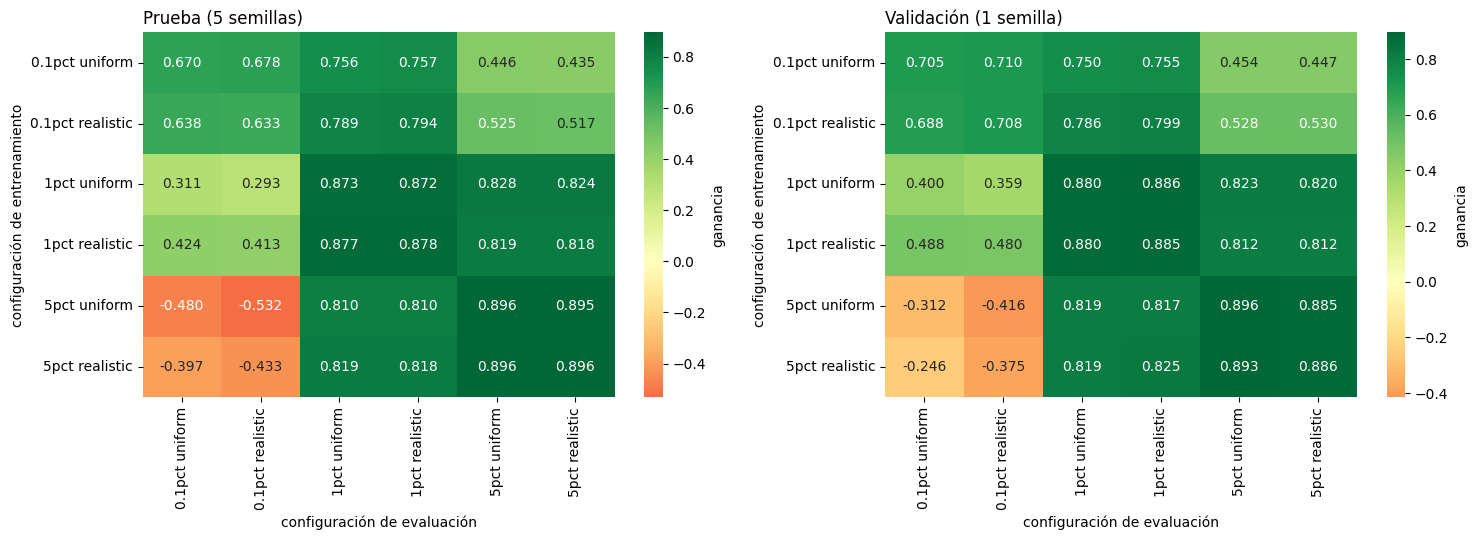

In [ ]:
# Gain matrix on test (seeds averaged) next to the same matrix on validation, the one used to choose the model
validation_matrix_table = generanno_val_table.assign(
    train_rate=generanno_val_table["model"].str.split("_").str[0],
    train_profile=generanno_val_table["model"].str.split("_").str[1])
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, (title, table) in zip(axes, [(f"Prueba ({MATRIX_SEEDS} semilla{'s' if MATRIX_SEEDS > 1 else ''})", matrix_table),
                                     ("Validación (1 semilla)", validation_matrix_table)]):
    sns.heatmap(train_eval_matrix(table), annot=True, fmt=".3f", cmap="RdYlGn", center=0, ax=ax,
                cbar_kws={"label": "ganancia"})
    ax.set_title(title, loc="left")
    ax.set_xlabel("configuración de evaluación")
    ax.set_ylabel("configuración de entrenamiento")
plt.tight_layout()
plt.show()

In [ ]:
# Mean test gain of each final model over the 6 evaluation configurations, and how far the test matrix is from the validation one
test_matrix = train_eval_matrix(matrix_table)
validation_matrix = train_eval_matrix(validation_matrix_table)
print("Ganancia media en prueba de cada modelo final (6 configuraciones):")
print(test_matrix.mean(axis=1).sort_values(ascending=False).round(3).to_string())
print(f"\nDiferencia absoluta media entre las celdas de prueba y de validación: "
      f"{(test_matrix - validation_matrix).abs().values.mean():.3f}")

Ganancia media en prueba de cada modelo final (6 configuraciones):
train
1pct realistic      0.705
1pct uniform        0.667
0.1pct realistic    0.649
0.1pct uniform      0.624
5pct realistic      0.433
5pct uniform        0.400

Diferencia absoluta media entre las celdas de prueba y de validación: 0.031


#### 8.6.9 Intervalos de confianza y criterio de éxito

Intervalos del 95 % por bootstrap de genes (1000 réplicas; cada gen entra con todas sus posiciones y sus 5 semillas) y diferencia pareada entre el modelo ajustado y el n-grama, con los mismos genes remuestreados para los dos modelos. Los estimados juntan las 5 semillas, así que pueden diferir levemente de las medias de 8.6.1.

In [ ]:
# Bootstrap intervals of the gain and of the detection and correction F1 of the fine-tuned model and the n-gram, and of their paired difference, on the E. coli test set and on the archaea
ci_tables = {}
for set_name in EVAL_SETS:
    ci_tables[set_name] = bootstrap_ci(all_genes, ["N-grama", "Fine-tuned"], set_name, reference="N-grama")
    ci_tables[set_name].to_csv(os.path.join(EVAL_DIR, f"bootstrap_{set_name}.csv"), index=False)
ci_tables["test"].round(4)

,model,rate,profile,metric,estimate,low,high,excludes_zero
0,Fine-tuned,0.1pct,uniform,gain,0.4250,0.3252,0.5113,None
1,Fine-tuned,0.1pct,uniform,det_f1,0.7682,0.7370,0.7972,None
2,Fine-tuned,0.1pct,uniform,corr_f1,0.7650,0.7338,0.7936,None
3,Fine-tuned,0.1pct,realistic,gain,0.4134,0.3183,0.5060,None
4,Fine-tuned,0.1pct,realistic,det_f1,0.7656,0.7362,0.7958,None
5,Fine-tuned,0.1pct,realistic,corr_f1,0.7624,0.7334,0.7923,None
6,Fine-tuned,1pct,uniform,gain,0.8768,0.8613,0.8906,None
7,Fine-tuned,1pct,uniform,det_f1,0.9404,0.9326,0.9475,None
8,Fine-tuned,1pct,uniform,corr_f1,0.9356,0.9275,0.9430,None
9,Fine-tuned,1pct,realistic,gain,0.8781,0.8629,0.8918,None


In [ ]:
# Success criterion: positive gain at every test rate, detection and correction F1 above the n-gram with an interval that excludes 0, and positive gain on the archaea
test_ci, arch_ci = ci_tables["test"], ci_tables["arch"]
difference = "Fine-tuned − N-grama"
criteria = {
    "ganancia > 0 en todas las tasas de prueba (IC inferior > 0)":
        (test_ci.query("model == 'Fine-tuned' and metric == 'gain'")["low"] > 0).all(),
    "F1 detección > n-grama (IC de la diferencia sin 0)":
        (test_ci.query("model == @difference and metric == 'det_f1'")["low"] > 0).all(),
    "F1 corrección > n-grama (IC de la diferencia sin 0)":
        (test_ci.query("model == @difference and metric == 'corr_f1'")["low"] > 0).all(),
    "ganancia > 0 en arqueas (IC inferior > 0)":
        (arch_ci.query("model == 'Fine-tuned' and metric == 'gain'")["low"] > 0).all(),
}
for name, passed in criteria.items():
    print(f"{'✔' if passed else '✘'} {name}")

✔ ganancia > 0 en todas las tasas de prueba (IC inferior > 0)
✔ F1 detección > n-grama (IC de la diferencia sin 0)
✔ F1 corrección > n-grama (IC de la diferencia sin 0)
✘ ganancia > 0 en arqueas (IC inferior > 0)


In [ ]:
# Save every table shown in section 8 to Drive (CSV) for the report; nothing is recomputed on the GPU, everything comes from the results already in memory
TABLE_DIR = os.path.join(EVAL_DIR, "tables")
os.makedirs(TABLE_DIR, exist_ok=True)

def save_table(table, name):
    """
    Saves one table to TABLE_DIR as a CSV file.

    Parameters
    ----------
    table : pandas.DataFrame
        Table to save.
    name : str
        File name, without extension.
    """
    table.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"))

for set_name in EVAL_SETS:
    save_table(mean_std_table(all_configs, MAIN_METRICS, set_name), f"8.6.1_general_{set_name}")
    save_table(mean_std_table(oracle_configs, ORACLE_METRICS, set_name), f"8.6.2_oraculo_{set_name}")
    save_table(mean_std_table(all_configs, GENE_METRICS, set_name), f"8.6.3_nivel_gen_{set_name}")
    save_table(mean_std_table(all_configs, CODON_METRICS, set_name), f"8.6.4_nivel_codon_{set_name}")
    save_table(mean_std_table(position_table, POSITION_METRICS, set_name, by=("model", "rate", "position")),
               f"8.6.4_posicion_codon_{set_name}")
    for m in matrix_models:
        on_errors, on_correct = change_matrices(m, set_name, "1pct")
        save_table(on_errors, f"8.6.5_cambios_sobre_errores_{m}_{set_name}")
        save_table(on_correct, f"8.6.5_cambios_sobre_correctas_{m}_{set_name}")
        save_table(error_confusion_matrix(m, set_name, "1pct"), f"8.6.5_confusion_errores_{m}_{set_name}")
for by in ["effect", "location", "substitution"]:
    save_table(category_summary(category_models, "test", "1pct", by).unstack("model"), f"8.6.5_categoria_{by}_test")
save_table(pd.DataFrame(fp_rows).set_index("model").round(4), "8.6.7_falsos_positivos_resumen_test")
save_table(fp_pairs, "8.6.7_falsos_positivos_pares_finetuned_test")
save_table(train_eval_matrix(matrix_table), "8.6.8_matriz_ganancia_prueba")
save_table(train_eval_matrix(validation_matrix_table), "8.6.8_matriz_ganancia_validacion")
save_table(pd.Series(criteria, name="cumple").rename_axis("criterio"), "8.6.9_criterio_exito")
print(f"{len(os.listdir(TABLE_DIR))} tablas guardadas en {TABLE_DIR}")

36 tablas guardadas en /content/drive/MyDrive/proyecto-nlp/evaluation/tables


### 8.7 Figuras del artículo

Las figuras de resultados del artículo, generadas con los resultados de esta sección (`all_configs` y la matriz de 8.6.8), sin recalcular nada: etiquetas en español, perfil realista y una escala que no deja que los valores muy negativos del zero-shot aplasten al resto (se marcan con un triángulo y su valor).

- **Ganancia frente a la tasa de error** (Fig. 2 del artículo).
- **Recall de detección y sobrecorrección por posición en el codón** (Fig. 3 del artículo).
- **Matriz de tasa de entrenamiento × tasa de evaluación** (Fig. 4 del artículo).


In [ ]:
# Style of the article figures: Spanish labels, a Times-like serif font bundled with matplotlib (STIX) and the Okabe-Ito colors
ARTICLE_STYLE = {"font.family": "STIXGeneral", "mathtext.fontset": "stix", "font.size": 8, "axes.titlesize": 8,
                 "axes.labelsize": 8, "legend.fontsize": 7, "xtick.labelsize": 7, "ytick.labelsize": 7}
ARTICLE_NAMES = {"NoChange": "Sin cambios", "Frequency": "Frecuencia (oráculo)", "N-grama": "N-gramas",
                 "Zero-shot": "Zero-shot", "Fine-tuned": "Ajustado"}
ARTICLE_LOOK = {"Fine-tuned": ("#009E73", "o", "-"), "Zero-shot": ("#E69F00", "s", "-"), "N-grama": ("#0072B2", "^", "-"),
                "Frequency": ("#CC79A7", "D", "--"), "NoChange": ("#7f7f7f", "x", ":")}
RATE_LABELS = {"0.1pct": "0.1 %", "1pct": "1 %", "5pct": "5 %"}
PROFILE_SHORT = {"uniform": "unif.", "realistic": "real."}


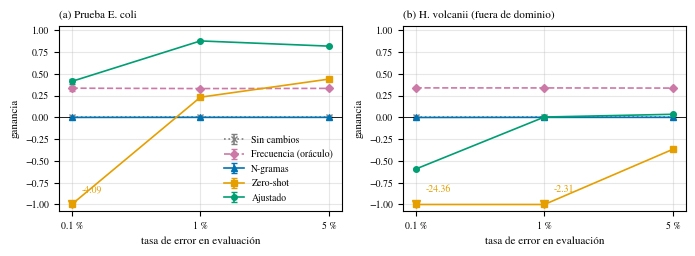

In [ ]:
def plot_article_gain(configs, set_name, title, ax, y_min=-1.0):
    """
    Plots the gain of every model against the evaluation error rate, realistic profile.

    Values below y_min (the zero-shot at low rates) are drawn at y_min with a triangle and
    their value, so the scale stays readable for the other models.

    Parameters
    ----------
    configs : pandas.DataFrame
        Metrics per configuration of every model (all_configs).
    set_name : str
        Set ("test" or "arch").
    title : str
        Panel title.
    ax : matplotlib.axes.Axes
        Axes to draw on.
    y_min : float, optional
        Lowest value shown on the y axis.
    """
    x = np.arange(len(RATES))
    for m in ["NoChange", "Frequency", "N-grama", "Zero-shot", "Fine-tuned"]:
        data = configs[(configs["model"] == m) & (configs["set"] == set_name) & (configs["profile"] == "realistic")]
        stats = data.groupby("rate")["gain"].agg(["mean", "std"]).reindex(list(RATES))
        color, marker, line = ARTICLE_LOOK[m]
        ax.errorbar(x, stats["mean"].clip(y_min, None), yerr=stats["std"].where(stats["mean"] > y_min),
                    color=color, marker=marker, ls=line, lw=1.2, ms=4, capsize=2, label=ARTICLE_NAMES[m])
        for xi, value in zip(x, stats["mean"]):
            if value < y_min:
                ax.plot(xi, y_min, marker="v", color=color, ms=6)
                ax.annotate(f"{value:.2f}", (xi, y_min), xytext=(7, 9), textcoords="offset points", color=color, fontsize=7)
    ax.axhline(0, color="black", lw=0.6)
    ax.set_xticks(x)
    ax.set_xticklabels([RATE_LABELS[r] for r in RATES])
    ax.set_ylim(y_min - 0.08, 1.05)
    ax.set_xlabel("tasa de error en evaluación")
    ax.set_ylabel("ganancia")
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.3)


# Article figure: gain against the evaluation error rate on the E. coli test set and on the archaea (realistic profile)
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.6))
    plot_article_gain(all_configs, "test", "(a) Prueba E. coli", axes[0])
    plot_article_gain(all_configs, "arch", "(b) H. volcanii (fuera de dominio)", axes[1])
    axes[0].legend(frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()

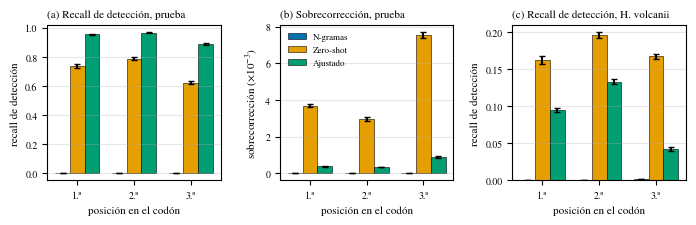

In [ ]:
def plot_article_position(configs, set_name, metric, title, ax, scale=1.0, ylabel=None):
    """
    Plots a metric per codon position at 1 % errors as grouped bars, one bar per model.

    Both profiles and the 5 seeds are pooled; the error bars are the standard deviation over
    those 10 configurations.

    Parameters
    ----------
    configs : pandas.DataFrame
        Metrics per configuration of every model (all_configs).
    set_name : str
        Set ("test" or "arch").
    metric : str
        Metric computed per codon position (the "c1_", "c2_" and "c3_" columns).
    title : str
        Panel title.
    ax : matplotlib.axes.Axes
        Axes to draw on.
    scale : float, optional
        Factor applied to the values (e.g. 1e3 to show the overcorrection × 10^-3).
    ylabel : str, optional
        Label of the y axis; defaults to the metric name.
    """
    data = configs[(configs["set"] == set_name) & (configs["rate"] == "1pct")]
    models, width = ["N-grama", "Zero-shot", "Fine-tuned"], 0.26
    for j, m in enumerate(models):
        rows = data[data["model"] == m]
        means = [rows[f"c{k}_{metric}"].mean() * scale for k in (1, 2, 3)]
        stds = [rows[f"c{k}_{metric}"].std() * scale for k in (1, 2, 3)]
        ax.bar(np.arange(3) + (j - 1) * width, means, width, yerr=stds, capsize=2, color=ARTICLE_LOOK[m][0],
               label=ARTICLE_NAMES[m], edgecolor="black", lw=0.4)
    ax.set_xticks(range(3))
    ax.set_xticklabels(["1.ª", "2.ª", "3.ª"])
    ax.set_xlabel("posición en el codón")
    ax.set_ylabel(ylabel or metric)
    ax.set_title(title, loc="left")
    ax.grid(alpha=0.3, axis="y")


# Article figure: detection recall and overcorrection per codon position at 1% errors, E. coli test set and archaea
with plt.rc_context(ARTICLE_STYLE):
    fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.3))
    plot_article_position(all_configs, "test", "det_recall", "(a) Recall de detección, prueba", axes[0],
                          ylabel="recall de detección")
    plot_article_position(all_configs, "test", "overcorrection", "(b) Sobrecorrección, prueba", axes[1], scale=1e3,
                          ylabel=r"sobrecorrección ($\times 10^{-3}$)")
    plot_article_position(all_configs, "arch", "det_recall", "(c) Recall de detección, H. volcanii", axes[2],
                          ylabel="recall de detección")
    axes[1].legend(frameon=False, loc="upper left", fontsize=6.5)
    plt.tight_layout()
    plt.show()

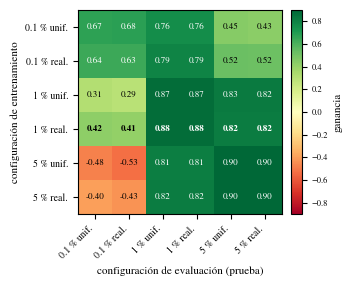

In [ ]:
# Article figure: test gain of the 6 final models in every evaluation configuration, the chosen model in bold
article_matrix = train_eval_matrix(matrix_table)
labels = [f"{RATE_LABELS[c.split()[0]]} {PROFILE_SHORT[c.split()[1]]}" for c in article_matrix.columns]
with plt.rc_context(ARTICLE_STYLE):
    fig, ax = plt.subplots(figsize=(3.5, 2.9))
    image = ax.imshow(article_matrix.values, cmap="RdYlGn", vmin=-0.9, vmax=0.9)
    chosen = f"{best_generanno_name.split('_')[0]} {best_generanno_name.split('_')[1]}"
    for i, row_name in enumerate(article_matrix.index):
        for j in range(article_matrix.shape[1]):
            value = article_matrix.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=6.5,
                    color="white" if abs(value) > 0.6 else "black", fontweight="bold" if row_name == chosen else "normal")
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)))
    ax.set_yticklabels(labels)
    ax.set_xlabel("configuración de evaluación (prueba)")
    ax.set_ylabel("configuración de entrenamiento")
    colorbar = plt.colorbar(image, ax=ax, fraction=0.046, pad=0.04)
    colorbar.set_label("ganancia")
    colorbar.ax.tick_params(labelsize=6)
    plt.tight_layout()
    plt.show()

## 9. Análisis de resultados y conclusiones

**Resultados principales (8.6.1 y 8.6.9).** El modelo ajustado obtuvo la mayor ganancia en todas las tasas de *E. coli*: 0.413 con el 0.1 %, 0.878 con el 1 % y 0.818 con el 5 % (perfil realista; el uniforme difiere en menos de 0.012). Superó al n-grama en F1 de detección y de corrección con intervalos de confianza que excluyen el 0, mientras que el n-grama casi no hizo cambios y el zero-shot tuvo ganancia negativa con el 0.1 % por cambiar demasiadas posiciones correctas.

**Qué aporta el ajuste fino (8.6.1 y 8.6.2).** Con detección perfecta, el zero-shot ya elige la base correcta en el 90.5 % de los errores: el preentrenamiento sabe qué base encaja en cada contexto, pero no cuándo cambiarla. El ajuste fino redujo la sobrecorrección cerca de 9 veces y subió la exactitud con oráculo al 98.5 %; casi todo lo que el modelo deja de corregir se pierde en la detección.

**La tasa de error importa (8.6.1 y 8.6.8).** El modelo cambia un número casi constante de posiciones correctas (unas 220 por versión del conjunto de prueba), así que, cuando hay pocos errores, esos cambios pesan mucho más en la ganancia. Cada modelo funciona mejor cerca de la tasa con la que se entrenó; el de 1 % realista es el mejor cuando la tasa no se conoce.

**Qué aprendió del lenguaje del ADN (8.6.4, 8.6.5 y 8.6.7).** Detecta casi todos los errores que crean un codón de parada (98.5 %) y menos los sinónimos (85.6 %), que no cambian la proteína, igual que los errores ortográficos que producen otra palabra válida. Sus cambios indebidos se concentran en la tercera posición del codón y tienden a reemplazar codones poco frecuentes por otros más comunes.

**Fuera de dominio (8.6.6).** En *H. volcanii* el modelo detectó menos del 10 % de los errores y su ganancia fue negativa con el 0.1 % (−0.593), aunque con detección perfecta acertó el 67.4 %: su criterio para decidir qué es un error quedó calibrado para *E. coli*, cuyo contenido de GC es muy distinto.

**Criterios de éxito.** Se cumplieron 2 de 3: ganancia mayor que 0 en todas las tasas y perfiles de *E. coli*, y superioridad sobre el n-grama en F1 de detección y de corrección. No se cumplió la ganancia positiva en arqueas.

**Limitaciones y trabajo futuro.** Solo se simularon sustituciones sobre secuencias de referencia de una sola cepa, así que no se pudo medir el efecto sobre variación natural real (SNPs). Las mejoras más directas son un umbral sobre el puntaje de sospecha para reducir los cambios indebidos con tasas bajas, entrenar con una mezcla de tasas y adaptar el modelo a otros organismos.
